In [1]:
import pandas as pd
from itables import init_notebook_mode
import polars as pl
import os
import numpy as np
init_notebook_mode(all_interactive=True)
import polars.selectors as cs
import plotnine as pn



In [2]:
import sys
sys.path.append("/home/a379i/Scripts")   # path to folder containing the python file

from utils.load_gtf_cgc_dresden import *
from ProteinExpression.load_pr_data import *
from Variants.add_missing_acmg import *


In [3]:

non_coding_consequence_list = ["consequence_intron_variant", "consequence_upstream_gene_variant", 
                    "consequence_downstream_gene_variant", "consequence_3_prime_utr_variant"]


coding_consequence_list = [
    # HIGH impacts
    'transcript_ablation',
    'stop_gained',
    'stop_lost',
    'missense_variant',
    'frameshift_variant',
    'splice_acceptor_variant',
    'splice_donor_variant',
    'transcript_amplification',
    'start_lost',
    'feature_elongation',
    'feature_truncation',
    
    # Other coding variants
    'inframe_deletion',
    'inframe_insertion',
    'synonymous_variant',
    'coding_sequence_variant',
    'stop_retained_variant',
    'incomplete_terminal_codon_variant',
]

# Create a regex pattern: "transcript_ablation|stop_gained|stop_lost|..."
coding_pattern = "|".join(map(re.escape, set(coding_consequence_list)))
    

 
 # 'consequence_protein_altering_variant',

 # 'consequence_splice_donor_5th_base_variant',
 # 'consequence_splice_donor_region_variant',
 # 'consequence_splice_polypyrimidine_tract_variant',
 # 'consequence_splice_region_variant',
 # 'consequence_start_retained_variant',






In [51]:
res = pd.read_parquet("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/vcf/dresden_annotations/germline/l_lp_vars.parquet")
res["tier"] = "Non-cancer/predispostion gene"
res.loc[res["HUGO_Symbol"].isin(genes_of_interest["gene_name"]), "tier" ]= "Oncogene/Fusion"
res.loc[res["HUGO_Symbol"].isin(dresden_dt["gene_name"]), "tier"] = "Established prediposition gene"
res.loc[(res["tier"] != "Established prediposition gene") & (res["HUGO_Symbol"].isin(extended_dresden_dt["gene_name"])), "tier"] = "Possible predispostion gene"
res.loc[~(res["tier"].isin(["Possible predisposition gene", "Established prediposition gene"])) & (res["HUGO_Symbol"].isin(genes_of_interest[genes_of_interest["ROLE_IN_CANCER"].str.contains("TSG")]["gene_name"])) , "tier"] = "TSG"
res[(res["ACMG_Classification"]
            != "Uncertain Significance") & (res["ACMG_Classification"].notna())]["tier"].value_counts()

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


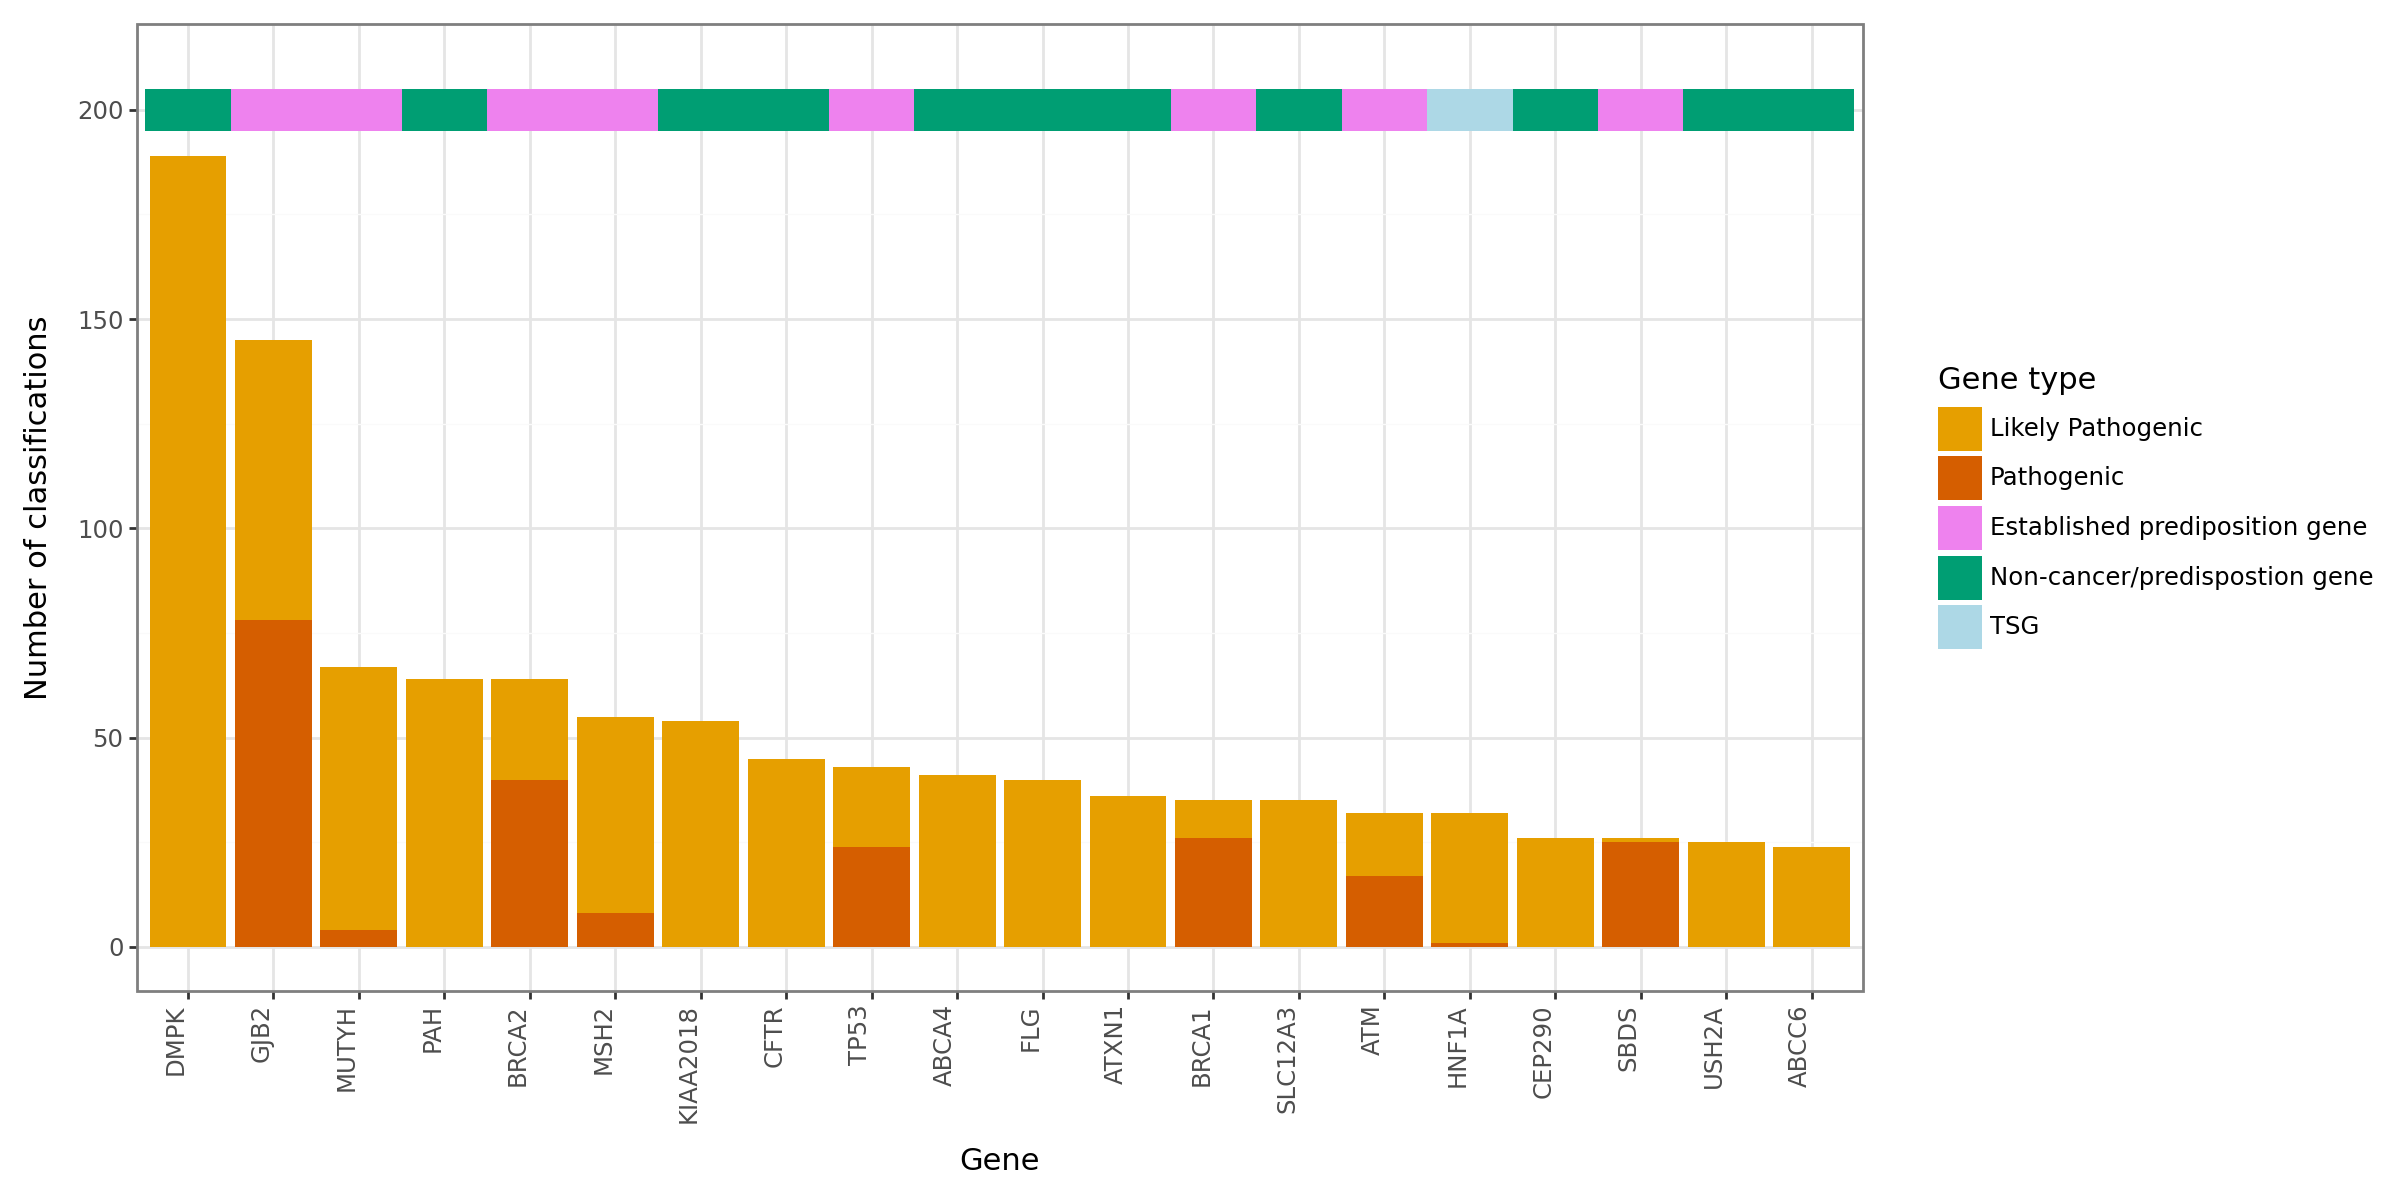

In [53]:
import pandas as pd
from plotnine import (
    ggplot, aes, geom_bar, geom_tile,
    labs, theme, element_text, scale_fill_manual, coord_cartesian
)

# 1. Filter dataset
plot_df = res[
    res["ACMG_Classification"].isin(["Pathogenic", "Likely Pathogenic"])
    & res["HUGO_Symbol"].notna()
].copy()

# 2. Top 15 genes
top15 = plot_df["HUGO_Symbol"].value_counts().head(20).index
plot_df = plot_df[plot_df["HUGO_Symbol"].isin(top15)].copy()

# 3. Gene order
plot_df["HUGO_Symbol"] = pd.Categorical(
    plot_df["HUGO_Symbol"], categories=top15, ordered=True
)

# 4. Extract tier mapping per gene
tier_df = (
    plot_df[["HUGO_Symbol", "tier"]]
    .drop_duplicates("HUGO_Symbol")
    .copy()
)
tier_df["tier"] = tier_df["tier"].astype(str)

# 5. Fix all tiles at y = 200 with no horizontal gaps
tier_df["y"] = 200
TILE_HEIGHT = 10.0

# 6. Plot
p = (
    ggplot()
    # Main bar plot
    + geom_bar(
        plot_df,
        aes(x="HUGO_Symbol", fill="ACMG_Classification"),
        width=0.9,
        size=0,
    )
    # Continuous tile strip at top y=200
    + geom_tile(
        tier_df,
        aes(x="HUGO_Symbol", y="y", fill="tier"),
        width=1.0,  # 1.0 removes all horizontal gaps between tiles
        height=TILE_HEIGHT,
    )
    + scale_fill_manual(
        values={
            "Pathogenic": "#D55E00",
            "Likely Pathogenic": "#E69F00",
            "Established prediposition gene": "violet",
            "Non-cancer/predispostion gene": "#009E73",
            "TSG": "lightblue"
        }
    )
    + coord_cartesian(ylim=(0, 210))  # Ensures y=200 band fits comfortably in frame
    + labs(
        x="Gene",
        y="Number of classifications",
        fill="Gene type",
    )
    + pn.theme_bw()
    + theme(
        axis_text_x=element_text(rotation=90, ha="right"),
        figure_size=(12, 6),
    )
)

p

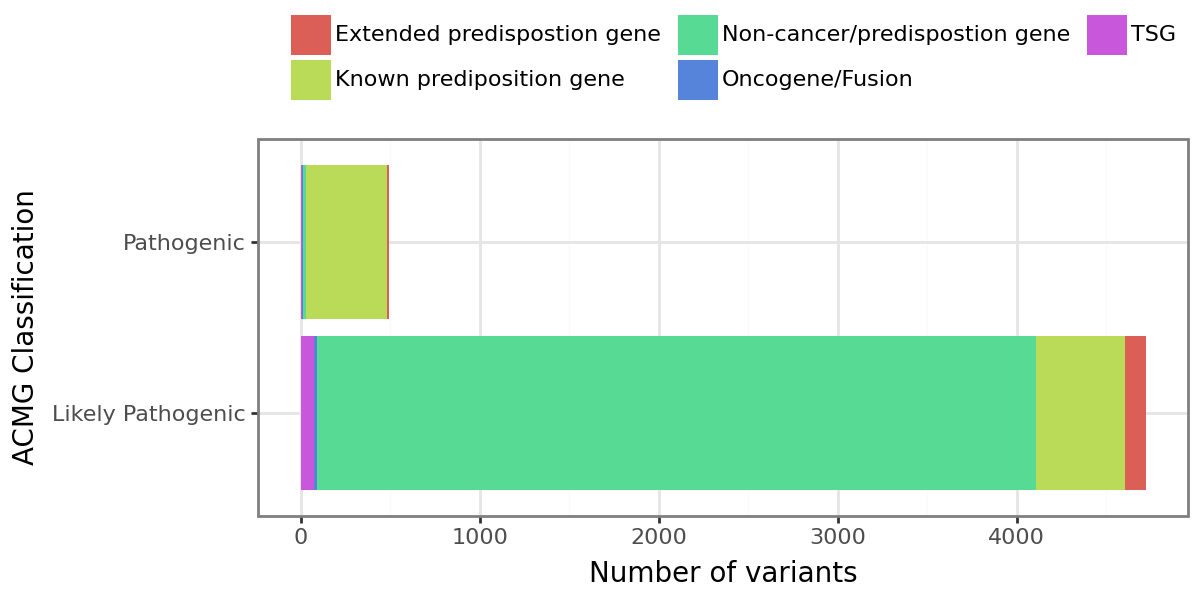

In [45]:
p = (
    pn.ggplot(
        res[
            (res["ACMG_Classification"]
            != "Uncertain Significance") & (~res["ACMG_Classification"].isna())
        ]
    )
    + pn.geom_bar(
        pn.aes(x="ACMG_Classification", fill="tier")
    ) 
    + pn.coord_flip()
    + pn.theme_bw(base_size=10)
    + pn.theme(legend_position="top", figure_size=(6, 3))
    + pn.labs(x="ACMG Classification", fill=" ", y= "Number of variants" )
    + pn.guides(fill=pn.guide_legend(nrow=2))


)
p

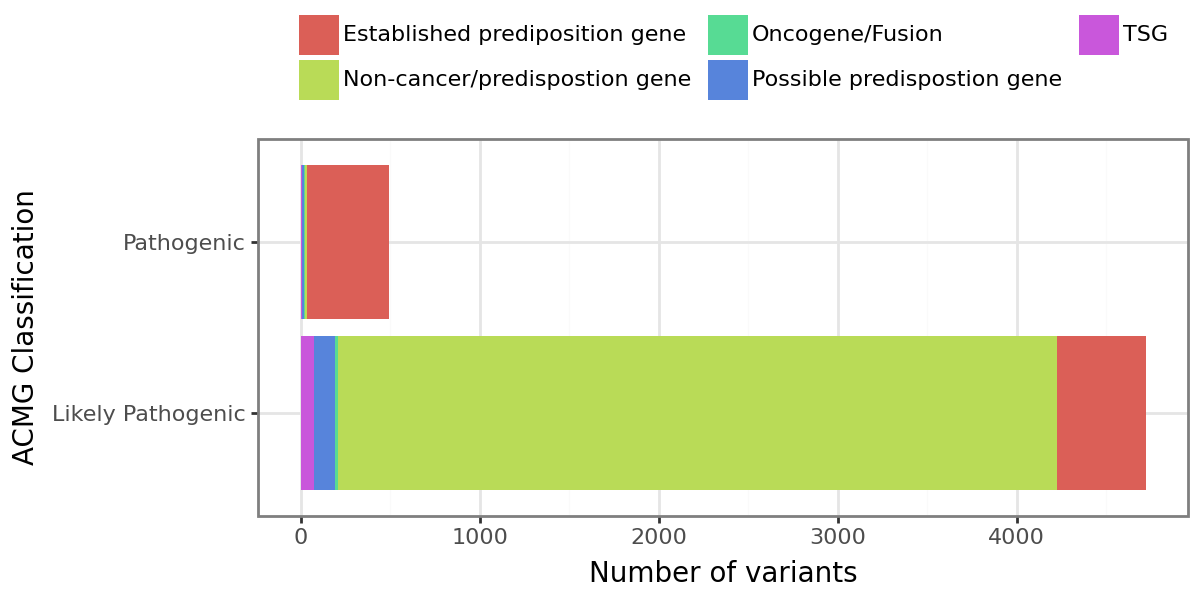

In [55]:
p = (
    pn.ggplot(
        res[
            (res["ACMG_Classification"]
            != "Uncertain Significance") & (~res["ACMG_Classification"].isna()) & 
            (res["ACMG_Classification"] != "Non-cancer/predisposition gene")
        ]
    )
    + pn.geom_bar(
        pn.aes(x="ACMG_Classification", fill="tier")
    ) 
    + pn.coord_flip()
    + pn.theme_bw(base_size=10)
    + pn.theme(legend_position="top", figure_size=(6, 3))
    + pn.labs(x="ACMG Classification", fill=" ", y= "Number of variants" )
    + pn.guides(fill=pn.guide_legend(nrow=2))


)
p

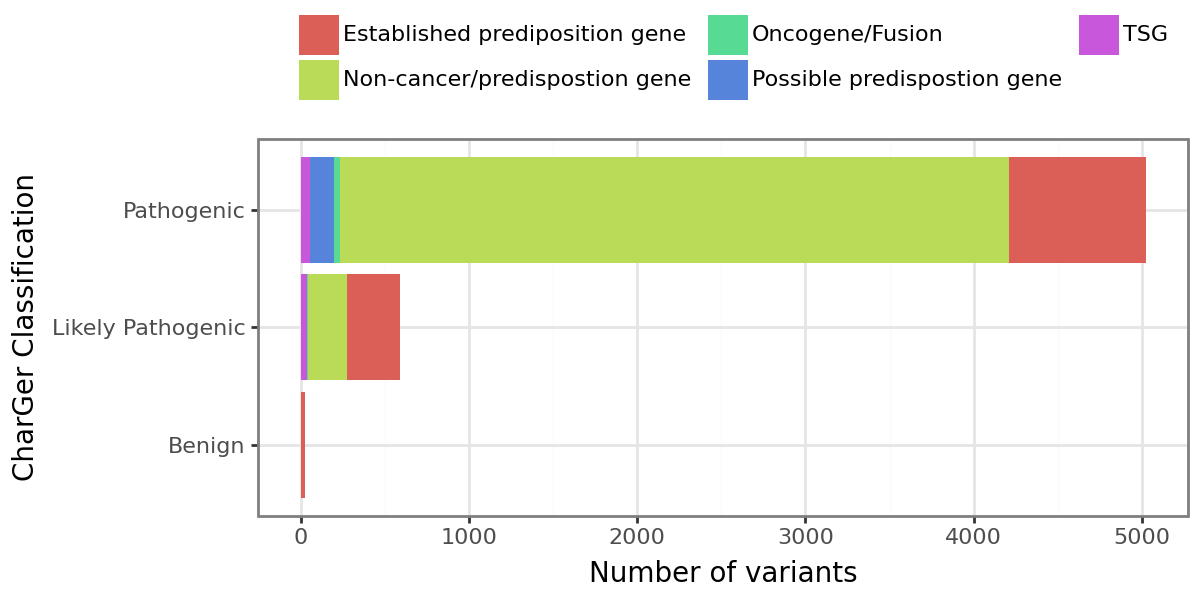

In [54]:
p = (
    pn.ggplot(
        res[
            (res["CharGer_Classification"]
            != "Uncertain Significance") & (~res["CharGer_Classification"].isna())
        ]
    )
    + pn.geom_bar(
        pn.aes(x="CharGer_Classification", fill="tier")
    ) 
    + pn.coord_flip()
    + pn.theme_bw(base_size=10)
    + pn.theme(legend_position="top", figure_size=(6, 3))
    + pn.labs(x="CharGer Classification", fill=" ", y= "Number of variants" )
    + pn.guides(fill=pn.guide_legend(nrow=2))


)
p

In [3]:
sa = pd.read_csv("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/sample_data/master_drop_sample_annotation_sizeFactorFiltered_0.1.tsv", sep="\t")
sa = sa[sa["Diag"] != "Unstranded_data"]
len(sa)
sa["key"] = sa["pid"] +  "." + sa["nct_pid"].str.split("_").str[1]



In [4]:
# sa = sa.merge(sample_counts.drop_duplicates("PID")[["PID", "infered_seq_type"]], how="left", left_on="pid", right_on="PID").drop(columns="PID")
# sa.to_csv("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/sample_data/master_drop_sample_annotation_sizeFactorFiltered_0.1.tsv", sep="\t", index=None)

In [5]:
# cadd = pl.scan_csv("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/vep/cadd/whole_genome_SNVs.tsv.gz", separator="\t", comment_prefix="##").filter(pl.col("Pos").is_in(dresden_germline["POS"])).collect()

In [16]:
dresden_germline = (pl.scan_parquet(
    "/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/vcf/dresden_annotations/germline/germline_aggregated_predisp_cgc_tinda.parquet")
    #"/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/vcf/cnv/germl|ine_predisp_cgc_all_TINDA_merged_vep.parquet")
                    .with_columns(
                            cs.starts_with("SpliceAI_pred_DS_").cast(pl.Float64, strict=False)
                    ).filter((pl.col("PID").is_in(sa[sa["Diag"]!= "Unstranded_data"]["pid"]) & pl.col("Gene").is_in(genes_of_interest[(genes_of_interest["cgc"].isna()) |(genes_of_interest["ROLE_IN_CANCER"].str.contains("TSG"))]["geneID_short"]))
                          )
                    .collect(engine="streaming")        
                  ).to_pandas()
# dresden_germline


dresden_germline["germline_max_spliceai_score"] = dresden_germline[["SpliceAI_pred_DS_AL", "SpliceAI_pred_DS_AG", 
    "SpliceAI_pred_DS_DG", "SpliceAI_pred_DS_DL"
]].max(axis=1)

dresden_germline = add_missing_acmgs(dresden_germline)

dresden_germline = dresden_germline.drop_duplicates(subset=["PID", "Gene", "#CHROM", "POS", "REF", "ALT"])
print(dresden_germline.shape)

(2127488, 206)


(2168344, 206)


# number of LP/P based on gene sets

In [38]:

dresden_germline = (pl.scan_parquet(
    "/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/vcf/dresden_annotations/germline/germline_aggregated_predisp_cgc_tinda.parquet")
    #"/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/vcf/cnv/germline_predisp_cgc_all_TINDA_merged_vep.parquet")
                    .with_columns(
                            cs.starts_with("SpliceAI_pred_DS_").cast(pl.Float64, strict=False)
                    ).filter((pl.col("PID").is_in(sa[sa["Diag"]!= "Unstranded_data"]["pid"])))
                          
                    .collect(engine="streaming")        
                  ).to_pandas()
# dresden_germline

# dresden_germline = dresden_germline[dresden_germline["Gene"].isin(genes_of_interest["geneID_short"]
dresden_germline["germline_max_spliceai_score"] = dresden_germline[["SpliceAI_pred_DS_AL", "SpliceAI_pred_DS_AG", 
    "SpliceAI_pred_DS_DG", "SpliceAI_pred_DS_DL"
]].max(axis=1)

dresden_germline = add_missing_acmgs(dresden_germline)
dresden_germline = dresden_germline.drop_duplicates(subset=["PID", "#CHROM", "POS", "REF", "ALT", "Gene"])

In [40]:
dresden_germline["PID"].unique()

<ArrowStringArray>
[ 'YUNADP', 'NV958FC',  'YEBC3P',  'YG488C',  'ZD413K',  'ZSW8VM',  'A4T4WF',
  'WR8M9Y',  '5WCVKM',  '7HZ47V',
 ...
  'MRF5FT',  'TXS8GF',  'GYS6MK',  'HSJBYP',  'GYQ34C',  'J8VNC7',  '5YFB63',
  'BPMV92',  'P9YFXC',  '3ZMYX1']
Length: 3630, dtype: str

In [19]:
dresden_germline["tier"] = "Non-cancer/predispostion gene"

# dresden_germline["tier"] = "Oncogene/Fusion"
dresden_germline.loc[dresden_germline["Gene"].isin(dresden_dt["geneID_short"]), "tier"] = "Known prediposition gene"
dresden_germline.loc[(dresden_germline["tier"] != "Known prediposition gene") & (dresden_germline["Gene"].isin(extended_dresden_dt["geneID_short"])), "tier"] = "Extended predispostion gene"
dresden_germline.loc[~(dresden_germline["tier"].isin(["Extended predisposition gene", "Known prediposition gene"])) & (dresden_germline["Gene"].isin(genes_of_interest[genes_of_interest["ROLE_IN_CANCER"].str.contains("TSG")]["geneID_short"])) , "tier"] = "TSG"


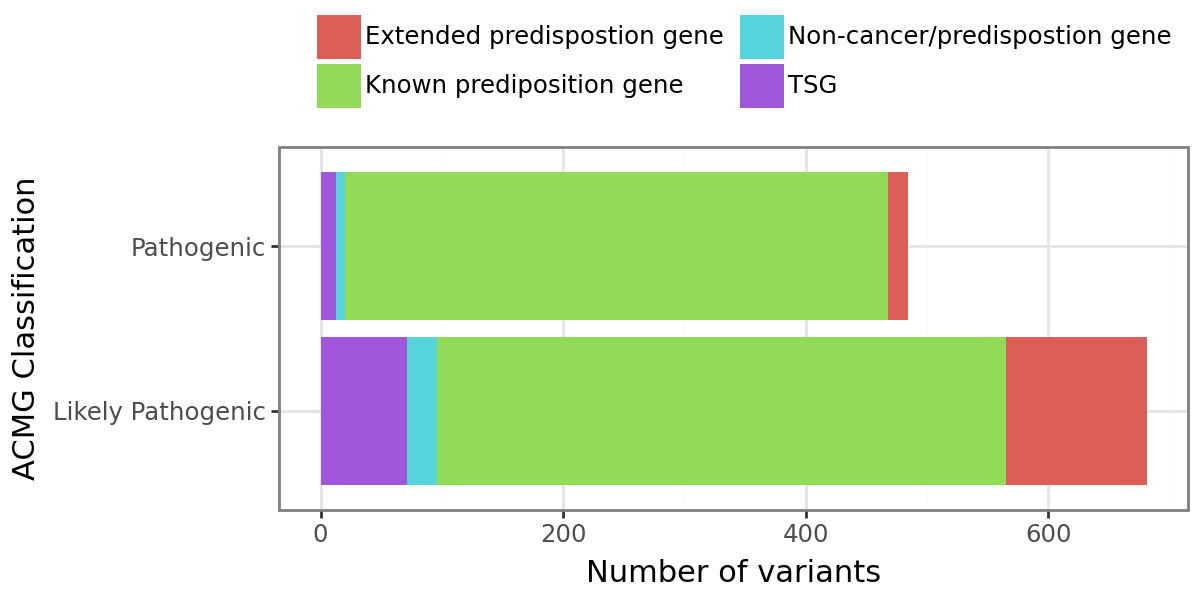

In [23]:
p = (
    pn.ggplot(
        dresden_germline[
            (dresden_germline["germline_ACMG_Classification"]
            != "Uncertain Significance") & (~dresden_germline["germline_ACMG_Classification"].isna())
        ]
    )
    + pn.geom_bar(
        pn.aes(x="germline_ACMG_Classification", fill="tier")
    ) 
    + pn.coord_flip()
    + pn.theme_bw(base_size=11)
    + pn.theme(legend_position="top", figure_size=(6, 3))
    + pn.labs(x="ACMG Classification", fill=" ", y= "Number of variants" )
    + pn.guides(fill=pn.guide_legend(nrow=2))


)
p

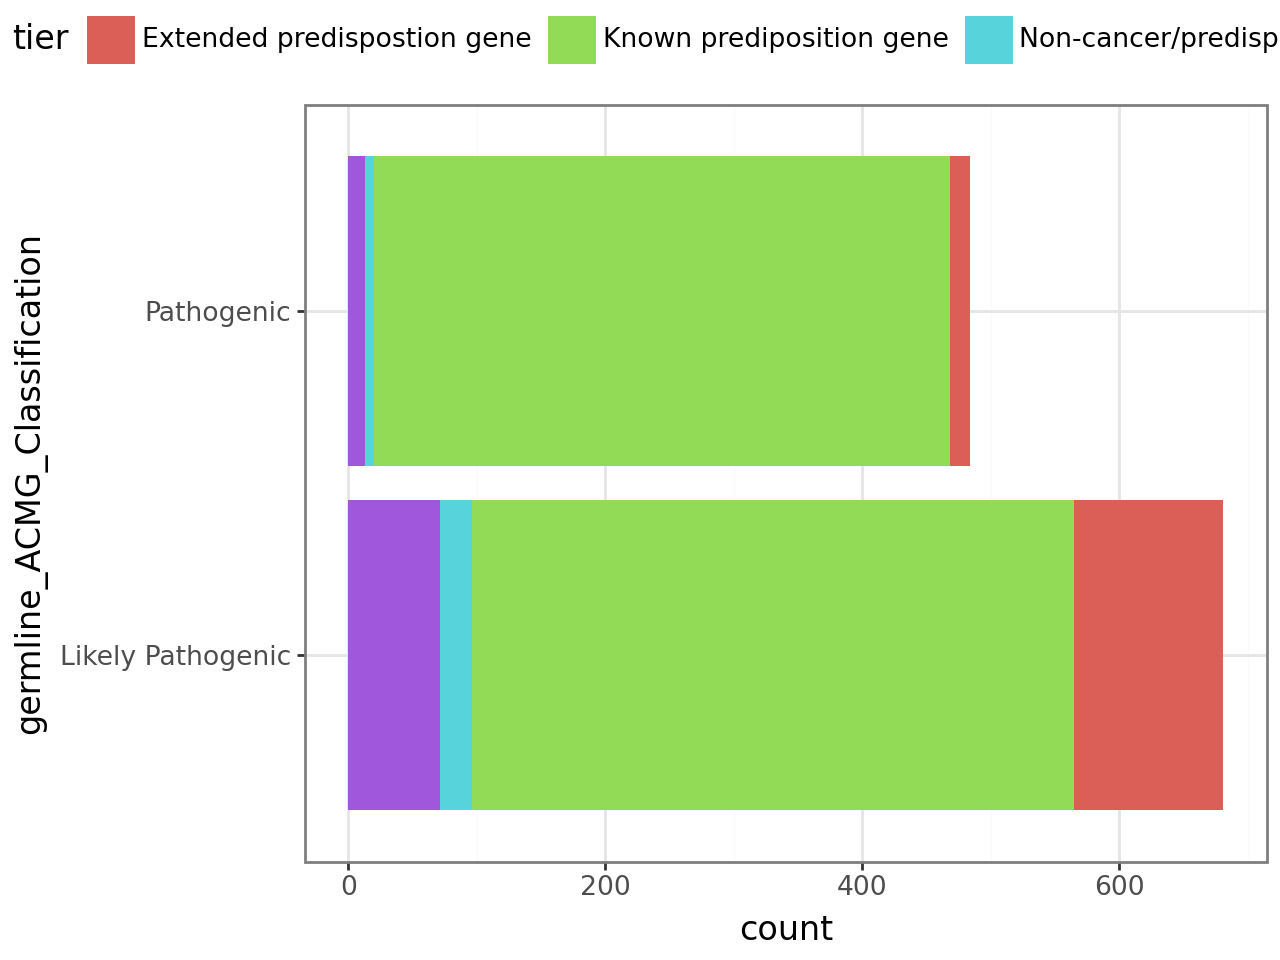

In [24]:
p = (
    pn.ggplot(
        dresden_germline[
            (dresden_germline["tier"] != "Known predisposition gene") &
            (dresden_germline["germline_ACMG_Classification"]
            != "Uncertain Significance") & (~dresden_germline["germline_ACMG_Classification"].isna())
        ]
    )
    + pn.geom_bar(
        pn.aes(x="germline_ACMG_Classification", fill="tier")
    ) 
    + pn.coord_flip()
    + pn.theme_bw(base_size=12)
    + pn.theme(legend_position="top",)

)
p

In [13]:
dresden_germline[dresden_germline["Gene"].isin(extended_dresden_dt["geneID_short"])]["germline_ACMG_Classification"].value_counts()


Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [14]:
dresden_germline["germline_ACMG_Classification"].value_counts()


Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [38]:
l_lp = dresden_germline[dresden_germline["germline_ACMG_Classification"].isin(["Likely Pathogenic", "Pathogenic"])]

## added value

In [ ]:
len(l_lp["PID"].unique())
l_lp["variant_class"].value_counts()

In [46]:
# AMCG P/LP: 618 + 456 variants
# 525 new samples with omics
# 612 variants with omics

gene_tier1 = pd.read_csv("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/results/res_202606/dna_first_gene_underexpression_tier3_vus_spliceai_gt0_1.tsv", sep="\t")
gene_tier1["Omic layer"] = "Gene expression"

protein_tier1 = pd.read_csv("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/results/res_202606/dna_first_protein_underexpression_tier3_vus_spliceai_gt0_1.tsv", sep="\t")
protein_tier1["Omic layer"] = "Protein expression"
protein_tier1 = protein_tier1.rename(columns={"proteinID": "gene_name"})

splicing_tier1 = pd.read_csv("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/results/res_202606/dna_first_gene_splicing_tier3_vus_spliceai_gt0_1.tsv", sep="\t")
splicing_tier1["Omic layer"] = "Gene splicing"
splicing_tier1 = splicing_tier1.rename(columns={"hgncSymbol": "gene_name"})


all_res = pd.concat([gene_tier1[["Omic layer", "nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name", "germline_ACMG_Classification", "germline_Consequence"]],
                     protein_tier1[["Omic layer","nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name", "germline_ACMG_Classification", "germline_Consequence"]],
                    splicing_tier1[["Omic layer","nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name", "germline_ACMG_Classification", "germline_Consequence"]],
                    ]
                   )

all_res["sampleID"] = all_res["nct_pid"].str.split("_").str[0]

all_res['variant_class'] = all_res['germline_Consequence'].str.contains(
    coding_pattern, 
    regex=True, 
    na=False
).map({True: 'Coding', False: 'Non-coding'})

all_res_vus = all_res[~all_res["germline_ACMG_Classification"].isin(["Likely Pathogenic", "Pathogenic"])]
all_res_vus



Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [69]:
all_res_vus[(~all_res_vus["sampleID"].isin(l_lp["PID"])) & (all_res_vus["Omic layer"] == "Gene expression")].drop_duplicates(subset=["nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name",])["variant_class"].value_counts()

all_res_vus[(~all_res_vus["sampleID"].isin(l_lp["PID"])) & (all_res_vus["Omic layer"] == "Protein expression")].drop_duplicates(subset=["nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name",])["variant_class"].value_counts()

all_res_vus[(~all_res_vus["sampleID"].isin(l_lp["PID"])) & (all_res_vus["Omic layer"] == "Gene splicing")].drop_duplicates(subset=["nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name",])["variant_class"].value_counts()

all_res_vus[(~all_res_vus["sampleID"].isin(l_lp["PID"]))].drop_duplicates(subset=["nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name",])["variant_class"].value_counts()


Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [50]:
len(all_res_vus[~all_res_vus["sampleID"].isin(l_lp["PID"])]["sampleID"].unique())
all_res_vus[~all_res_vus["sampleID"].isin(l_lp["PID"])].drop_duplicates(subset=["nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name",])
all_res_vus[(~all_res_vus["sampleID"].isin(l_lp["PID"])) & (all_res_vus["Omic layer"] == "Gene expression")].drop_duplicates(subset=["nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name",])
all_res_vus[(~all_res_vus["sampleID"].isin(l_lp["PID"])) & (all_res_vus["Omic layer"] == "Protein expression")].drop_duplicates(subset=["nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name",])
all_res_vus[(~all_res_vus["sampleID"].isin(l_lp["PID"])) & (all_res_vus["Omic layer"] == "Gene splicing")].drop_duplicates(subset=["nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name",])

all_res_vus[(~all_res_vus["sampleID"].isin(l_lp["PID"])) ].drop_duplicates(subset=["nct_pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "gene_name",])


Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


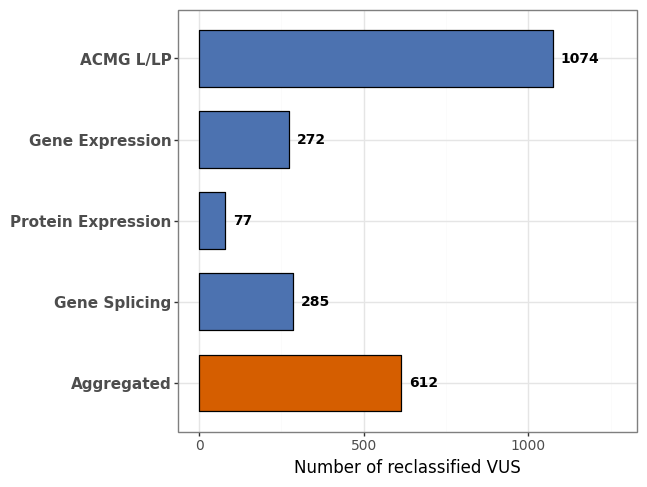

In [59]:

# 1. Prepare data
df = pd.DataFrame(
    {
        "Layer": [
            "ACMG L/LP",
            "Gene Expression",
            "Protein Expression",
            "Gene Splicing",
            "Aggregated",
        ],
        "Count": [618 + 456, 272, 77, 285, 612],
    }
)

# Preserve order (top to bottom)
category_order = [
    "ACMG L/LP",
    "Gene Expression",
    "Protein Expression",
    "Gene Splicing",
    "Aggregated",
]
df["Layer"] = pd.Categorical(df["Layer"], categories=category_order[::-1], ordered=True)

# Highlight "Aggregated"
color_dict = {
    "ACMG L/LP": "#4C72B0",
    "Gene Expression": "#4C72B0",
    "Protein Expression": "#4C72B0",
    "Gene Splicing": "#4C72B0",
    "Aggregated": "#D55E00",
}

# 2. Build plot
plot = (
    ggplot(df, aes(x="Layer", y="Count", fill="Layer"))
    + geom_bar(stat="identity", show_legend=False, width=0.7, color="black")
    + geom_text(
        aes(label="Count"),
        ha="left",
        va="center",
        nudge_y=25,          # <-- Fixed: Passed directly as keyword argument
        size=10,
        fontweight="bold",
    )
    + scale_fill_manual(values=color_dict)
    + scale_y_continuous(limits=(0, max(df["Count"]) * 1.18))
    + coord_flip()
    + labs(
        x="",
        y="Number of reclassified VUS",
    )
    + pn.theme_bw(base_size=12)
    + theme(
        plot_title=element_text(size=14, fontweight="bold"),
        axis_text_x=element_text(size=10),
        axis_text_y=element_text(size=11, fontweight="bold"),
    )
)

plot.draw()

In [144]:
res = pd.concat((gene_under_expression_tsg_predips, pr_predisp_tsg, splicing_vars_tsg))
res_unique = res.drop_duplicates(subset=["PID", "POS", "REF", "ALT", "#CHROM", "Gene"])
res_unique["variant_class"].value_counts()      
res_unique["PID"].unique()


<ArrowStringArray>
[ 'YUNADP',  'PEM7HN',  'LJVWQT',  'RMZXUB',  'Q5Q81Z',  'GPT5N3',  '9WSJJL',
  'C8HAJF',  'L3ABZV', '6YA6W3H',
 ...
  '5YFB63',  'YPA74Z', '8XMJ4MY',  'L7L8KS',  'BDNR5D',  'LCC5GK',  'DFTVN1',
  '3ZMYX1',  'BFEMLP',  'NYSDZE']
Length: 592, dtype: str

here


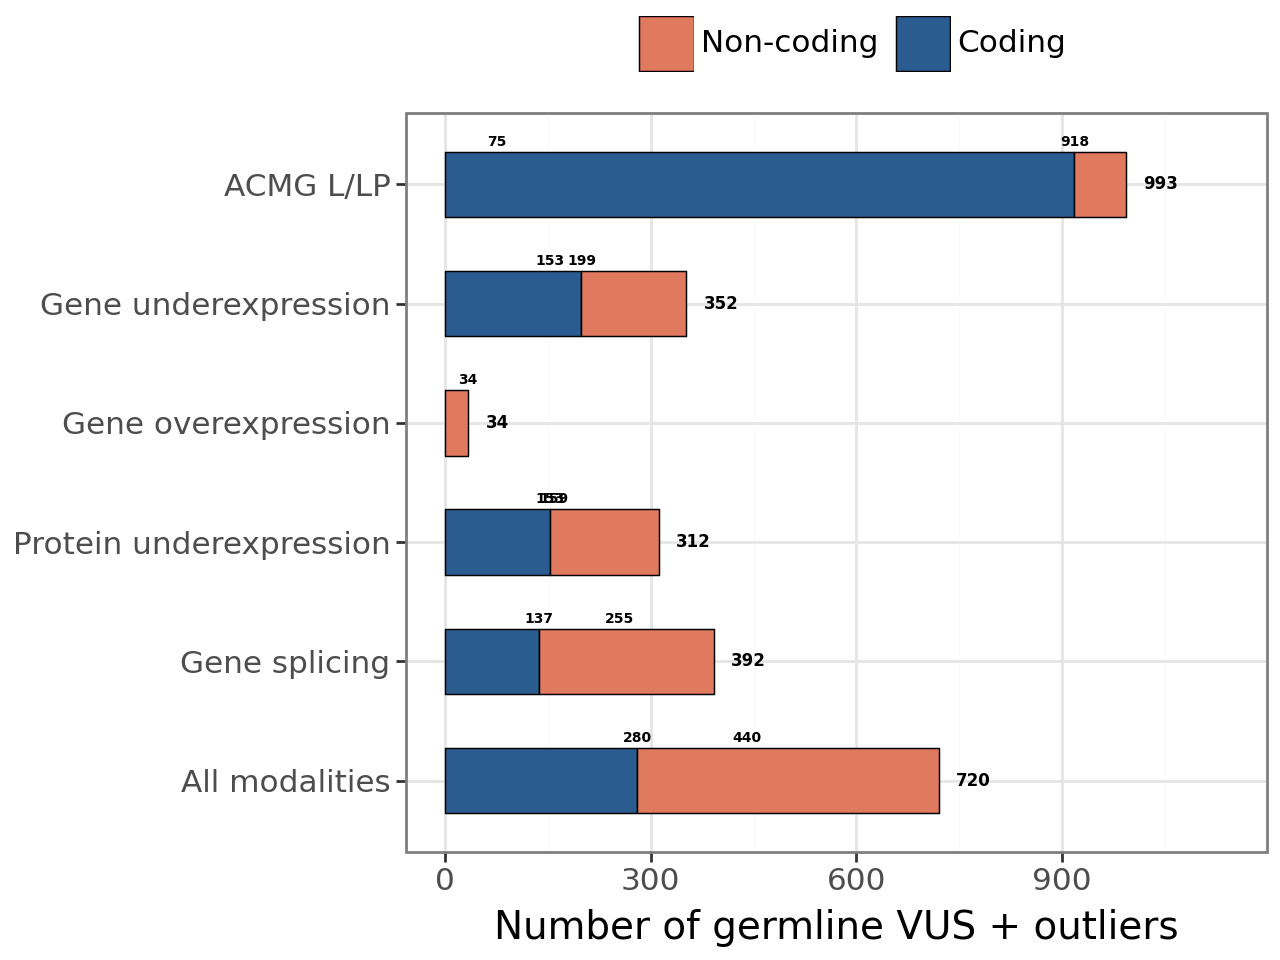

In [143]:

# 1. Prepare data
data = [
    {"Layer": "ACMG L/LP", "Region": "Coding", "Count": 918},
    {"Layer": "ACMG L/LP", "Region": "Non-coding", "Count": 75},
    {"Layer": "Gene underexpression", "Region": "Coding", "Count": 199},
    {"Layer": "Gene overexpression", "Region": "Non-coding", "Count": 34},
    {"Layer": "Gene underexpression", "Region": "Non-coding", "Count": 153},
    {"Layer": "Protein underexpression", "Region": "Coding", "Count": 153},
    {"Layer": "Protein underexpression", "Region": "Non-coding", "Count": 159},
    {"Layer": "Gene splicing", "Region": "Coding", "Count": 137},
    {"Layer": "Gene splicing", "Region": "Non-coding", "Count": 255},
    {"Layer": "All modalities", "Region": "Coding", "Count": 280},
    {"Layer": "All modalities", "Region": "Non-coding", "Count": 440},
]

df = pd.DataFrame(data)

# Calculate totals
df_totals = df.groupby("Layer")["Count"].sum().reset_index()

# Categorical ordering
category_order = [
    "ACMG L/LP",
    "Gene underexpression",
    "Gene overexpression",
    "Protein underexpression",
    "Gene splicing",
    "All modalities",
]

df["Layer"] = pd.Categorical(
    df["Layer"], categories=category_order[::-1], ordered=True
)
df_totals["Layer"] = pd.Categorical(
    df_totals["Layer"], categories=category_order[::-1], ordered=True
)

# Stacking order
df["Region"] = pd.Categorical(
    df["Region"], categories=["Non-coding", "Coding"], ordered=True
)

print("here")
colors = {"Coding": "#2b5c8f", "Non-coding": "#e07a5f"}

# 2. Build plot
plot = (
    pn.ggplot()
    + pn.geom_bar(
        data=df,
        mapping=pn.aes(x="Layer", y="Count", fill="Region"),
        stat="identity",
        width=0.55,
        color="black",
        size=0.3,
    )
    # Segment labels centered using position_stack(vjust=0.5)
    + pn.geom_text(
        data=df,
        mapping=pn.aes(x="Layer", y="Count", fill="Region", label="Count"),
        position=pn.position_stack(vjust=0.5),  # Centered over each segment
        ha="center",
        va="bottom",
        nudge_x=0.3,
        color="black",
        fontweight="bold",
        size=5,
    )
    # Total count label at the end
    + pn.geom_text(
        data=df_totals,
        mapping=pn.aes(x="Layer", y="Count", label="Count"),
        ha="left",
        va="center",
        nudge_y=25,
        color="black",
        fontweight="bold",
        size=6,
    )
    + pn.scale_fill_manual(values=colors)
    + pn.scale_y_continuous(limits=(0, max(df_totals["Count"]) * 1.15))
    + pn.coord_flip()
    + pn.labs(
        title="",  # Title removed
        x="",
        y="Number of germline VUS + outliers",
        fill=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        #axis_text_y=pn.element_text(fontweight="bold"),
        legend_position="top",
        #legend_title=pn.element_text(fontweight="bold"),
    )
)

plot

In [7]:
expression_vars = dresden_germline[(dresden_germline["germline_abexp_v1.1"] <= 0.1) 
    | (dresden_germline["germline_IMPACT"] == "HIGH") 
    | (dresden_germline["germline_promoterAI"] <= -0.1 ) 
    | (dresden_germline["germline_max_spliceai_score"] >= 0.1 ) 
    ]
expression_vars.shape
    

(224608, 209)

In [9]:
dresden_germline[(dresden_germline["germline_abexp_v1.1"] <= 0.1) 
    | (dresden_germline["germline_IMPACT"] == "HIGH") 
    | (dresden_germline["germline_promoterAI"] <= -0.1 ) 
    | (dresden_germline["germline_max_spliceai_score"] >= 0.1 )
    | (dresden_germline["germline_Consequence"].str.contains("missense"))
    ]

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


# Total number plots

In [41]:
# dresden_germline = pl.scan_parquet("//omics/odcf/analysis/hipo/hipo_021/outlier_analysis/vcf/dresden_annotations/germline/germline_damaging_aggregated_all.parquet").filter(pl.col("Gene").is_in(genes_of_interest["geneID_short"])).collect().to_pandas()

dresden_germline = dresden_germline.merge(sa[["pid", "infered_seq_type"]], how="left", left_on="PID", right_on="pid")

In [11]:
print(len(dresden_germline[(dresden_germline["REF"].isin(["A", "T", "C", "G"])) & (dresden_germline["ALT"].isin(["A", "T", "C", "G"]))]), " snvs")
print(len(dresden_germline[(dresden_germline["REF"] == ".") |  (dresden_germline["ALT"] == ".") | (dresden_germline["ALT"].str.len() > 1) | (dresden_germline["REF"].str.len() > 1)]), "indel")


1386424  snvs
935477 indel


In [12]:
dresden_germline[dresden_germline["germline_ACMG_Classification"].isin(["Pathogenic", "Likely Pathogenic"])]["germline_Consequence"].value_counts()



Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [63]:


dresden_germline['variant_class'] = dresden_germline['germline_Consequence'].str.contains(
    coding_pattern, 
    regex=True, 
    na=False
).map({True: 'Coding', False: 'Non-coding'})


In [64]:
dresden_germline[["germline_Consequence", "variant_class"]]["variant_class"].value_counts()

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


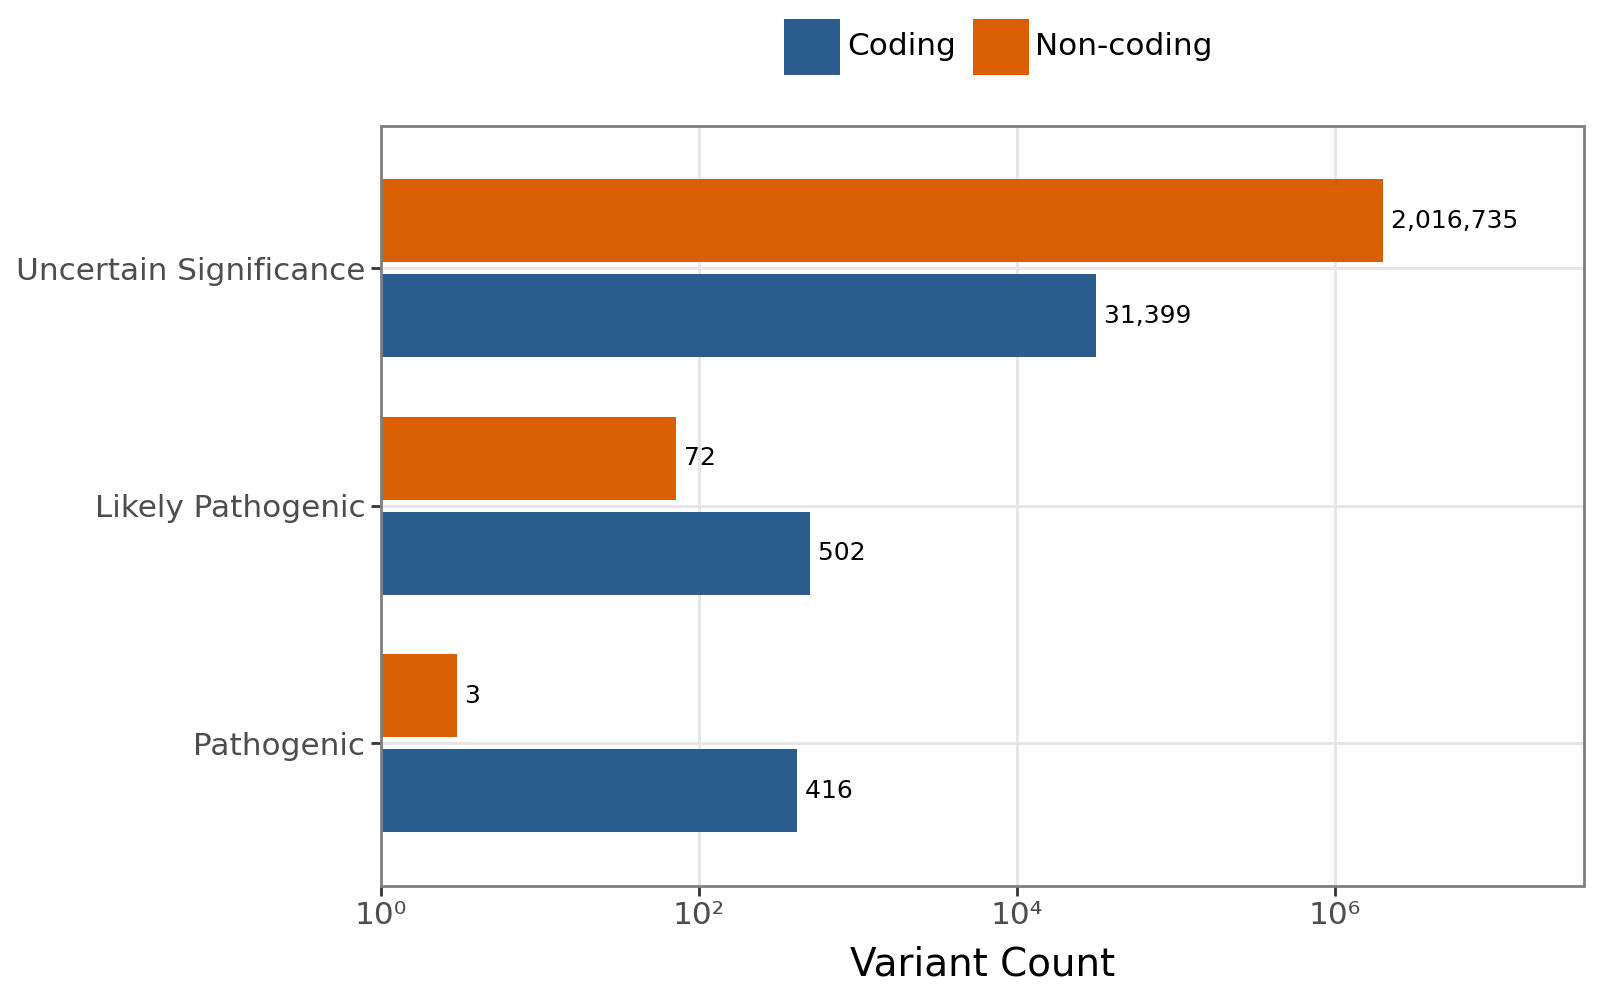

In [65]:


# 1. Aggregate counts per variant_class & ACMG_Classification
df_counts = (
    dresden_germline.groupby(["variant_class", "germline_ACMG_Classification"], observed=False)
    .size()
    .reset_index(name="count")
)

# 2. Add log10 count for plotting (log10(count + 1) prevents log(0) issues)
df_counts["log10_count"] = np.log10(df_counts["count"])

# Formatted count label for display
df_counts["label"] = df_counts["count"].apply(lambda x: f"{x:,}")

# 3. Standardize order for categories
acmg_order = ["Uncertain Significance", "Likely Pathogenic", "Pathogenic"]
df_counts["ACMG_Classification"] = pd.Categorical(
    df_counts["germline_ACMG_Classification"], categories=acmg_order[::-1], ordered=True
)

# 4. Plot
p = (
    pn.ggplot(
        df_counts,
        pn.aes(
            x="ACMG_Classification",
            y="log10_count",
            fill="variant_class",
        ),
    )
    + pn.geom_bar(stat="identity", position=pn.position_dodge(width=0.8), width=0.7)
    + pn.coord_flip()
    # Add count text next to each bar
    + pn.geom_text(
        pn.aes(label="label"),
        position=pn.position_dodge(width=0.8),
        ha="left",
        va="center",
        size=9,
        format_string=" {}",
    )
    + pn.scale_fill_manual(
        values={"Coding": "#2b5c8f", "Non-coding": "#d95f02"},
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(8, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(
        y="Variant Count",
    )
    # Give extra headroom on y-axis for text labels
)

superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

p = p + pn.scale_y_continuous(
    expand=(0, 0, 0.2, 0),
    labels=lambda ticks: [
        f"10{str(int(t)).translate(superscript_map)}" if t >= 0 else "0"
        for t in ticks
    ],
)

p

In [45]:
dresden_germline["germline_ACMG_Classification"].value_counts(dropna=False)

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


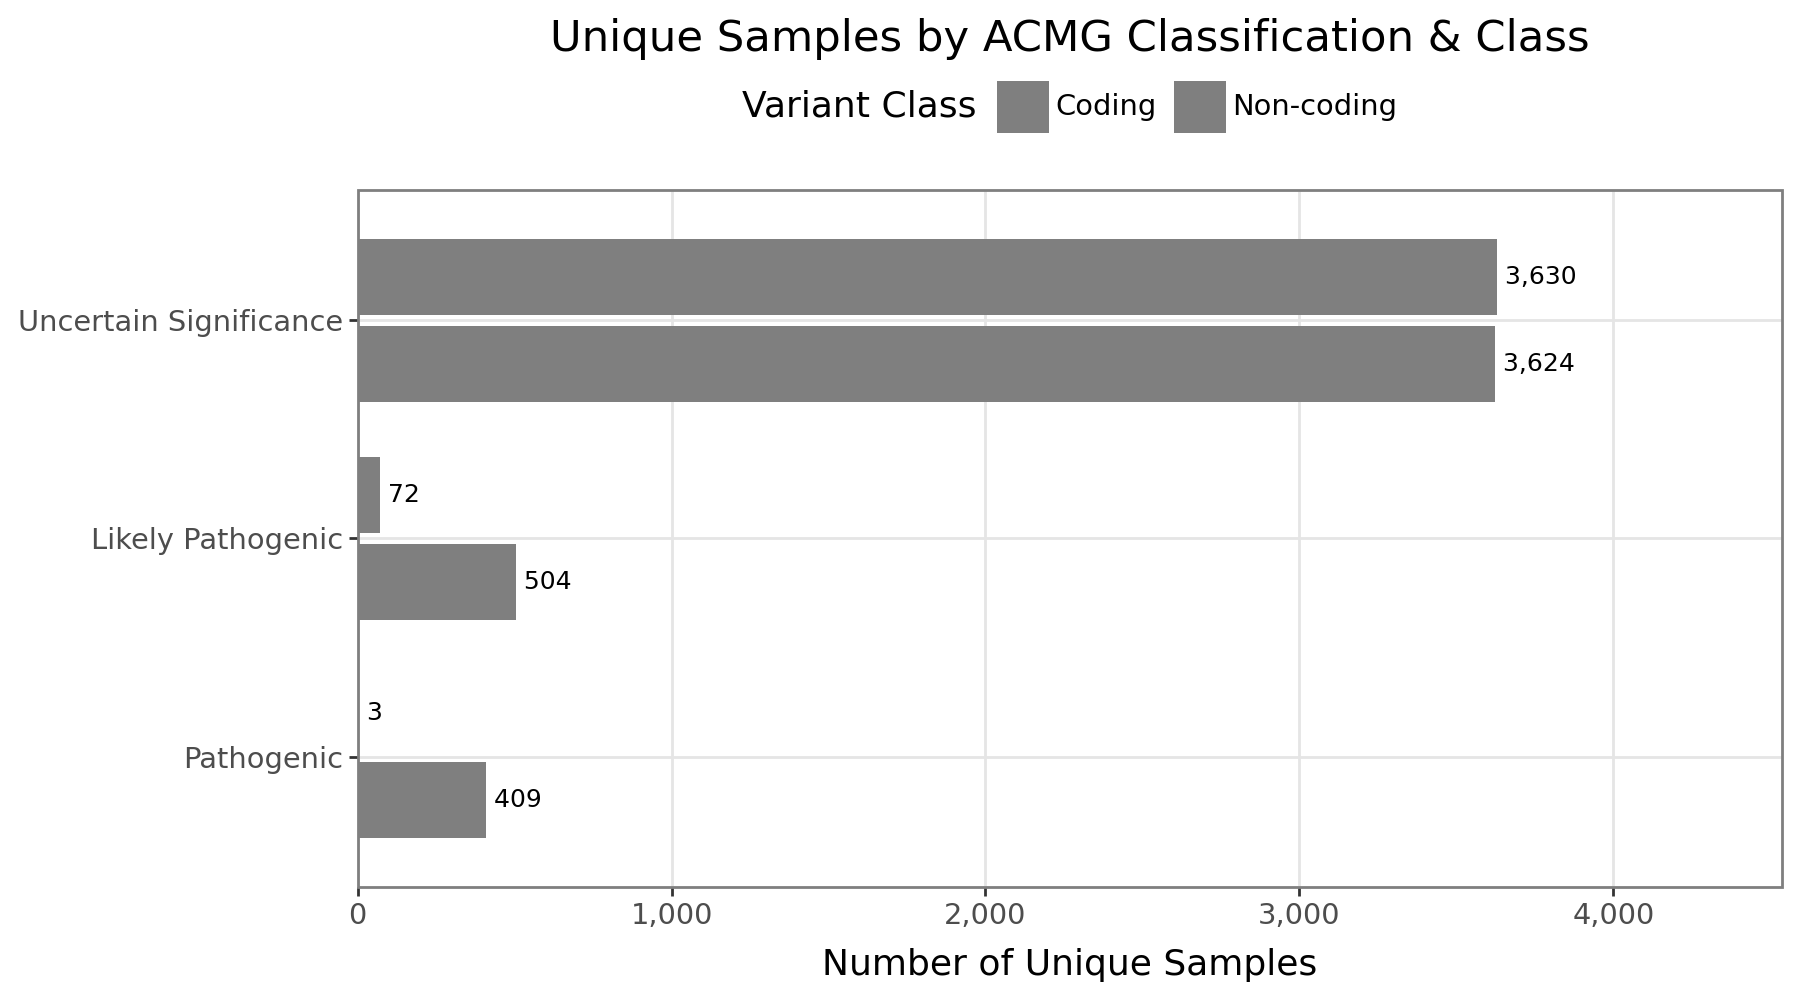

In [47]:

# 1. Aggregate UNIQUE sample counts per variant_class & ACMG_Classification
# Replace 'sampleID' with your actual column name if it differs
df_samples = (
    dresden_germline.groupby(["variant_class", "germline_ACMG_Classification"], observed=False)[
        "PID"
    ]
    .nunique()
    .reset_index(name="unique_samples")
)

# Formatted sample label for geom_text display
df_samples["label"] = df_samples["unique_samples"].apply(lambda x: f"{x:,}")

# 2. Standardize order for categories (Bottom to Top)
acmg_order = ["Uncertain Significance", "Likely Pathogenic", "Pathogenic"]
df_samples["ACMG_Classification"] = pd.Categorical(
    df_samples["germline_ACMG_Classification"],
    categories=acmg_order[::-1],
    ordered=True,
)

# 3. Plot with RAW counts
p = (
    pn.ggplot(
        df_samples,
        pn.aes(
            x="ACMG_Classification",
            y="unique_samples",
            fill="variant_class",
        ),
    )
    + pn.geom_bar(
        stat="identity", position=pn.position_dodge(width=0.8), width=0.7
    )
    + pn.coord_flip()
    + pn.geom_text(
        pn.aes(label="label"),
        position=pn.position_dodge(width=0.8),
        ha="left",
        va="center",
        size=9,
        format_string=" {}",
    )
    + pn.scale_fill_manual(
        values={"coding": "#2b5c8f", "non-coding": "#d95f02"},
        name="Variant Class",
    )
    + pn.theme_bw(base_size=13)
    + pn.theme(
        figure_size=(9, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(
        y="Number of Unique Samples",
        title="Unique Samples by ACMG Classification & Class",
    )
    # Formats tick labels with commas (e.g. 5,000 instead of 5000)
    + pn.scale_y_continuous(
        expand=(0, 0, 0.25, 0),
        labels=lambda ticks: [f"{int(t):,}" for t in ticks],
    )
)

p

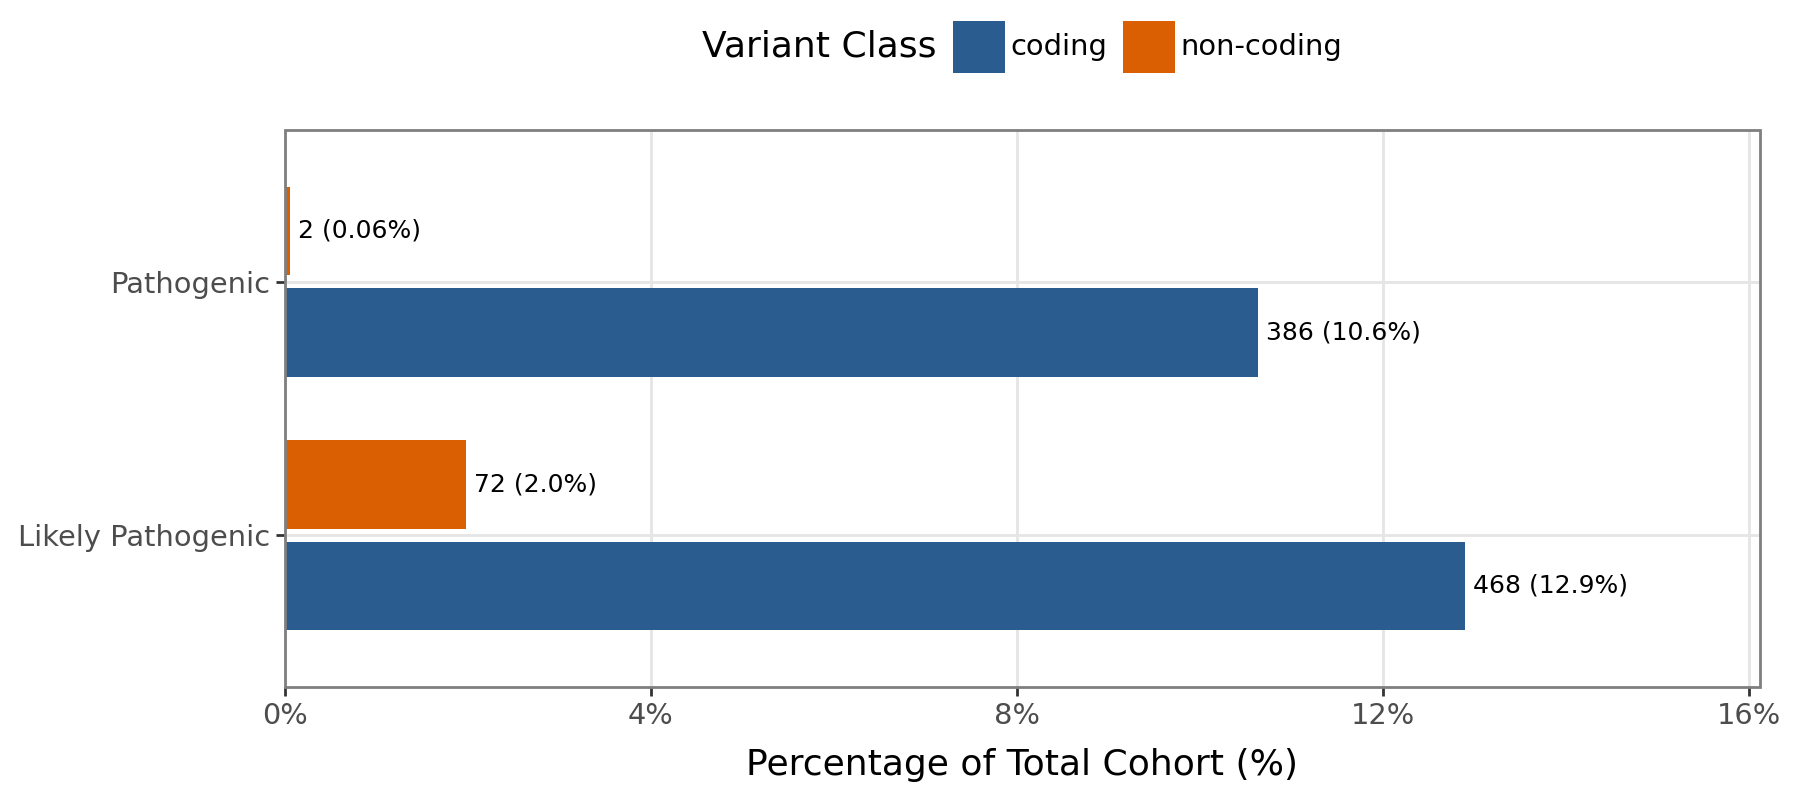

In [33]:


# 1. Total unique samples in cohort
TOTAL_SAMPLES = variants["PID"].nunique()

# 2. Filter to keep ONLY Pathogenic and Likely Pathogenic
target_classes = ["Likely Pathogenic", "Pathogenic"]
df_filtered = variants[
    variants["ACMG_Classification"].isin(target_classes)
].copy()

# 3. Aggregate unique samples per class
df_pct = (
    df_filtered.groupby(["variant_class", "ACMG_Classification"], observed=False)[
        "PID"
    ]
    .nunique()
    .reset_index(name="unique_samples")
)

# 4. Calculate percentage of total cohort
df_pct["percentage"] = (df_pct["unique_samples"] / TOTAL_SAMPLES) * 100

# Formatted label: e.g. "468 (12.9%)" or "2 (0.06%)"
df_pct["label"] = df_pct.apply(
    lambda r: f" {r['unique_samples']:,} ({r['percentage']:.2f}%)"
    if r["percentage"] < 1
    else f" {r['unique_samples']:,} ({r['percentage']:.1f}%)",
    axis=1,
)

# 5. Categorical order (Likely Pathogenic on bottom, Pathogenic on top)
acmg_order = ["Likely Pathogenic", "Pathogenic"]
df_pct["ACMG_Classification"] = pd.Categorical(
    df_pct["ACMG_Classification"],
    categories=acmg_order,
    ordered=True,
)

# 6. Plot
p = (
    pn.ggplot(
        df_pct,
        pn.aes(
            x="ACMG_Classification",
            y="percentage",
            fill="variant_class",
        ),
    )
    + pn.geom_bar(
        stat="identity", position=pn.position_dodge(width=0.8), width=0.7
    )
    + pn.coord_flip()
    + pn.geom_text(
        pn.aes(label="label"),
        position=pn.position_dodge(width=0.8),
        ha="left",
        va="center",
        size=9,
    )
    + pn.scale_fill_manual(
        values={"coding": "#2b5c8f", "non-coding": "#d95f02"},
        name="Variant Class",
    )
    + pn.theme_bw(base_size=13)
    + pn.theme(
        figure_size=(9, 4),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(
        y="Percentage of Total Cohort (%)",
    )
    + pn.scale_y_continuous(
        expand=(0, 0, 0.25, 0),
        labels=lambda ticks: [f"{t:.1f}%" if t % 1 != 0 else f"{int(t)}%" for t in ticks],
    )
)

p

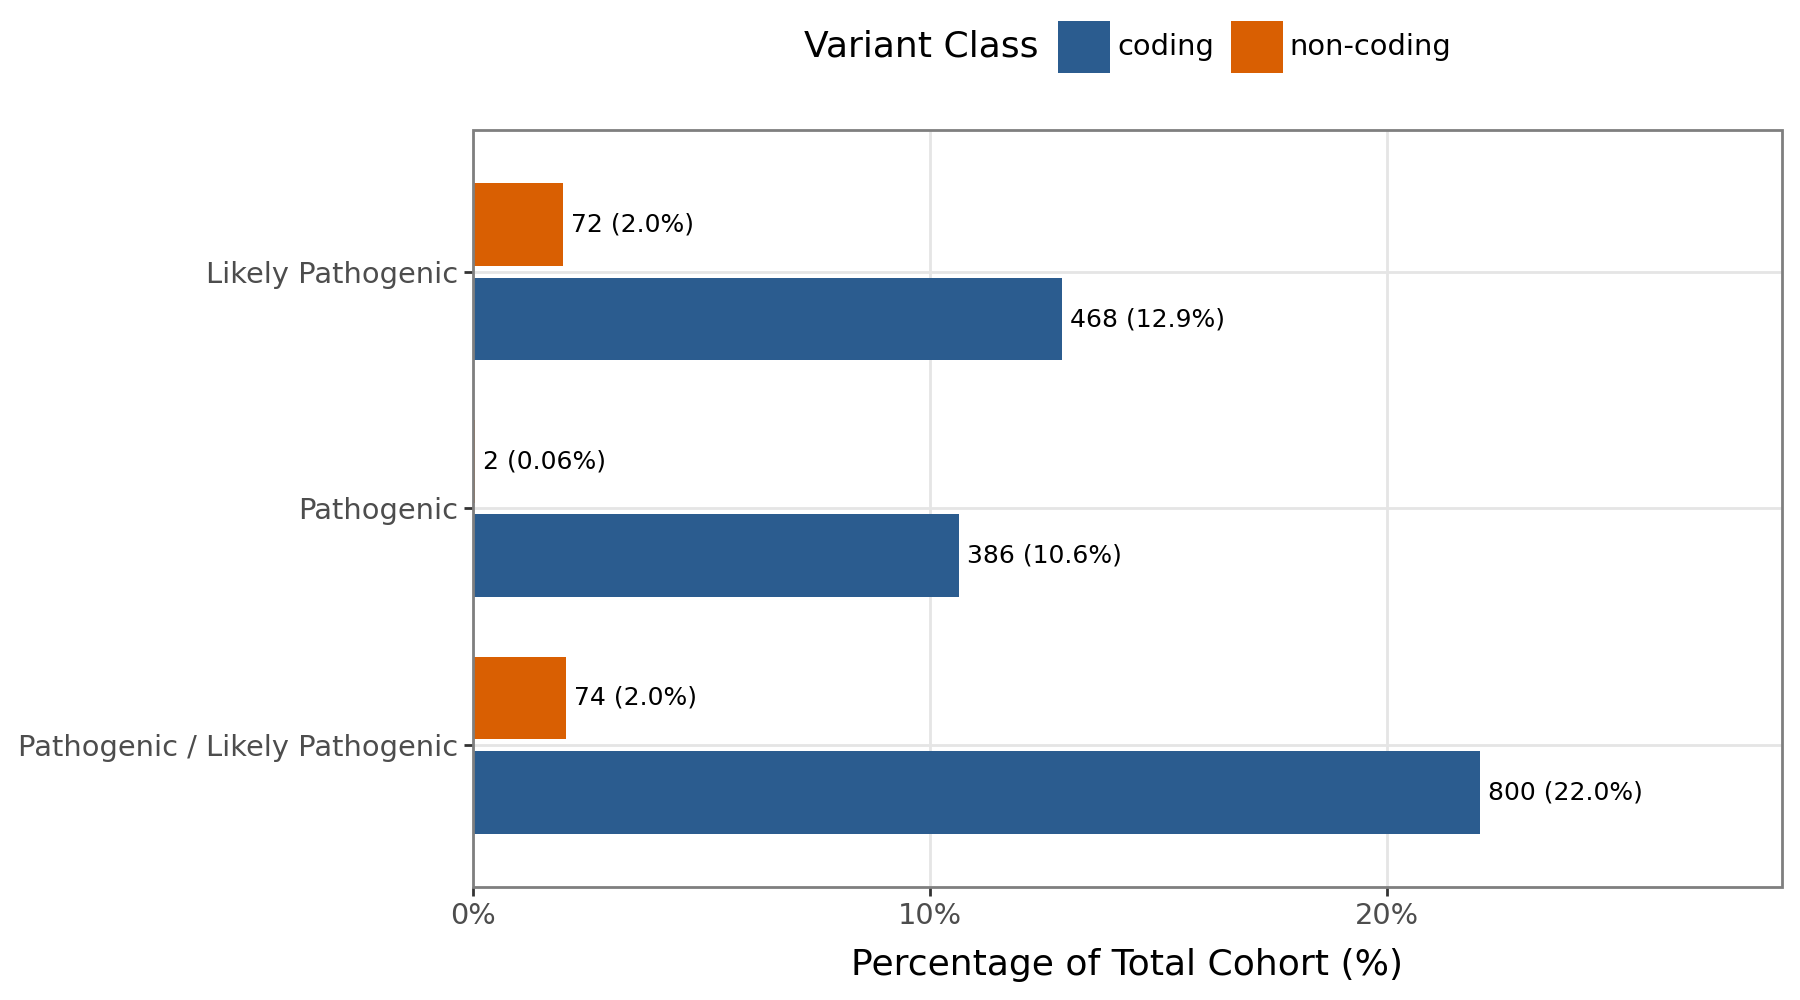

In [39]:

# 1. Cohort size
TOTAL_SAMPLES = variants["PID"].nunique()

# 2. Individual categories
df_ind = (
    variants[variants["ACMG_Classification"].isin(["Likely Pathogenic", "Pathogenic"])]
    .groupby(["variant_class", "ACMG_Classification"], observed=False)["PID"]
    .nunique()
    .reset_index(name="unique_samples")
)

# 3. Combined category: Pathogenic OR Likely Pathogenic (unique samples across both)
df_comb = (
    variants[variants["ACMG_Classification"].isin(["Likely Pathogenic", "Pathogenic"])]
    .groupby("variant_class", observed=False)["PID"]
    .nunique()
    .reset_index(name="unique_samples")
)
df_comb["ACMG_Classification"] = "Pathogenic / Likely Pathogenic"

# 4. Concatenate both views
df_pct = pd.concat([df_ind, df_comb], ignore_index=True)

# 5. Calculate percentage & label
df_pct["percentage"] = (df_pct["unique_samples"] / TOTAL_SAMPLES) * 100
df_pct["label"] = df_pct.apply(
    lambda r: f" {r['unique_samples']:,} ({r['percentage']:.2f}%)"
    if r["percentage"] < 1
    else f" {r['unique_samples']:,} ({r['percentage']:.1f}%)",
    axis=1,
)

# 6. Order categories (Bottom to Top for coord_flip)
acmg_order = [
               
    "Pathogenic / Likely Pathogenic",
    "Pathogenic", 
    "Likely Pathogenic",  
]
df_pct["ACMG_Classification"] = pd.Categorical(
    df_pct["ACMG_Classification"],
    categories=acmg_order,
    ordered=True,
)

# 7. Plot
p = (
    pn.ggplot(
        df_pct,
        pn.aes(
            x="ACMG_Classification",
            y="percentage",
            fill="variant_class",
        ),
    )
    + pn.geom_bar(
        stat="identity", position=pn.position_dodge(width=0.8), width=0.7
    )
    + pn.coord_flip()
    + pn.geom_text(
        pn.aes(label="label"),
        position=pn.position_dodge(width=0.8),
        ha="left",
        va="center",
        size=9,
    )
    + pn.scale_fill_manual(
        values={"coding": "#2b5c8f", "non-coding": "#d95f02"},
        name="Variant Class",
    )
    + pn.theme_bw(base_size=13)
    + pn.theme(
        figure_size=(9, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(
        y="Percentage of Total Cohort (%)",
    )
    + pn.scale_y_continuous(
        expand=(0, 0, 0.3, 0),
        labels=lambda ticks: [f"{t:.1f}%" if t % 1 != 0 else f"{int(t)}%" for t in ticks],
    )
)

p

In [ ]:
## from plotnine import after_stat
sample_counts = variants.groupby('PID').size().reset_index(name='variant_count')
sample_counts["infered_seq_type"] = "WES"
sample_counts.loc[sample_counts["variant_count"] > 200, "infered_seq_type"] = "WGS"
p_hist = (
    pn.ggplot(sample_counts, pn.aes(x='variant_count'))
    + pn.geom_histogram(binwidth=50, fill='#2b5c8f', color='white')
    + pn.theme_bw()
    + pn.labs(
        title="Distribution of Variant Counts Across Samples",
        x="Number of Variants per Sample",
        y="Number of Samples"
    )
)

p_hist

In [42]:
variants["ACMG_Classification"].value_counts()


Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


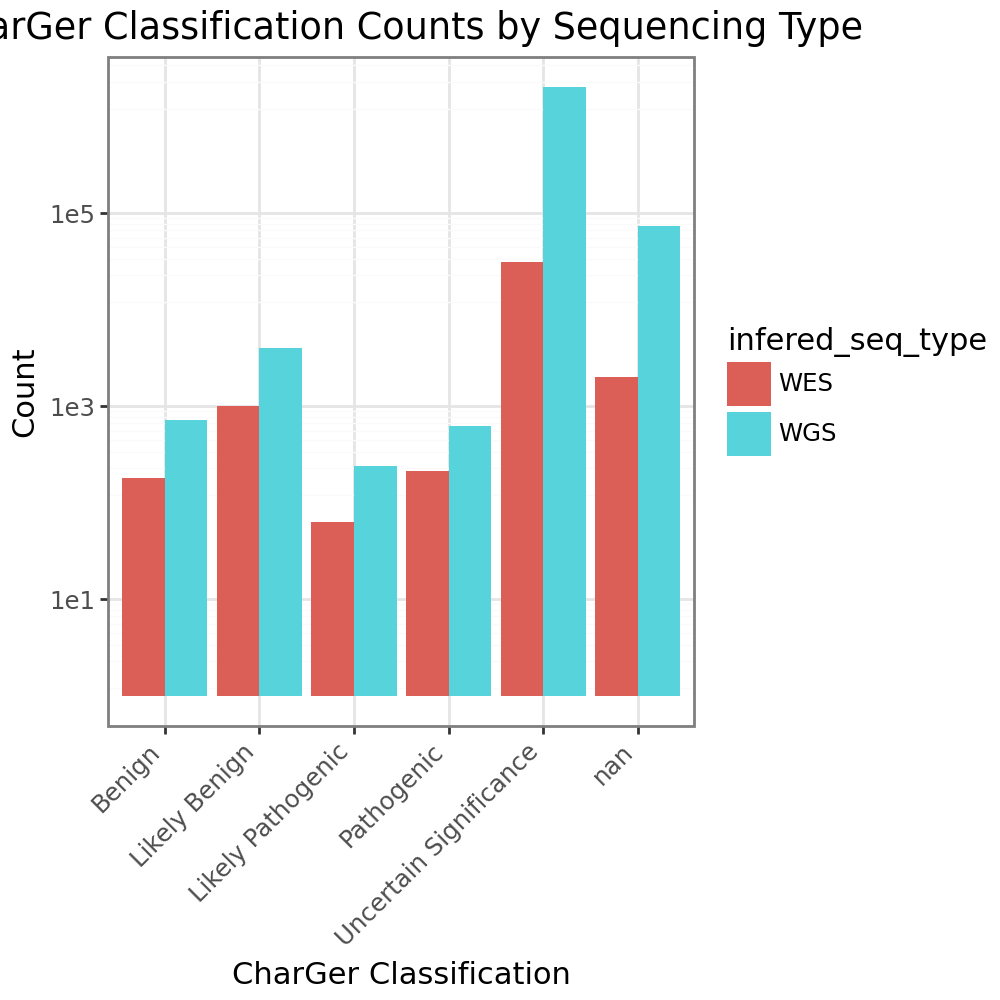

In [36]:
p_charger = (
    pn.ggplot(variants, pn.aes(x='CharGer_Classification', fill='infered_seq_type'))
    + pn.geom_bar(position='dodge')
    + pn.theme_bw()
    + pn.theme(
        axis_text_x=pn.element_text(rotation=45, hjust=1),
        figure_size=(5, 5)
    ) 
    + pn.scale_y_log10()
    + pn.labs(
        title="CharGer Classification Counts by Sequencing Type",
        x="CharGer Classification",
        y="Count",
    )
)
p_charger

In [60]:
genes_of_interest["tier"] = "tier4"
genes_of_interest.loc[genes_of_interest["predisposition"] == True, "tier"] = "Known prediposition gene"
genes_of_interest.loc[(genes_of_interest["tier"] != "Known prediposition gene") & (genes_of_interest["extended_predisposition_gene"] == True), "tier"] = "Extended predispostion gene"
genes_of_interest.loc[~(genes_of_interest["tier"].isin(["Extended predispostion gene", "Known prediposition gene"])) & (genes_of_interest["ROLE_IN_CANCER"].str.contains("TSG")) , "tier"] = "TSG"
genes_of_interest["tier"].value_counts()



Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


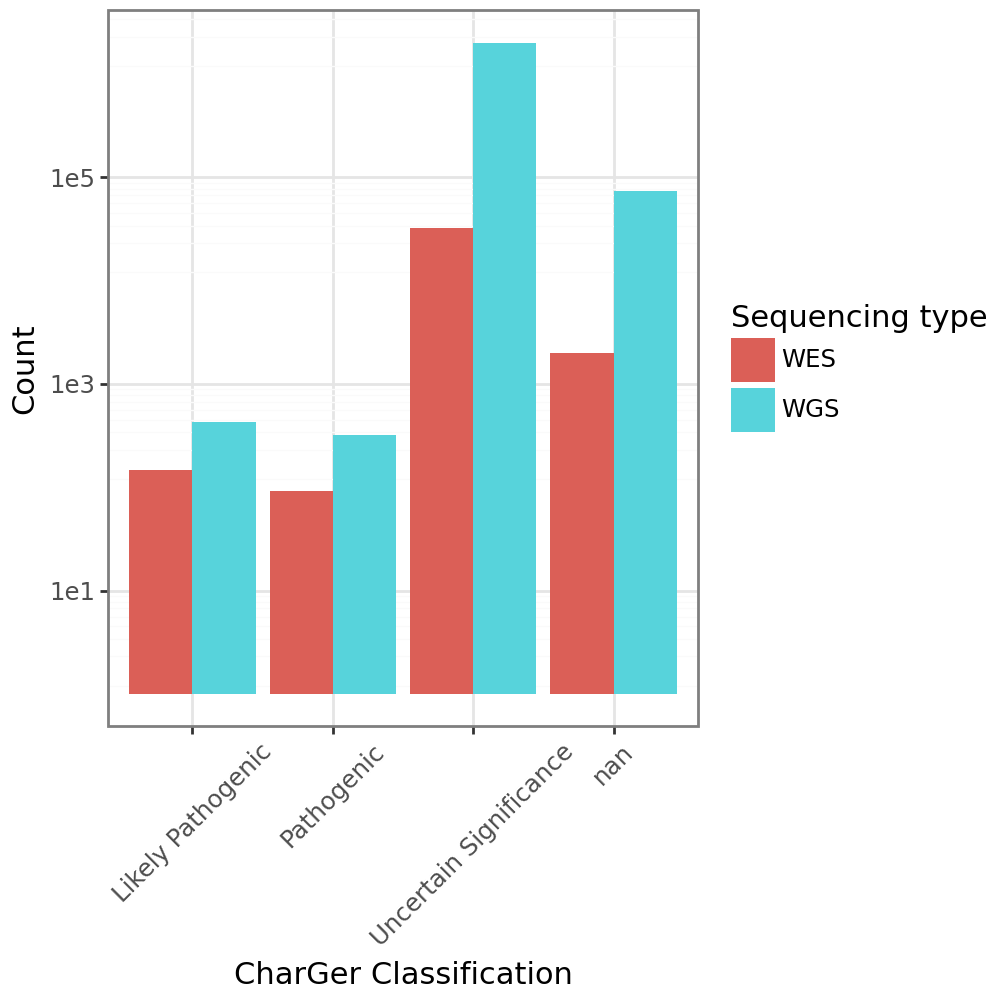

In [55]:
p_charger = (
    pn.ggplot(variants, pn.aes(x='ACMG_Classification', fill='infered_seq_type'))
    + pn.geom_bar(position='dodge')
    + pn.theme_bw()
    + pn.theme(
        axis_text_x=pn.element_text(rotation=45,),
        figure_size=(5, 5)
    ) 
    + pn.scale_y_log10()
    + pn.labs(
        x="CharGer Classification",
        y="Count",
        fill = "Sequencing type"
    )
)
p_charger

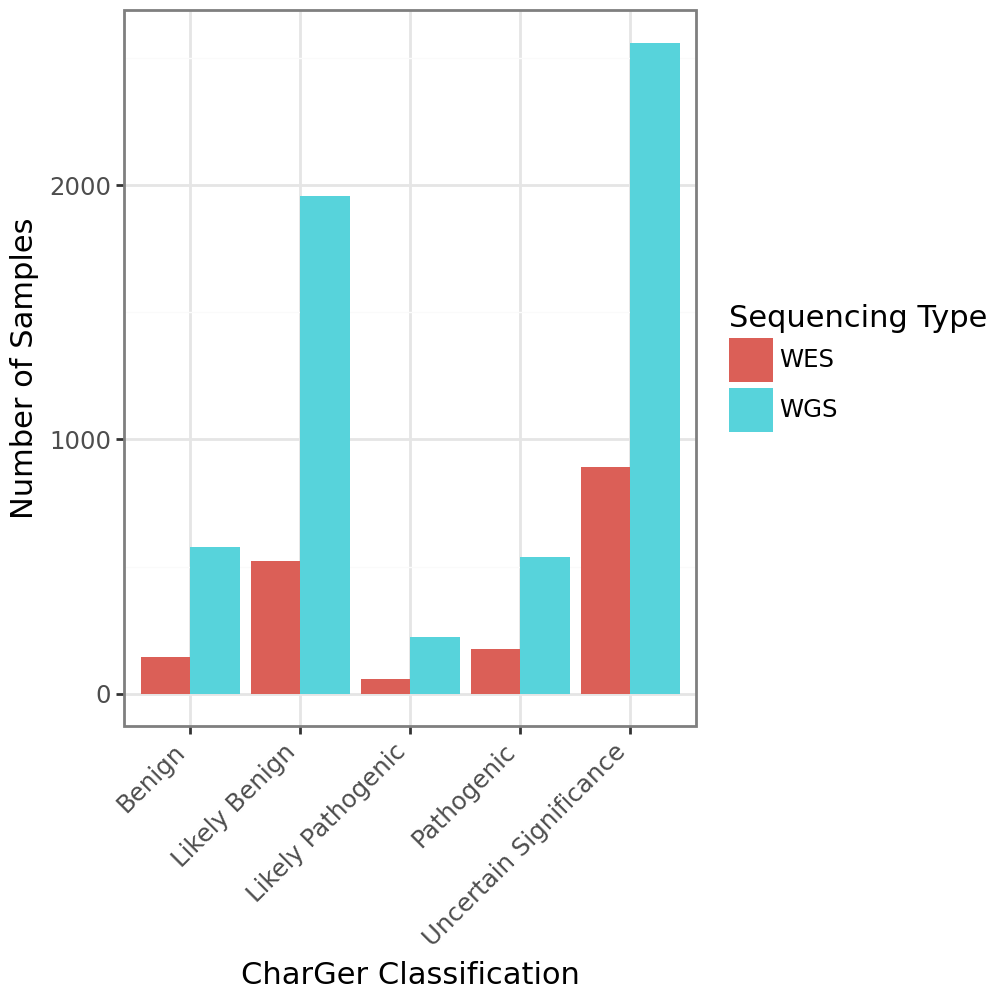

In [67]:
sample_counts = (
    variants
    .groupby(['CharGer_Classification', 'seq_type'])['PID']
    .nunique()
    .reset_index(name='n_samples')
)
p_sample_counts = (
    pn.ggplot(sample_counts, pn.aes(x='CharGer_Classification', y='n_samples', fill='seq_type'))
    + pn.geom_col(position='dodge')
    + pn.theme_bw()
    + pn.theme(
        axis_text_x=pn.element_text(rotation=45, hjust=1),
        figure_size=(5, 5)
    )
    + pn.labs(
        x="CharGer Classification",
        y="Number of Samples",
        fill="Sequencing Type"
    )
)

p_sample_counts

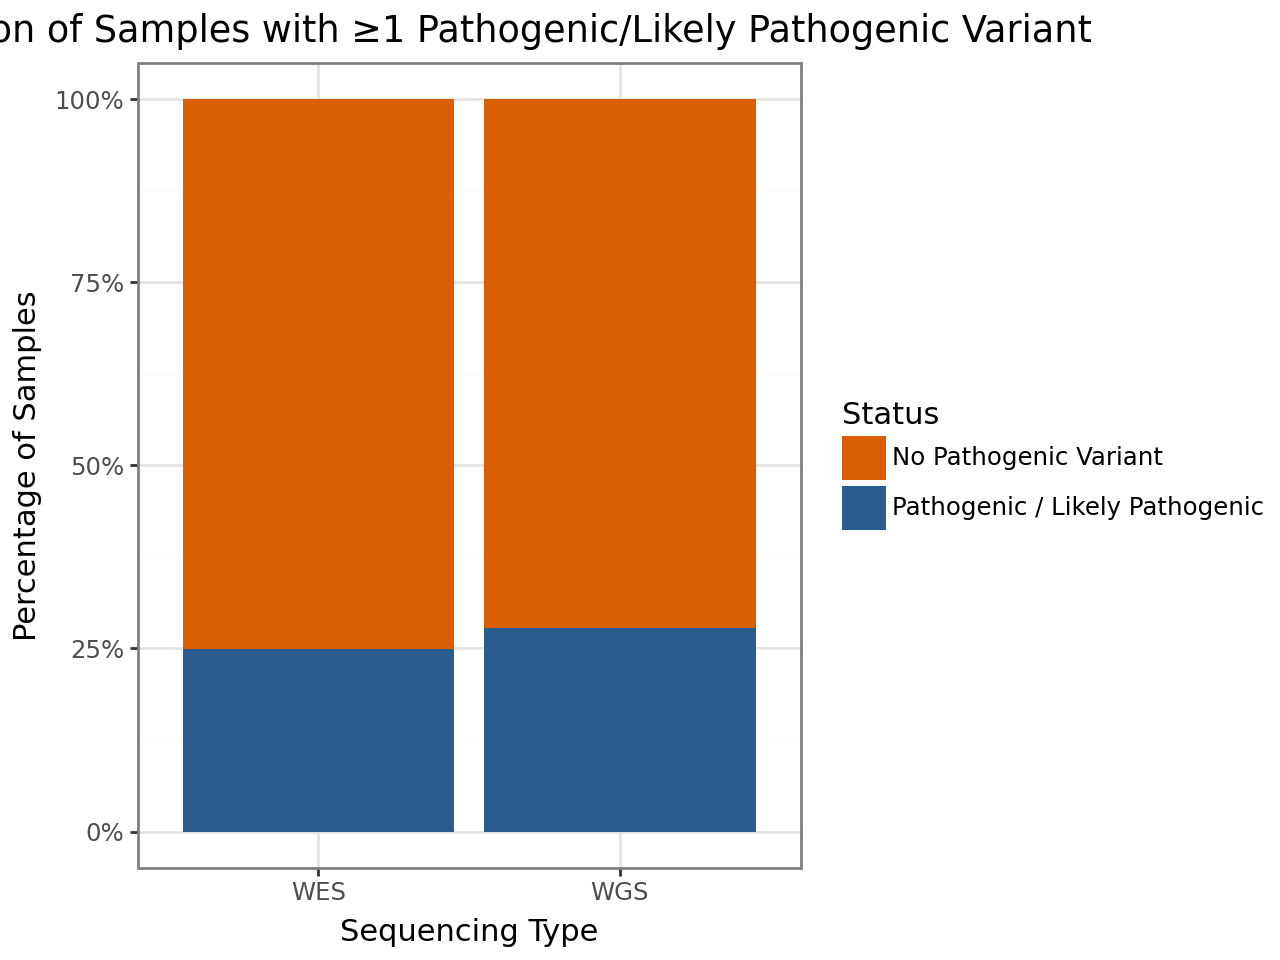

In [81]:


# Define pathogenic categories
path_categories = ['Pathogenic', 'Likely Pathogenic']

# Identify samples with AT LEAST ONE pathogenic / likely pathogenic variant
sample_summary = (
    variants
    .groupby(['PID', 'seq_type'])['CharGer_Classification']
    .apply(lambda x: 'Pathogenic / Likely Pathogenic' if any(c in path_categories for c in x) else 'No Pathogenic Variant')
    .reset_index(name='status')
)

# Optional: Calculate percentages to print out directly
cohort_stats = sample_summary['status'].value_counts(normalize=True) * 100

p_sample_status = (
    pn.ggplot(sample_summary, pn.aes(x='seq_type', fill='status'))
    + pn.geom_bar(position='fill')
    + pn.scale_y_continuous(labels=lambda l: [f"{int(x*100)}%" for x in l])
    + pn.scale_fill_manual(values=['#d95f02', '#2b5c8f']) # Orange for Pathogenic, Blue for No Pathogenic
    + pn.theme_bw()
    + pn.labs(
        title="Proportion of Samples with ≥1 Pathogenic/Likely Pathogenic Variant",
        x="Sequencing Type",
        y="Percentage of Samples",
        fill="Status"
    )
)

p_sample_status

status
No Pathogenic Variant             2639
Pathogenic / Likely Pathogenic     812
Name: count, dtype: int64


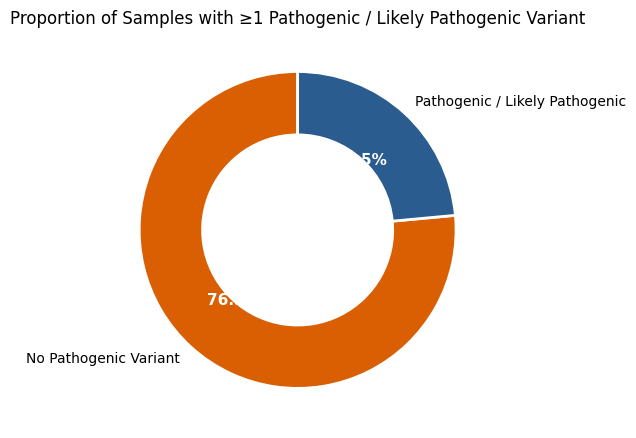

In [111]:

path_categories = ['Pathogenic', 'Likely Pathogenic']

# Identify samples with AT LEAST ONE pathogenic / likely pathogenic variant
sample_summary = (
    variants
    .groupby(['PID', 'seq_type'])['ACMG_Classification']
    .apply(lambda x: 'Pathogenic / Likely Pathogenic' if any(c in path_categories for c in x) else 'No Pathogenic Variant')
    .reset_index(name='status')
)

# 1. Calculate counts & percentages
counts = sample_summary['status'].value_counts()
print(counts)
# 2. Plot Donut Chart
fig, ax = plt.subplots(figsize=(6, 6))

colors = ['#d95f02', '#2b5c8f']  # Orange for Pathogenic, Blue for No Pathogenic
wedges, texts, autotexts = ax.pie(
    counts, 
    labels=counts.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2) # Creates the donut hole
)

# Style percentage text
plt.setp(autotexts, size=11, weight="bold", color="white")
plt.title("Proportion of Samples with ≥1 Pathogenic / Likely Pathogenic Variant", fontsize=12)

plt.tight_layout()
plt.show()

In [61]:
protein_tier3.head()

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [67]:
gene_tier3 = pd.read_csv("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/results/res_202606/dna_first_gene_underexpression_tier3_vus_spliceai_gt0_2.tsv", sep="\t")
protein_tier3 = pd.read_csv("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/results/res_202606/dna_first_protein_underexpression_tier3_vus_spliceai_gt0_2.tsv", sep="\t") 
splicing_tier3 = pd.read_csv("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/results/res_202606/gene_splicing_tier3_vus_spliceai_gt0_1.tsv", sep="\t") 


gene_tier3["pid"] = gene_tier3["nct_pid"].str.split("_").str[0]
gene_tier3["Evidence"] = "Gene expression"

protein_tier3["pid"] = protein_tier3["nct_pid"].str.split("_").str[0]
protein_tier3["Evidence"] = "Protein expression"

splicing_tier3["pid"] = splicing_tier3["nct_pid"].str.split("_").str[0]
splicing_tier3["Evidence"] = "Gene splicing"

omic_evidence = pd.concat((gene_tier3[["pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "germline_CharGer_Classification", "germline_ACMG_Classification", "Evidence", "germline_max_spliceai_score"]], 
                          protein_tier3[["pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "germline_CharGer_Classification", "germline_ACMG_Classification", "Evidence", "germline_max_spliceai_score"]], 
                          splicing_tier3[["pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "germline_CharGer_Classification", "germline_ACMG_Classification", "Evidence", "germline_max_spliceai_score"]],)) 
omic_evidence["Evidence"].value_counts()
variants_exp = variants.merge(omic_evidence[["pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT", "germline_CharGer_Classification", "germline_ACMG_Classification", "Evidence"]], how = "left", left_on=["PID", "#CHROM", "POS", "REF", "ALT"], right_on=["pid", "germline_chrom", "germline_POS", "germline_REF", "germline_ALT"] )


In [74]:
variants.head()

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [68]:
variants_exp["germline_max_spliceai_score"]

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [65]:
variants_exp.loc[variants_exp["germline_ACMG_Classification"].isna(), "germline_ACMG_Classification" ] = variants_exp.loc[variants_exp["germline_ACMG_Classification"].isna(), "ACMG_Classification" ]


In [70]:
variants_exp[(variants_exp["Evidence"].notna()) & (variants_exp["variant_class"] == "coding")][["germline_abexp_v1.1", "germline_Consequence", "germline_IMPACT", "germline_promoterAI", "germline_max_spliceai_score"]]

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


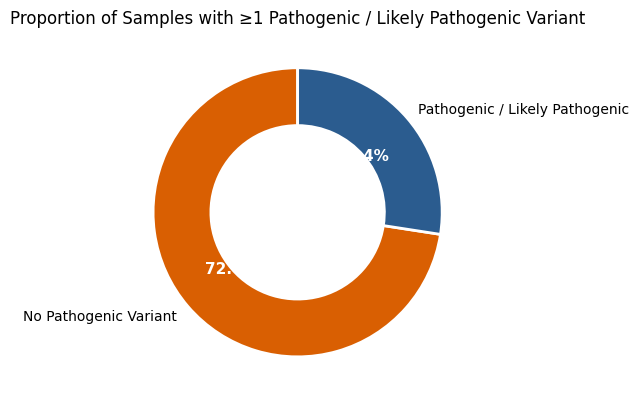

In [45]:

# Identify samples with AT LEAST ONE pathogenic / likely pathogenic variant
path_categories = ['Pathogenic', 'Likely Pathogenic', 'Omics Likely Pathogenic']

sample_summary = (
    variants_exp
    .groupby(['PID', 'infered_seq_type'])['germline_ACMG_Classification']
    .apply(lambda x: 'Pathogenic / Likely Pathogenic' if any(c in path_categories for c in x) else 'No Pathogenic Variant')
    .reset_index(name='status')
)

# 1. Calculate counts & percentages
counts = sample_summary['status'].value_counts()
# Define pathogenic categories



# 2. Plot Donut Chart
fig, ax = plt.subplots(figsize=(6, 6))

colors = ['#d95f02', '#2b5c8f']  # Orange for Pathogenic, Blue for No Pathogenic
wedges, texts, autotexts = ax.pie(
    counts, 
    labels=counts.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2) # Creates the donut hole
)

# Style percentage text
plt.setp(autotexts, size=11, weight="bold", color="white")
plt.title("Proportion of Samples with ≥1 Pathogenic / Likely Pathogenic Variant", fontsize=12)

plt.tight_layout()
plt.show()

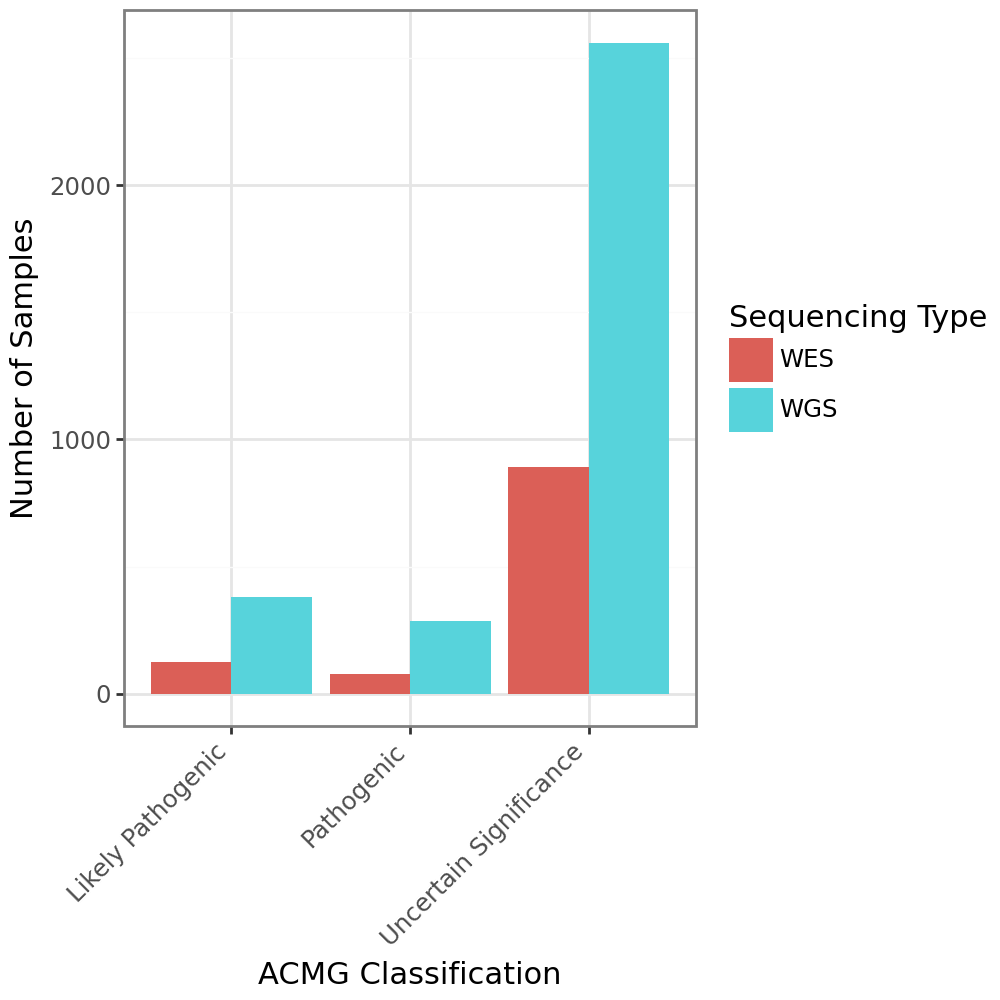

In [69]:
sample_counts = (
    variants
    .groupby(['ACMG_Classification', 'seq_type'])['PID']
    .nunique()
    .reset_index(name='n_samples')
)
p_sample_counts = (
    pn.ggplot(sample_counts, pn.aes(x='ACMG_Classification', y='n_samples', fill='seq_type'))
    + pn.geom_col(position='dodge')
    + pn.theme_bw()
    + pn.theme(
        axis_text_x=pn.element_text(rotation=45, hjust=1),
        figure_size=(5, 5)
    )
    + pn.labs(
        x="ACMG Classification",
        y="Number of Samples",
        fill="Sequencing Type"
    )
)

p_sample_counts

In [49]:
variants_exp["germline_ACMG_Classification"].value_counts()

variants_exp["ACMG_Classification"].value_counts()


Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [51]:
labels = [
    # No RNA (Left)
    "Pathogenic (n=408)",                 # Node 0
    "Likely pathogenic (n=578)",         # Node 1
    "Uncertain significance (n=2051459)",# Node 2
    # With RNA (Right)
    "Pathogenic (n=408)",                 # Node 3
    "Likely pathogenic (n=578)",         # Node 4
    "Uncertain significance (n=2051259)",# Node 5
    "Omics Likely Pathogenic (n=205)"     # Node 6
]

# 2. Map Flows: [Source Index] -> [Target Index]
sources = [
    0,       # Pathogenic (No RNA)
    1,       # Likely pathogenic (No RNA)
    2,       # VUS (No RNA) -> stays VUS
    2        # VUS (No RNA) -> reclassifies to Omics LP
]

targets = [
    3,       # Pathogenic (With RNA)
    4,       # Likely pathogenic (With RNA)
    5,       # VUS (With RNA)
    6        # Omics Likely Pathogenic (With RNA)
]

# 3. Define Flow Counts (Values)
values = [
    np.log(408),     # 408 Pathogenic stay Pathogenic
    np.log(578),     # 578 Likely pathogenic stay Likely pathogenic
    np.log(2051259), # 2,051,259 VUS remain VUS
    np.log(205)      # 205 VUS shift to Omics Likely Pathogenic
]

# 4. Define Color Palette (Matching left/right nodes for visual clarity)
colors = [
    "#d95f6e", "#e08d62", "#e8c887",  # Left nodes (Red, Orange, Yellow)
    "#d95f6e", "#e08d62", "#e8c887", "#4c82a1" # Right nodes (+ Blue for Omics LP)
]

fig = go.Figure(data=[go.Sankey(
    node = dict(
      pad = 20,
      thickness = 25,
      line = dict(color = "black", width = 0.5),
      label = labels,
      color = colors
    ),
    link = dict(
      source = sources,
      target = targets,
      value = values,
      # Optional: make the link flow colors semi-transparent
      color = [
          "rgba(217, 95, 110, 0.4)",  # Pathogenic
          "rgba(224, 141, 98, 0.4)",  # Likely pathogenic
          "rgba(232, 200, 135, 0.4)", # VUS -> VUS
          "rgba(76, 130, 161, 0.7)"   # VUS -> Omics LP (Highlighted)
      ]
  )
)])

fig.update_layout(
    title_text="Variant Reclassification: No RNA vs. With RNA",
    font_size=13,
    height=600
)

fig.show()

# gene expression

In [17]:
or_res_path = "/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/py_outrider_runs/all_cohorts/oht_cov_diag_lr_0_0001_epoc200_gpu/or_variants_interesting_genes_padjust_cnv.parquet"
needed_cols = ["sampleID", "zScore", "pValue", "padjust", "IMPACT", "geneID",  "geneID_short",
               "padjust_predisp", "padjust_predisp_extended", "CNV", "padjust_genes_of_interest"]
# py_or_res_all = pl.scan_parquet(or_res_path).select(needed_cols).filter((pl.col("geneID_short").is_in(genes_of_interest[(genes_of_interest["cgc"].isna()) |(genes_of_interest["ROLE_IN_CANCER"].str.contains("TSG"))]["geneID_short"]))).collect().to_pandas()

or_res_path = "/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/py_outrider_runs/all_cohorts/oht_cov_diag_lr_0_0001_epoc200_gpu/or_variants_tsg_predisp_padjust_cnv.parquet"

py_or_res_all = pl.scan_parquet(or_res_path).filter(pl.col("padjust_bh_dna_first_tsg_predisp") <= 0.1).collect().to_pandas()


py_or_res_all["Method"] = "OUTRIDER"

# py_or_res_all = py_or_res_all[(py_or_res_all["padjust_predisp_extended"] <= 0.05) | (py_or_res_all["padjust"] <= 0.05)]


py_or_res_all = pd.merge(py_or_res_all, sa[["pid", "Diag", "seq_type", "Oncotree Code", "Oncotree Text", "nct_pid", "Tumorzellgehalt (Bioinformatik)"]], left_on="sampleID", right_on="pid")
py_or_res_all = pd.merge(py_or_res_all, gene_annot_dt.drop(columns="geneID_short"), left_on="geneID", right_on="gene_id", how="left")



In [18]:
print(dresden_germline.shape)
or_outliers_merged = dresden_germline.merge(py_or_res_all, right_on=["sampleID", "geneID_short"], left_on=["PID", "Gene"], how="left")
print(or_outliers_merged.shape)

(2127488, 206)
(2127488, 261)


In [19]:
or_outliers_merged = or_outliers_merged[or_outliers_merged["Gene"].isin(genes_of_interest[(genes_of_interest["cgc"].isna()) |(genes_of_interest["ROLE_IN_CANCER"].str.contains("TSG"))]["geneID_short"])]

or_outliers_merged["Outlier status"] = False
or_outliers_merged.loc[or_outliers_merged["zScore"] <= 0, "Outlier status"] = True


In [20]:
or_outliers_merged.shape
expression_vars = or_outliers_merged[(or_outliers_merged["germline_abexp_v1.1"] <= -0.1) 
    | (or_outliers_merged["germline_IMPACT"] == "HIGH") 
    | (or_outliers_merged["germline_promoterAI"] <= -0.1 ) 
    | (or_outliers_merged["germline_max_spliceai_score"] >= 0.1 ) 
    ]


expression_vars["germline_ACMG_Classification"].value_counts(dropna=False)



expression_vars = add_missing_acmgs(expression_vars)

In [21]:
expression_vars.shape

(22039, 261)

In [76]:
expression_vars[(expression_vars["Outlier status"] == True) ]["germline_ACMG_Classification"].value_counts(dropna=False)
# expression_vars[(expression_vars["Outlier status"] == True) & (expression_vars["germline_ACMG_Classification"].isna()) ]
expression_vars[(expression_vars["geneID_short"].isin(AD_inheritence["geneID_short"])) & (expression_vars["Outlier status"] == True) ]["germline_ACMG_Classification"].value_counts()


# expression_vars[(expression_vars["geneID_short"].isin(AD_inheritence["geneID_short"])) & (expression_vars["Outlier status"] == True) ]["PID"].unique()
# expression_vars[(expression_vars["geneID_short"].isin(AD_inheritence["geneID_short"])) & (expression_vars["Outlier status"] == True) & (expression_vars["germline_ACMG_Classification"] != "Uncertain Significance")]["PID"].unique()
gene_under_expression_tsg_predips = expression_vars[(expression_vars["Outlier status"] == True) & (expression_vars["germline_ACMG_Classification"] == "Uncertain Significance")]

gene_under_expression_AD_samples = expression_vars[(expression_vars["geneID_short"].isin(AD_inheritence["geneID_short"])) & (expression_vars["Outlier status"] == True) & (expression_vars["germline_ACMG_Classification"] != "Uncertain Significance")]["PID"].unique()
gene_under_expression_AD_samples


<ArrowStringArray>
[ 'NULZFV',  'FT48YD',  '9LDWR7',  'L3ABZV',  'DVJJ5N',  'BDNR5D',  'DX3UW1',
  'EV5NG5',  'JDDYR6',  'GPCJUP',  '1X5TZJ',  '2YLHAZ', 'HTJ5UBQ',  'N9RAUJ',
  'CEFU8J',  'AWCFTE',  'RRTP2Y',  'HBTTLZ',  'XBLS3R',  '2UGFMT',  'VJ9DCA',
  '6H2B7A',  'W1WR7Y', 'U72ATSC',  'W2G3H9',  '6VGTMQ',  'GHQ344',  'RZ4UBF',
  'CBCJVV',  '7CCGJ4',  'FRJ1TB',  '2GW26G',  'NPY8VX',  '4TN556',  'HE2H4F',
  'BDGX7Y',  'T82USU',  'K55YZ3',  '9BRWLP',  'T62214',  '5B22ZE',  'YVV1AM',
  'QMVRLC',  'DK4BZD',  'QM4LSB',  '5867EC',  'WF6LJM',  '6P5GUW',  'P6487B',
  'VR4YA3',  'NVDER5',  'PMVK1Y',  'JNMLVC',  'Y78RB8',  '7LDHWB',  '7Z6NJK',
  '5CMLW9',  'N9VAC1',  'LTDE4Z']
Length: 59, dtype: str

In [81]:
gene_under_expression_tsg_predips['variant_class'] = gene_under_expression_tsg_predips['germline_Consequence'].str.contains(
    coding_pattern, 
    regex=True, 
    na=False
).map({True: 'Coding', False: 'Non-coding'})
gene_under_expression_tsg_predips["Omic"] = "Gene underexpression outlier"
# gene_under_expression_tsg_predips = gene_under_expression_tsg_predips[["#CHROM", "REF", "POS", "ALT", "Gene", "Omic"]]


Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [75]:
expression_vars[(expression_vars["Outlier status"] == True) & (expression_vars["germline_ACMG_Classification"] == "Uncertain Significance") ]["variant_class"].value_counts()

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


## some plotting

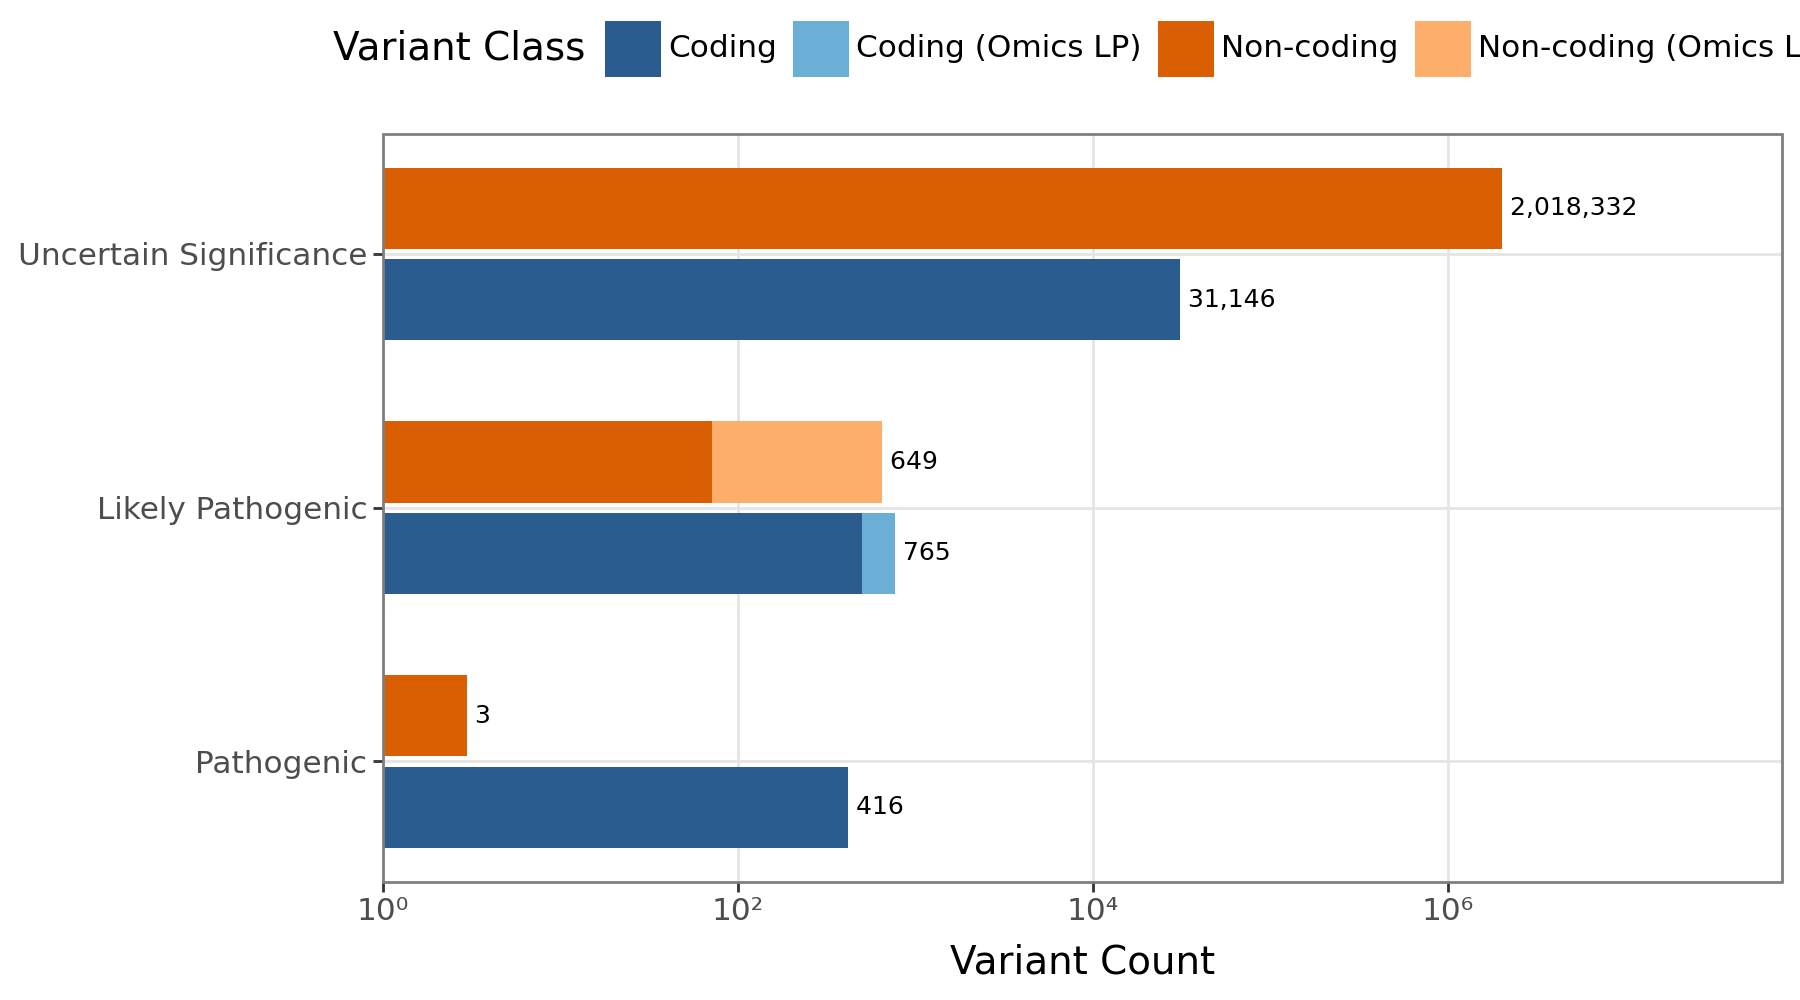

In [20]:


# 1. Start with data, deduplicate, and identify Outliers
df_data = or_outliers_merged.copy()
df_data = df_data.drop_duplicates(
    subset=["PID", "SYMBOL", "#CHROM", "POS", "REF", "ALT"]
)

df_data["germline_Consequence"] = df_data["germline_Consequence"].fillna("")

is_outlier = (
(or_outliers_merged["germline_abexp_v1.1"] <= 0.1) 
    | (or_outliers_merged["germline_IMPACT"] == "HIGH") 
    | (or_outliers_merged["germline_promoterAI"] <= -0.1 ) 
    | (or_outliers_merged["germline_max_spliceai_score"] >= 0.1 ) 
) & (df_data["padjust_bh_dna_first_tsg_predisp"] <= 0.1)

# 2. Reclassify VUS Outliers -> "Likely Pathogenic (Omics LP)"
df_data["ACMG_reclassified"] = df_data["germline_ACMG_Classification"].astype(
    str
)

vus_outliers_mask = (
    df_data["germline_ACMG_Classification"] == "Uncertain Significance"
) & is_outlier

df_data.loc[vus_outliers_mask, "ACMG_reclassified"] = (
    "Likely Pathogenic (Omics LP)"
)

# 3. Aggregate counts
df_counts = (
    df_data.groupby(
        ["variant_class", "ACMG_reclassified"], observed=False
    )
    .size()
    .reset_index(name="count")
)
df_counts = df_counts[df_counts["count"] > 0].copy()

# 4. Define category mapping & plot axes
df_counts["ACMG_plot_axis"] = df_counts["ACMG_reclassified"].replace(
    {"Likely Pathogenic (Omics LP)": "Likely Pathogenic"}
)

df_counts["fill_group"] = df_counts["variant_class"].astype(str)
df_counts.loc[
    df_counts["ACMG_reclassified"] == "Likely Pathogenic (Omics LP)",
    "fill_group",
] = (df_counts["variant_class"].astype(str) + " (Omics LP)")

# Map categorical Y-axis values to integers (1, 2, 3)
acmg_map = {
    "Pathogenic": 1,
    "Likely Pathogenic": 2,
    "Uncertain Significance": 3,
}
df_counts["x_numeric"] = df_counts["ACMG_plot_axis"].map(acmg_map)

# Order fill levels (Base first, then Omics LP)
fill_order = [
    "Coding",
    "Coding (Omics LP)",
    "Non-coding",
    "Non-coding (Omics LP)",
]
df_counts["fill_group"] = pd.Categorical(
    df_counts["fill_group"], categories=fill_order, ordered=True
)

# Sort to calculate cumulative bounds correctly
df_counts = df_counts.sort_values(
    ["variant_class", "x_numeric", "fill_group"]
)

# Calculate cumulative start (ymin) and end (ymax) for stacked segments
df_counts["ymax"] = df_counts.groupby(["variant_class", "x_numeric"])[
    "count"
].cumsum()
df_counts["ymin"] = df_counts["ymax"] - df_counts["count"]

# Make ymin = 1 for log scale rendering if it starts at 0
df_counts["ymin"] = df_counts["ymin"].replace(0, 1)

# Calculate manual X positions (Dodging Coding vs Non-coding)
bar_width = 0.32
dodge_offset = 0.18

# Coding sits at (x - dodge_offset), Non-coding at (x + dodge_offset)
df_counts["x_center"] = np.where(
    df_counts["variant_class"] == "Coding",
    df_counts["x_numeric"] - dodge_offset,
    df_counts["x_numeric"] + dodge_offset,
)
df_counts["xmin"] = df_counts["x_center"] - (bar_width / 2)
df_counts["xmax"] = df_counts["x_center"] + (bar_width / 2)

# Calculate total bar heights for end labels
df_labels = (
    df_counts.groupby(["variant_class", "x_numeric", "x_center"])[
        "count"
    ]
    .sum()
    .reset_index(name="total_count")
)
df_labels["label"] = df_labels["total_count"].apply(lambda x: f"{x:,}")

# 5. Color Palette Mapping
color_palette = {
    "Coding": "#2b5c8f",  # Dark Blue (Base 502)
    "Coding (Omics LP)": "#6baed6",  # Light Blue (Stacked VUS outliers 297)
    "Non-coding": "#d95f02",  # Dark Orange (Base 72)
    "Non-coding (Omics LP)": "#fdae6b",  # Light Orange (Stacked VUS outliers 953)
}

superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

# 6. Build Plot using geom_rect
p = (
    pn.ggplot()
    + pn.geom_rect(
        df_counts,
        pn.aes(
            xmin="xmin",
            xmax="xmax",
            ymin="ymin",
            ymax="ymax",
            fill="fill_group",
        ),
    )
    + pn.coord_flip()
    # Add end-of-bar text labels
    + pn.geom_text(
        df_labels,
        pn.aes(x="x_center", y="total_count", label="label"),
        ha="left",
        va="center",
        size=9,
        format_string=" {}",
    )
    + pn.scale_x_continuous(
        breaks=[1, 2, 3],
        labels=["Pathogenic", "Likely Pathogenic", "Uncertain Significance"],
    )
    + pn.scale_y_log10(
        expand=(0, 0, 0.25, 0),
        labels=lambda ticks: [
            f"10{str(int(np.log10(t))).translate(superscript_map)}"
            if t > 0
            else "0"
            for t in ticks
        ],
    )
    + pn.scale_fill_manual(values=color_palette, name="Variant Class")
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(9, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="Variant Count")
)

p

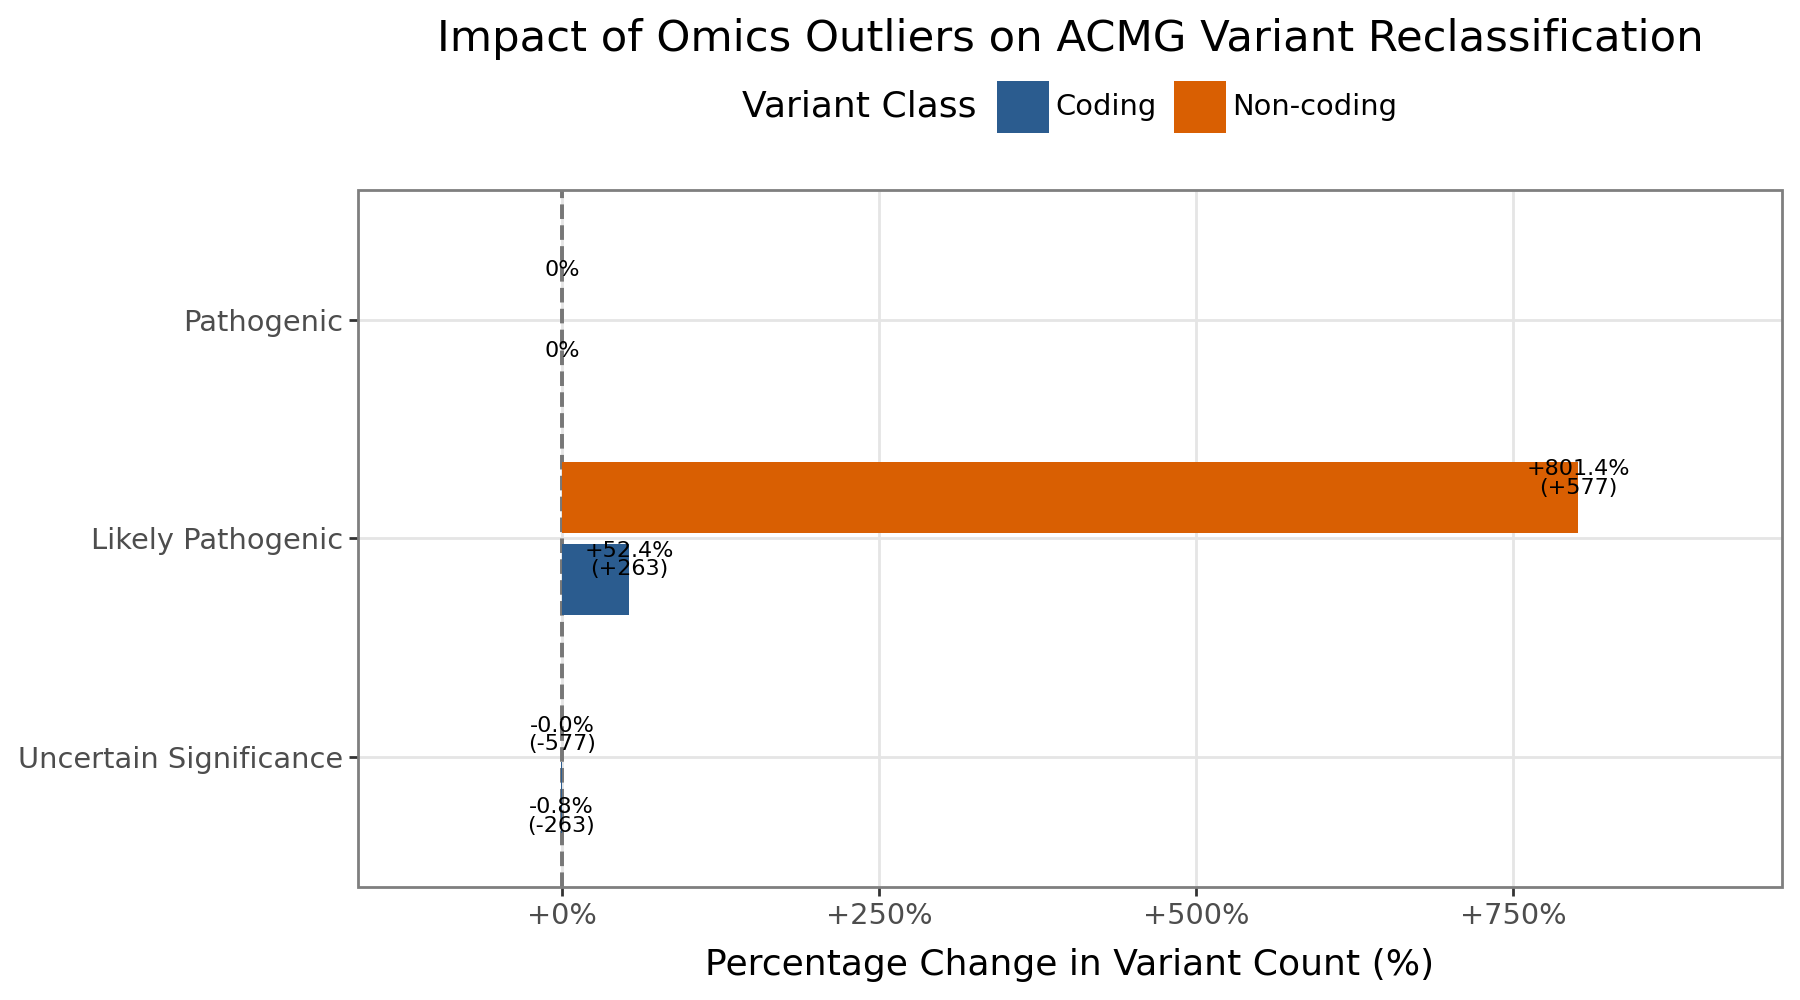

In [33]:

# 1. Start with data and deduplicate
df_data = or_outliers_merged.copy().drop_duplicates(
    subset=["PID", "SYMBOL", "#CHROM", "POS", "REF", "ALT"]
)

df_data["germline_Consequence"] = df_data["germline_Consequence"].fillna("")

# 2. Identify Outliers
is_outlier = (
    (df_data["germline_abexp_v1.1"] <= 0.1)
    | (df_data["germline_IMPACT"] == "HIGH")
    | (df_data["germline_promoterAI"] <= -0.1)
    | (df_data["germline_max_spliceai_score"] >= 0.1)
) & (df_data["padjust_bh_dna_first_tsg_predisp"] <= 0.1)

df_data["is_outlier"] = is_outlier

# 3. Calculate baseline counts per variant class and ACMG tier
df_base = (
    df_data.groupby(["variant_class", "germline_ACMG_Classification"])
    .size()
    .reset_index(name="baseline_count")
)

# Calculate VUS outlier count (to be shifted to LP)
df_reclassified = (
    df_data[
        (df_data["germline_ACMG_Classification"] == "Uncertain Significance")
        & (df_data["is_outlier"])
    ]
    .groupby("variant_class")
    .size()
    .reset_index(name="reclassified_count")
)

# Grid of all ACMG categories and variant classes
acmg_order = ["Pathogenic", "Likely Pathogenic", "Uncertain Significance"]
classes = ["Coding", "Non-coding"]

full_grid = pd.DataFrame(
    pd.MultiIndex.from_product(
        [classes, acmg_order],
        names=["variant_class", "germline_ACMG_Classification"],
    ).tolist(),
    columns=["variant_class", "germline_ACMG_Classification"],
)

# Merge counts together and cast to explicit int types
df_summary = pd.merge(
    full_grid,
    df_base,
    on=["variant_class", "germline_ACMG_Classification"],
    how="left",
).fillna(0)

df_summary = pd.merge(
    df_summary, df_reclassified, on="variant_class", how="left"
).fillna(0)

df_summary["baseline_count"] = df_summary["baseline_count"].astype(int)
df_summary["reclassified_count"] = df_summary["reclassified_count"].astype(int)


# 4. Compute Net Change and Percentage Change
def compute_metrics(row):
    acmg = row["germline_ACMG_Classification"]
    reclass = row["reclassified_count"]
    base = row["baseline_count"]

    if acmg == "Likely Pathogenic":
        delta = reclass
    elif acmg == "Uncertain Significance":
        delta = -reclass
    else:  # Pathogenic
        delta = 0

    pct = (delta / base * 100.0) if base > 0 else 0.0
    return pd.Series([delta, pct], index=["delta_count", "pct_change"])


df_summary[["delta_count", "pct_change"]] = df_summary.apply(
    compute_metrics, axis=1
)

# Formatting and ordering categorical axis
df_summary["ACMG_cat"] = pd.Categorical(
    df_summary["germline_ACMG_Classification"],
    categories=acmg_order,
    ordered=True,
)

# Dynamic text labels
df_summary["label_text"] = df_summary.apply(
    lambda r: f"{r['pct_change']:+.1f}%\n({int(r['delta_count']):+d})"
    if r["delta_count"] != 0
    else "0%",
    axis=1,
)

# Valid string alignments for Matplotlib text placement
# Positive bars: text aligns 'bottom' (to the right of positive bar end)
# Negative bars: text aligns 'top' (to the left of negative bar end)
df_summary["align_pos"] = df_summary["pct_change"].apply(
    lambda x: "bottom" if x >= 0 else "top"
)

# 5. Color Palette Mapping
color_palette = {
    "Coding": "#2b5c8f",  # Blue
    "Non-coding": "#d95f02",  # Orange
}

# 6. Build Plot
p = (
    pn.ggplot(df_summary, pn.aes(x="ACMG_cat", y="pct_change", fill="variant_class"))
    + pn.geom_hline(yintercept=0, linetype="dashed", color="#777777", size=0.8)
    + pn.geom_col(position=pn.position_dodge(width=0.75), width=0.65)
    + pn.geom_text(
        pn.aes(
            label="label_text",
            group="variant_class",
            va="align_pos",  # Uses valid Matplotlib string alignments ('bottom' / 'top')
        ),
        position=pn.position_dodge(width=0.75),
        size=8,
        lineheight=0.9,
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(values=color_palette, name="Variant Class")
    + pn.scale_x_discrete(limits=acmg_order[::-1])  # Pass list slice
    + pn.scale_y_continuous(
        labels=lambda ticks: [f"{t:+.0f}%" for t in ticks],
        expand=(0.2, 0.2),  # Expanded margin so text isn't clipped
    )
    + pn.theme_bw(base_size=13)
    + pn.theme(
        figure_size=(9, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(
        y="Percentage Change in Variant Count (%)",
        title="Impact of Omics Outliers on ACMG Variant Reclassification",
    )
)

p

In [10]:
import plotly.graph_objects as go
import plotly.io as pio

# Enable rendering in Jupyter Notebooks / JupyterLab / Colab
pio.renderers.default = "notebook_connected"

# ---------------------------------------------------------
# 1. Define Nodes (Labels)
# ---------------------------------------------------------
# We redefine the breakdown at the NMD stage using numbers from image_3.png:
# Likely NMD total: 220,214
# Breakdown for NMD stage: 215,338 VUS, 443 Pathogenic, 577 Likely Pathogenic
labels = [
    # Stage 0: Initial Pool
    "Total Rare Germline Small Variants<br>in Tier 3 (2,321,901)",                    # 0

    # Stage 1: Functional Impact Filter (Likely NMD)
    "Likely NMD / Expression Disrupting<br>(220,214)",                               # 1

    # Stage 2: NMD Stage Detailed Breakdown (Splits from node 1)
    "NMD: VUS (215,338)",                                                             # 2
    "NMD: Pathogenic (443)",                                                           # 3
    "NMD: Likely Pathogenic (577)",                                                   # 4

    # Stage 3: Expression Outlier Filter (Sequential path continues from node 1)
    "Gene Underexpression Outlier<br>(613)",                                         # 5

    # Stage 4: AD Gene Filter
    "In Autosomal Dominant Predisposition Gene<br>(162)",                            # 6

    # Stage 5: Final AD Gene Breakdown
    "Final: VUS (95)",                                                                 # 7
    "Final: Pathogenic (63)",                                                          # 8
    "Final: Likely Pathogenic (4)"                                                     # 9
]

# ---------------------------------------------------------
# 2. Define Sequential Flows and Breakdown Branches
# ---------------------------------------------------------
# Standard pipeline flow: Stage 0 -> 1 -> 5 -> 6 -> Breakdown (7, 8, 9)
# NMD Breakdown branches: 1 -> 2, 3, 4
sources = [
    0,      # Tier 3 -> NMD
    1, 1, 1,# NMD -> NMD VUS, NMD Path, NMD Likely Path
    1,      # NMD -> Expression Outlier
    5,      # Expression Outlier -> AD Gene
    6, 6, 6 # AD Gene -> Final VUS, Final Path, Final Likely Path
]

targets = [
    1,      # Target: NMD (220,214)
    2, 3, 4,# Target: NMD breakdowns (Sum = 216,358, smaller than 220,214)
    5,      # Target: Expression Outlier (613)
    6,      # Target: AD Gene (162)
    7, 8, 9 # Target: Final breakdowns (Sum = 162)
]

# ---------------------------------------------------------
# 3. Calculate and Set Proportional Flow Values
# ---------------------------------------------------------
# Note: The sum of the breakdown branches (215,338 + 443 + 577 = 216,358)
# is slightly LESS than the total NMD total (220,214) in image_3.png.
# To keep the visual diagram proportional, we use the sum of these branches
# as the total flow volume into the NMD node.

nmd_vus = 215338
nmd_pathogenic = 443
nmd_likely_pathogenic = 577
nmd_total = nmd_vus + nmd_pathogenic + nmd_likely_pathogenic # Use the sum from image_3.png, not 220,214

tier3_to_nmd_flow = nmd_total # Must be equal to nmd_total for visual consistency

values = [
    tier3_to_nmd_flow,      # 2,321,901 -> 216,358
    nmd_vus,                # 216,358 -> 215,338 NMD VUS
    nmd_pathogenic,         # 216,358 -> 443 NMD Pathogenic
    nmd_likely_pathogenic,  # 216,358 -> 577 NMD Likely Pathogenic
    613,                    # 216,358 -> 613 Expression Outlier (sequential path)
    162,                    # 613 -> 162 AD Gene
    95,                     # 162 -> 95 Final VUS
    63,                     # 162 -> 63 Final Pathogenic
    4                       # 162 -> 4 Final Likely Pathogenic
]

# Proportional blue color gradient
node_colors = [
    "#1f77b4",  # Blue (Initial Pool)
    "#2ca02c",  # Green (Likely NMD)
    "#17becf",  # Cyan (NMD VUS)
    "#d62728",  # Red (NMD Pathogenic)
    "#e377c2",  # Pink (NMD Likely Pathogenic)
    "#ff7f0e",  # Orange (Expression Outlier)
    "#9467bd",  # Purple (AD Gene)
    "#17becf",  # Cyan (Final VUS)
    "#d62728",  # Red (Final Pathogenic)
    "#e377c2"   # Pink (Final Likely Pathogenic)
]

# ---------------------------------------------------------
# 4. Create & Display Sankey Diagram
# ---------------------------------------------------------
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=30,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels,
        color=node_colors
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color="rgba(180, 180, 180, 0.4)"
    )
)])

fig.update_layout(
    title_text="<b>Variant Prioritization Pipeline with NMD Breakdown</b>",
    font_size=12,
    width=1100,
    height=600
)

# Display inline inside notebook
fig.show()

In [23]:


# 1. Categorization
df_plot = or_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_abexp_v1.1"]) > 0]

outlier_labels = {
    "False": "Non outlier",
    "True": "Underexpression outlier"
}

conditions = [
    (df_plot["ACMG_Classification"] == "Uncertain Significance"),
    (df_plot["ACMG_Classification"] == "Likely Pathogenic"),
    (df_plot["ACMG_Classification"] == "Pathogenic"),
]

choices = ["Uncertain Significance", "Likely Pathogenic", "Pathogenic"]
df_plot["plot_group"] = np.select(
    conditions, choices, default="Uncertain Significance"
)

group_order = ["Pathogenic", "Likely Pathogenic", "Uncertain Significance"]
df_plot["plot_group"] = pd.Categorical(
    df_plot["plot_group"], categories=group_order, ordered=True
)


def format_p(p):
    if np.isnan(p):
        return "N/A"
    return f"P = {p:.1e}" if p < 0.001 else f"P = {p:.4f}"


# --- 2. Dynamic Calculation Per Facet Panel ---

# A) Calculate N counts per (Outlier status, plot_group)
n_df = (
    df_plot.groupby(["Outlier status", "plot_group"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

# Keep categorical alignment for x_pos
n_df["x_pos"] = pd.Categorical(
    n_df["plot_group"], categories=group_order, ordered=True
)
n_df["y_pos"] = 0.5  # Position on AbExp Score axis

# B) Calculate Stats (Pathogenic vs VUS) per Outlier status (True vs False)
stats_list = []
y_max = df_plot["germline_abexp_v1.1"].max()
bracket_y = y_max * 1.2

for outlier_val, group in df_plot.groupby("Outlier status"):
    path_vals = group[group["plot_group"] == "Pathogenic"][
        "germline_abexp_v1.1"
    ]
    vus_vals = group[group["plot_group"] == "Uncertain Significance"][
        "germline_abexp_v1.1"
    ]

    p_val = (
        mannwhitneyu(path_vals, vus_vals, alternative="less").pvalue
        if len(path_vals) > 0 and len(vus_vals) > 0
        else np.nan
    )

    stats_list.append(
        {
            "Outlier status": outlier_val,
            "p_label": format_p(p_val),
            "x_start": 1,
            "x_end": 3,
            "x_text": 2.0,
            "bracket_y": bracket_y,
            "text_y": bracket_y * 1.05,
        }
    )

stats_df = pd.DataFrame(stats_list)

# --- 3. Plotting ---
p = (
    pn.ggplot(
        df_plot,
        pn.aes(x="plot_group", y="germline_abexp_v1.1", fill="plot_group"),
    )
    + pn.geom_boxplot(outlier_size=0.5, width=0.7)
    + pn.coord_flip()
    + pn.facet_wrap("Outlier status", labeller=pn.as_labeller(outlier_labels))
    + pn.scale_fill_manual(
        values={
            "Uncertain Significance": "#7f7f7f",
            "Pathogenic": "#782E2A",
            "Likely Pathogenic": "#D9544D",
        },
        guide=None,
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(figure_size=(12, 6), axis_title_y=pn.element_blank())
    + pn.labs(y="AbExp Score")
    # --- Facet-aware Brackets & P-values ---
    + pn.geom_segment(
        pn.aes(
            x="x_start",
            xend="x_end",
            y="bracket_y",
            yend="bracket_y",
            fill=None,
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label", fill=None),
        data=stats_df,
        size=9,
        angle=270,
        inherit_aes=False,
    )
    # --- Facet-aware White Boxed N Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        nudge_x=0.25,  # <--- Nudges labels cleanly without creating extra axis ticks!
        size=8,
        inherit_aes=False,
    )
    + pn.scale_y_continuous(expand=(0.05, 0, 0.25, 0))
)

p

KeyError: 'ACMG_Classification'

In [14]:
or_outliers_merged["germline_ACMG_Classification"].value_counts()

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [29]:


# 1. Preprocessing & Clean Categorization
df_plot = or_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_abexp_v1.1"]) >= 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "underexpression outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Gene underexpression outlier", "Non-outlier"],
    ordered=True,
)

acmg_order_3 = ["Pathogenic", "Likely Pathogenic",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["germline_ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["germline_ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["germline_ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 0.7

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.05  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["germline_ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_abexp_v1.1"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Gene underexpression outlier"
    ]["germline_abexp_v1.1"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="less").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.5

    stats_list.append(
        {
            "germline_ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.18,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="germline_ACMG_Classification",
            y="germline_abexp_v1.1",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Gene underexpression outlier": "#f8766d",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="AbExp Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    + pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

/tmp/ipykernel_2128532/2463979596.py:14: Pandas4Warning:

Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.



TypeError: '<' not supported between instances of 'float' and 'str'

In [21]:
or_outliers_merged["Outlier status"].value_counts(dropna=False)

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


germline_ACMG_Classification
Uncertain Significance    367702
P/LP                         715
Name: count, dtype: int64


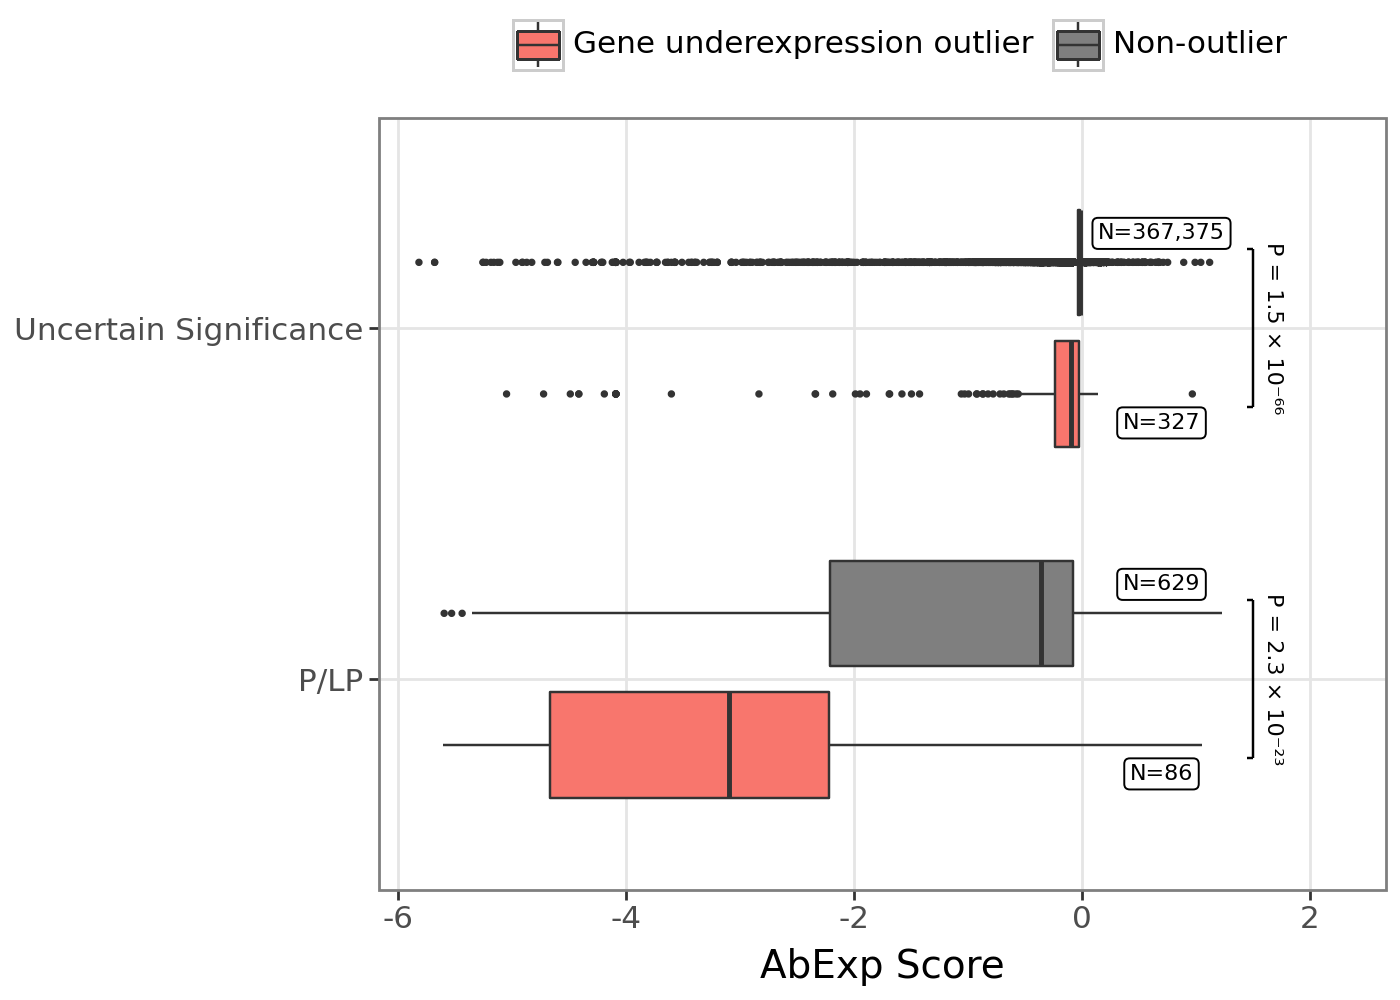

In [56]:


# 1. Preprocessing & Clean Categorization
df_plot = or_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_abexp_v1.1"]) >= 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Gene underexpression outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Gene underexpression outlier", "Non-outlier"],
    ordered=True,
)

df_plot.loc[df_plot["germline_ACMG_Classification"] == "Pathogenic", "germline_ACMG_Classification"] = "Likely Pathogenic"
df_plot.loc[df_plot["germline_ACMG_Classification"] == "Likely Pathogenic", "germline_ACMG_Classification"] = "P/LP"


acmg_order_3 = ["P/LP",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["germline_ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"

print(df_plot["germline_ACMG_Classification"].value_counts())
# 2. Setup N labels
n_df = (
    df_plot.groupby(["germline_ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["germline_ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 0.7

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.05  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["germline_ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_abexp_v1.1"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Gene underexpression outlier"
    ]["germline_abexp_v1.1"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="less").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.5

    stats_list.append(
        {
            "germline_ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.18,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="germline_ACMG_Classification",
            y="germline_abexp_v1.1",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Gene underexpression outlier": "#f8766d",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="AbExp Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    + pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

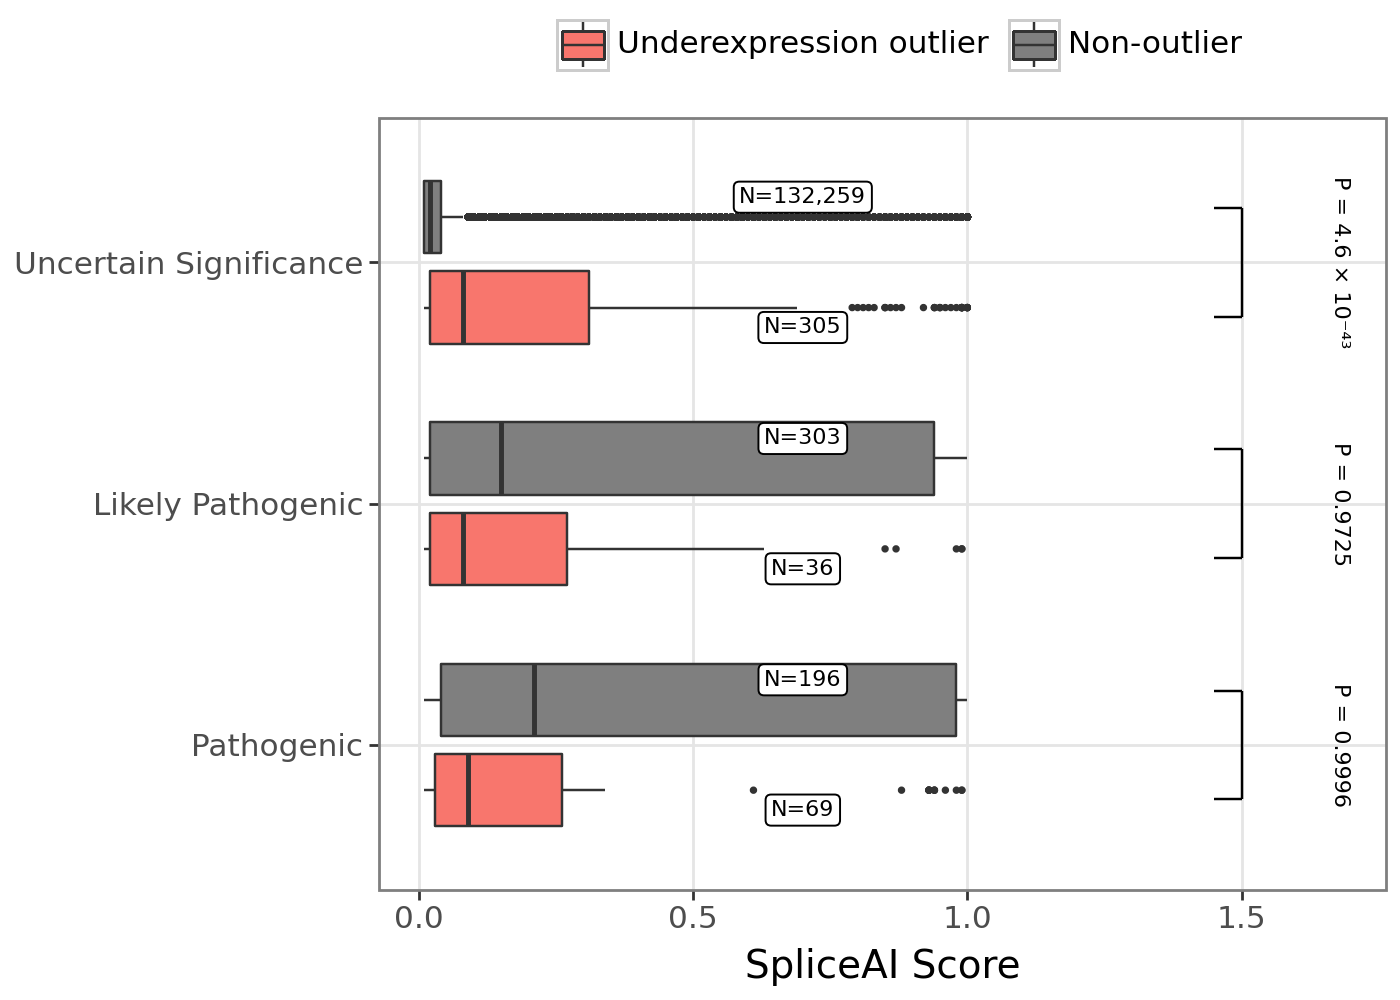

In [13]:


# 1. Preprocessing & Clean Categorization
df_plot = or_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_max_spliceai_score"]) > 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Underexpression outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Underexpression outlier", "Non-outlier"],
    ordered=True,
)

acmg_order_3 = ["Pathogenic", "Likely Pathogenic",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["germline_ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["germline_ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["germline_ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 0.7

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.05  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["germline_ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_max_spliceai_score"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Underexpression outlier"
    ]["germline_max_spliceai_score"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="greater").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.5

    stats_list.append(
        {
            "germline_ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.18,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="germline_ACMG_Classification",
            y="germline_max_spliceai_score",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Underexpression outlier": "#f8766d",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="SpliceAI Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    #+ pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

In [24]:
dresden_germline["germline_max_spliceai_score"].median()
dresden_germline[dresden_germline["germline_ACMG_Classification"].isin(["Likely Pathogenic", "Pathogenic"])]["germline_max_spliceai_score"].median()



np.float64(0.02)

In [ ]:


# 1. Preprocessing & Clean Categorization
df_plot = or_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_max_spliceai_score"]) > 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Underexpression outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Underexpression outlier", "Non-outlier"],
    ordered=True,
)

acmg_order_3 = ["Pathogenic", "Likely Pathogenic",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["germline_ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["germline_ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["germline_ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 0.7

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.05  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["germline_ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_max_spliceai_score"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Underexpression outlier"
    ]["germline_max_spliceai_score"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="greater").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.5

    stats_list.append(
        {
            "germline_ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.18,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="germline_ACMG_Classification",
            y="germline_max_spliceai_score",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Underexpression outlier": "#f8766d",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="SpliceAI Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    #+ pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

# protein expression

In [50]:
pr_output_name = "cov_gaussian_gs_lr_0_001_epoc2000_noInitPCA"

pr_res_all = pl.scan_parquet("/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/protrider_runs/output_" + pr_output_name + "/pr_variants_tsg_predisp_padjust_cnv.parquet").filter(pl.col("padjust_bh_dna_first_tsg_predisp") <= 0.1 ).collect(engine="streaming").to_pandas()
pr_res_all = pd.merge(pr_res_all, dresden_dt_cgc[["geneID_short", "ROLE_IN_CANCER", "predisposition_gene"]], on="geneID_short", how="left")
pr_res_all = pd.merge(pr_res_all, sa[["pid", "Diag", "seq_type", "Oncotree Code", "Oncotree Text", "nct_pid", "Tumorzellgehalt (Bioinformatik)"]], left_on="sampleID", right_on="pid")
pr_res_all["Method"] = "PROTRIDER"



In [51]:
pr_outliers_merged = dresden_germline.merge(pr_res_all, right_on=["sampleID", "geneID_short"], left_on=["PID", "Gene"], how="left")

In [52]:
pr_outliers_merged["Outlier status"] = False
pr_outliers_merged.loc[pr_outliers_merged["zScore"] <= 0, "Outlier status"] = True
pr_outliers_merged = pr_outliers_merged[pr_outliers_merged["Gene"].isin(genes_of_interest[(genes_of_interest["cgc"].isna()) |(genes_of_interest["ROLE_IN_CANCER"].str.contains("TSG"))]["geneID_short"])]


In [53]:
pr_outliers_merged.shape
pr_expression_vars = pr_outliers_merged[(pr_outliers_merged["germline_abexp_v1.1"] <= -0.1) 
    | (pr_outliers_merged["germline_IMPACT"] == "HIGH") 
    | (pr_outliers_merged["germline_promoterAI"] <= -0.1 ) 
    | (pr_outliers_merged["germline_max_spliceai_score"] >= 0.1 )
    | (pr_outliers_merged["germline_Consequence"].str.contains("missense") )
    ]
print(pr_expression_vars.shape)

pr_expression_vars["germline_ACMG_Classification"].value_counts()

pr_expression_vars = add_missing_acmgs(expression_vars)

(36302, 265)


In [54]:
pr_expression_vars[pr_expression_vars["Outlier status"] == True]["germline_ACMG_Classification"].value_counts(dropna=False)
# pr_expression_vars[(pr_expression_vars["Outlier status"] == True) & (pr_expression_vars["germline_ACMG_Classification"].isna())]

# pr_expression_vars[(pr_expression_vars["Outlier status"] == True) & (pr_expression_vars["geneID_short"].isin(AD_inheritence["geneID_short"]))]["germline_ACMG_Classification"].value_counts(dropna=False)




Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [84]:
pr_predisp_tsg_samples = pr_expression_vars[(pr_expression_vars["Outlier status"] == True) & 
    (pr_expression_vars["germline_ACMG_Classification"] == "Uncertain Significance") ]["PID"].unique() 

pr_AD_samples = pr_expression_vars[(pr_expression_vars["Outlier status"] == True) & 
    (pr_expression_vars["germline_ACMG_Classification"] == "Uncertain Significance") & (pr_expression_vars["geneID_short"].isin(AD_inheritence["geneID_short"]))]["PID"].unique()

pr_predisp_tsg = pr_expression_vars[(pr_expression_vars["Outlier status"] == True) & 
    (pr_expression_vars["germline_ACMG_Classification"] == "Uncertain Significance") ]
pr_predisp_tsg['variant_class'] = pr_predisp_tsg['germline_Consequence'].str.contains(
    coding_pattern, 
    regex=True, 
    na=False
).map({True: 'Coding', False: 'Non-coding'})
pr_predisp_tsg["Omic"] = "Protein underexpression outlier"
pr_predisp_tsg["variant_class"].value_counts()


Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


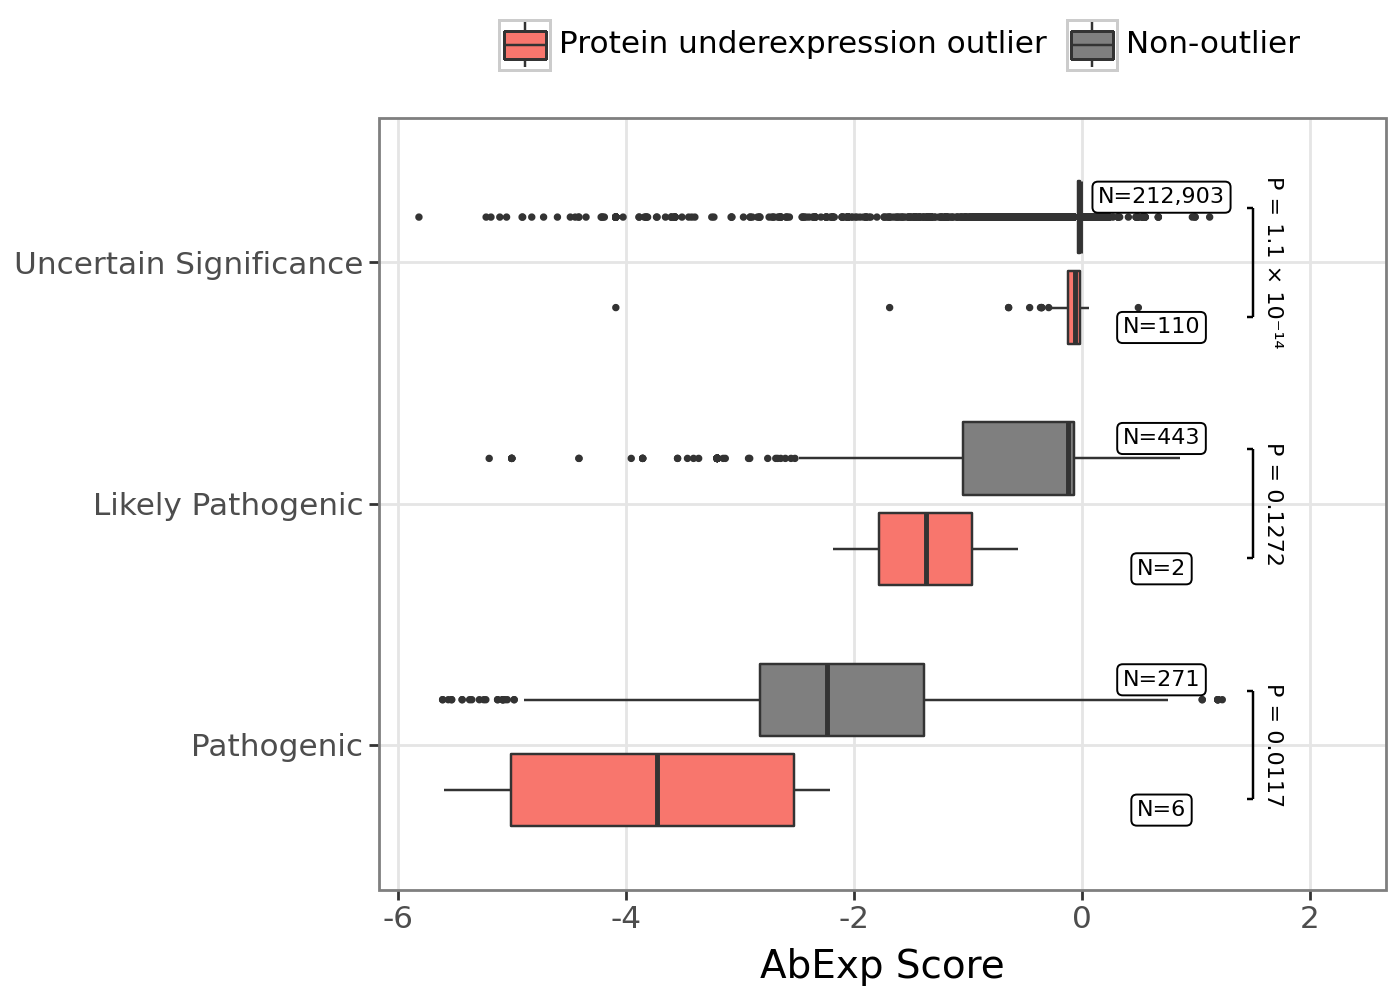

In [36]:


# 1. Preprocessing & Clean Categorization
df_plot = pr_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_abexp_v1.1"]) > 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Protein underexpression outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Protein underexpression outlier", "Non-outlier"],
    ordered=True,
)

acmg_order_3 = ["Pathogenic", "Likely Pathogenic",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 0.7

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.05  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_abexp_v1.1"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Protein underexpression outlier"
    ]["germline_abexp_v1.1"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="less").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.5

    stats_list.append(
        {
            "ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.18,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="ACMG_Classification",
            y="germline_abexp_v1.1",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Protein underexpression outlier": "#f8766d",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="AbExp Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    + pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

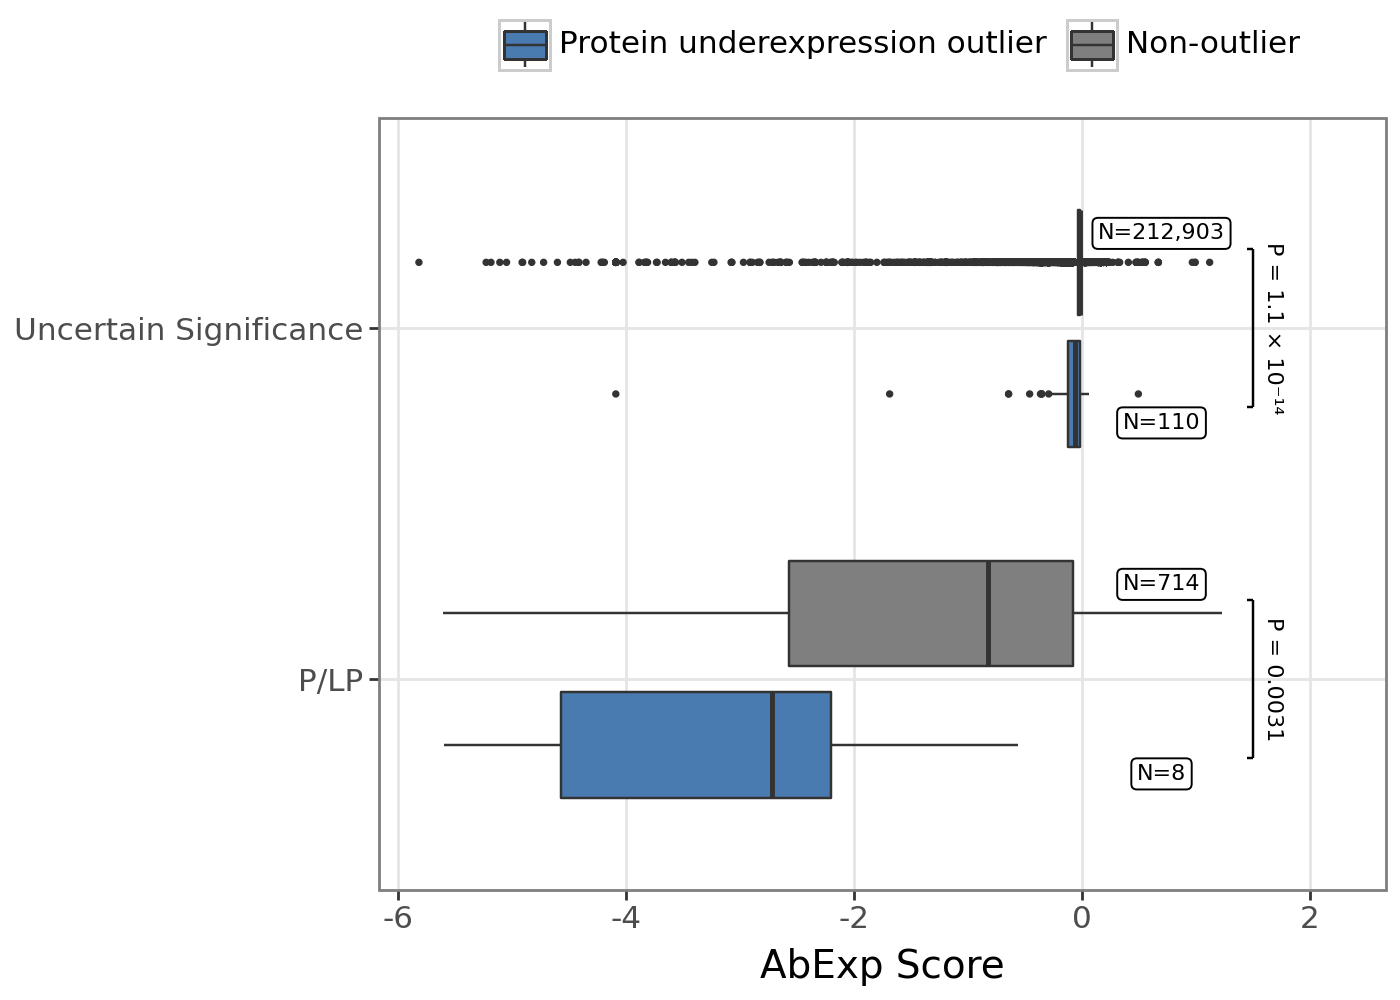

In [40]:


# 1. Preprocessing & Clean Categorization
df_plot = pr_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_abexp_v1.1"]) > 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Protein underexpression outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Protein underexpression outlier", "Non-outlier"],
    ordered=True,
)

df_plot.loc[df_plot["germline_ACMG_Classification"] == "Pathogenic", "germline_ACMG_Classification"] = "Likely Pathogenic"
df_plot.loc[df_plot["germline_ACMG_Classification"] == "Likely Pathogenic", "germline_ACMG_Classification"] = "P/LP"


acmg_order_3 = ["P/LP",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 0.7

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.05  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_abexp_v1.1"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Protein underexpression outlier"
    ]["germline_abexp_v1.1"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="less").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.5

    stats_list.append(
        {
            "ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.18,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="ACMG_Classification",
            y="germline_abexp_v1.1",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Protein underexpression outlier":  "#4A7BB0",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="AbExp Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    + pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

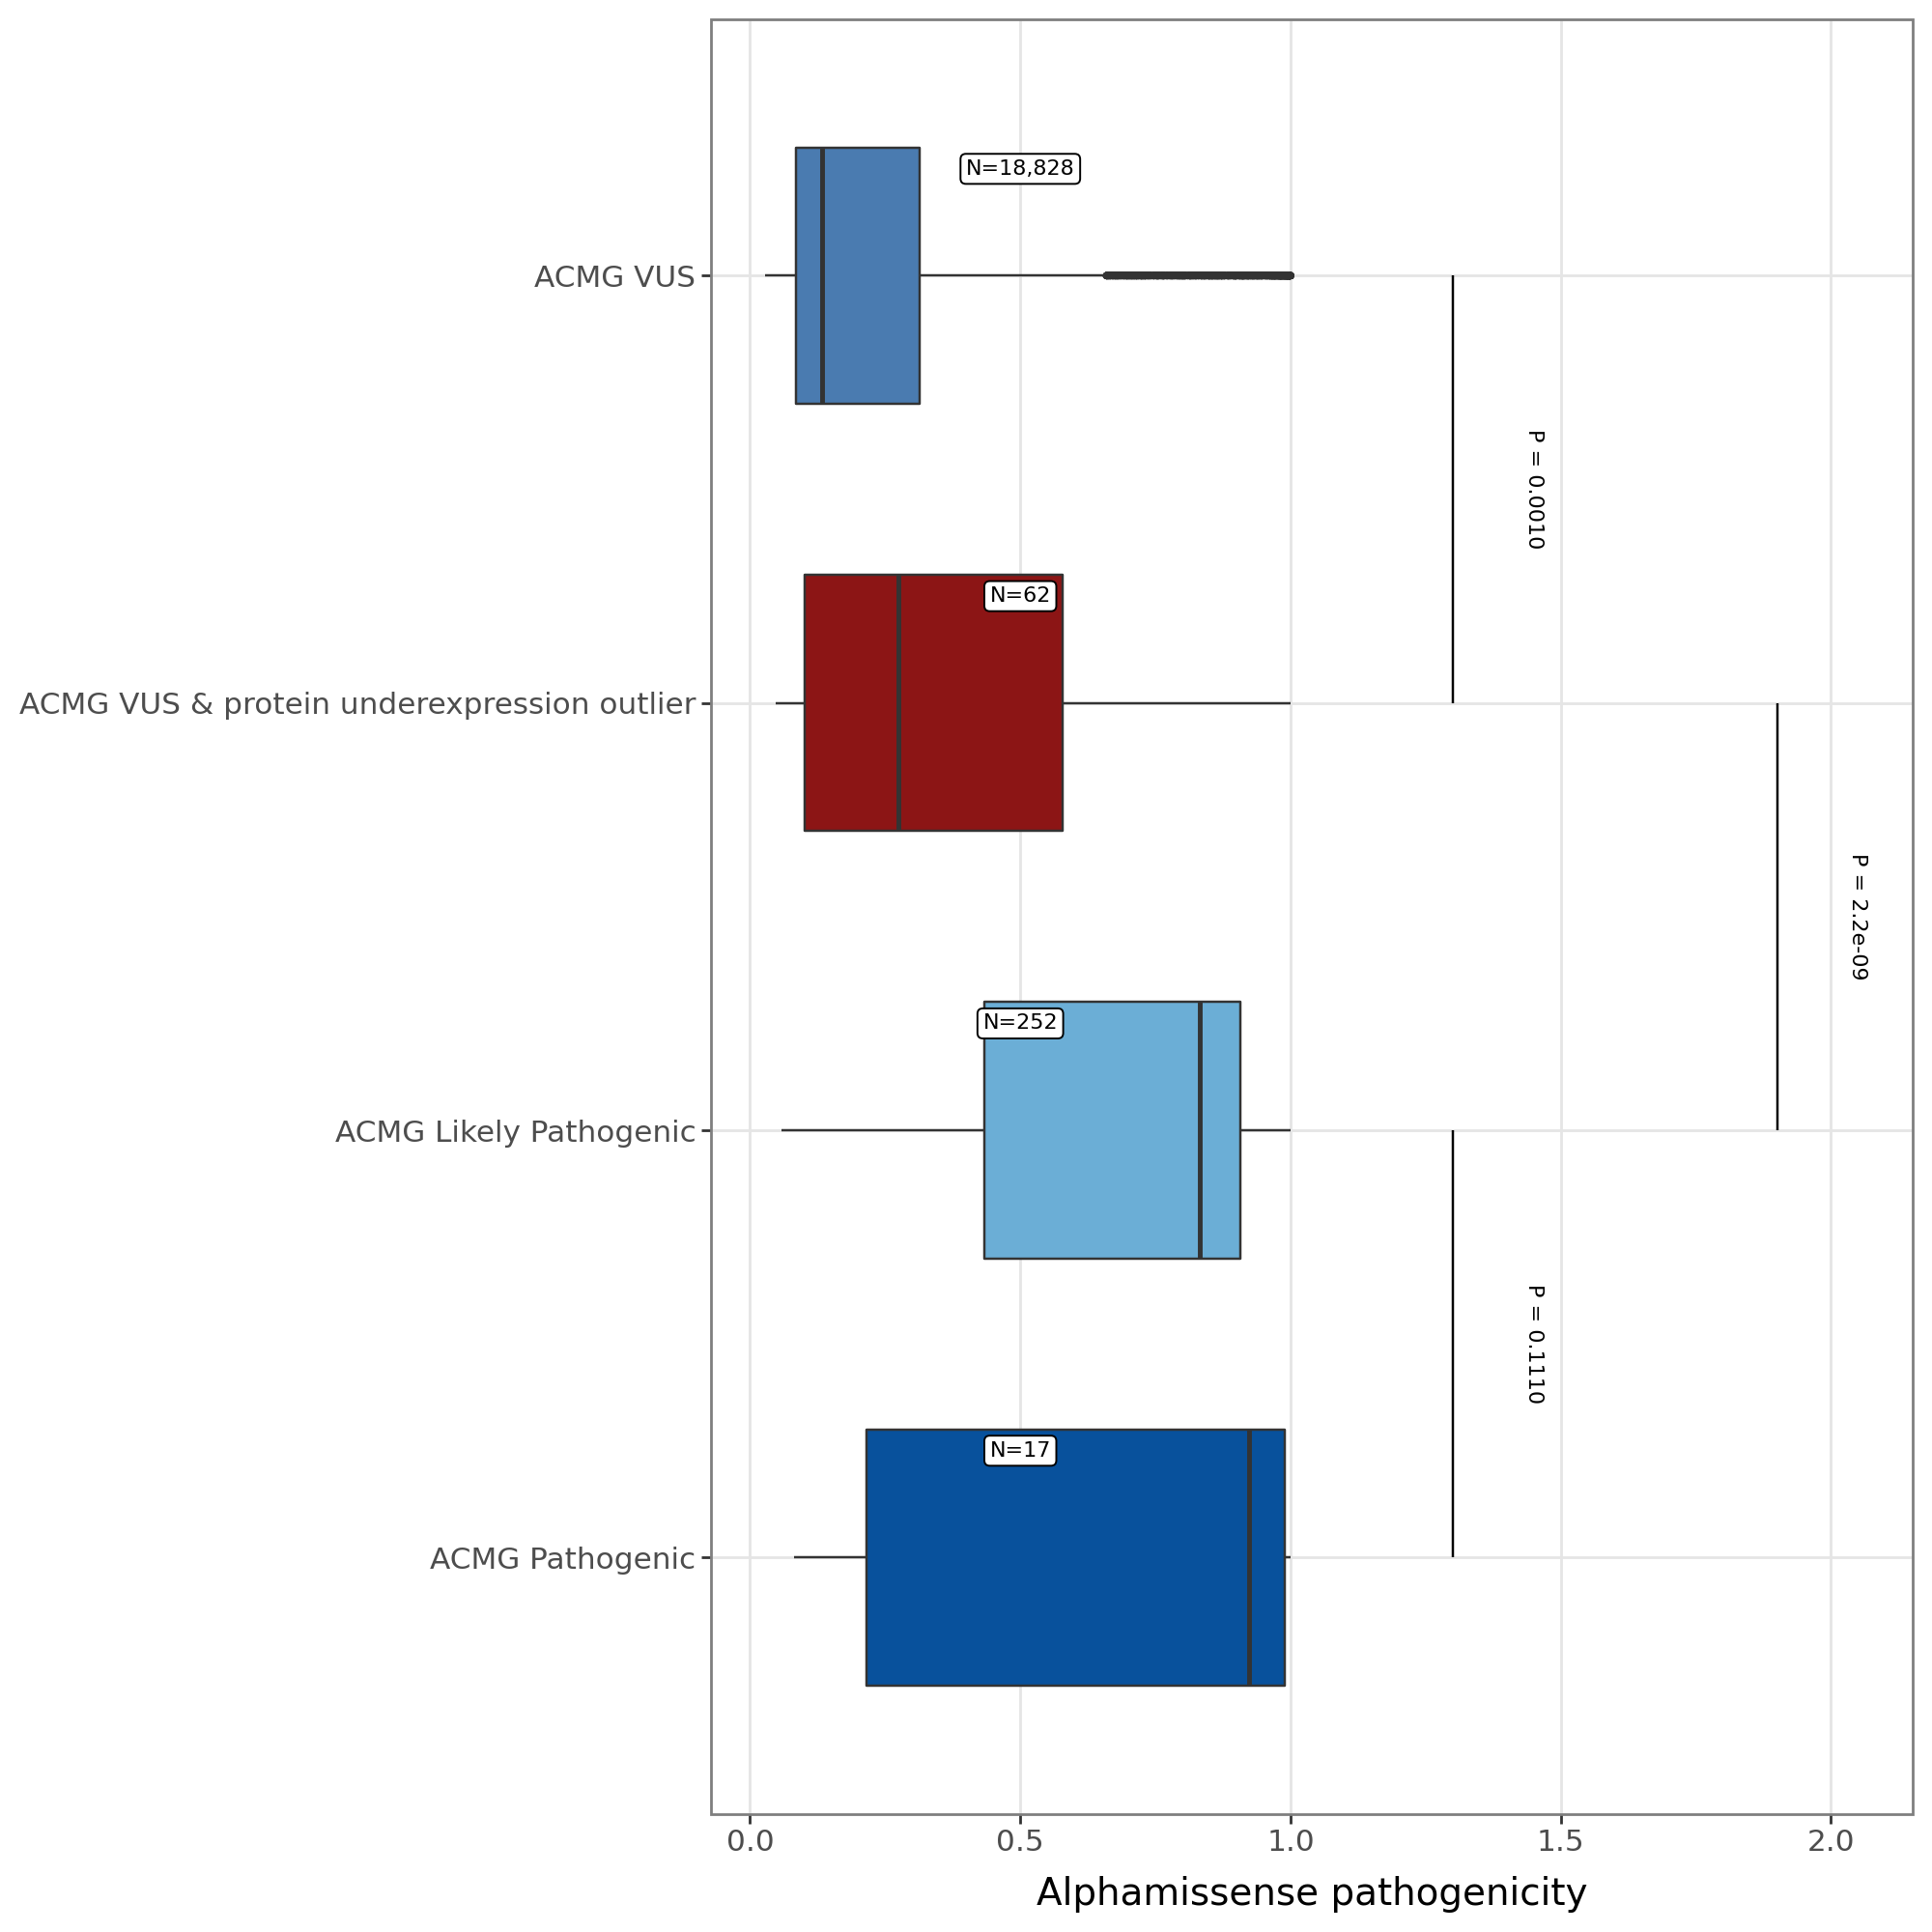

In [120]:


# 1. Categorization & 6-Group Creation
df_plot = pr_outliers_merged.copy()
df_plot["germline_am_pathogenicity"] = pd.to_numeric(
    df_plot["germline_am_pathogenicity"], errors="coerce"
)
df_plot = df_plot[abs(df_plot["germline_am_pathogenicity"]) >= 0]


# Define conditions with your exact new string labels
is_outlier = df_plot["Outlier status"]
is_vus = df_plot["ACMG_Classification"] == "Uncertain Significance"
is_lp = df_plot["ACMG_Classification"] == "Likely Pathogenic"
is_p = df_plot["ACMG_Classification"] == "Pathogenic"

conditions = [
    is_p & ~is_outlier,
    is_lp & ~is_outlier,
    is_vus & is_outlier,
    is_vus & ~is_outlier,
]

choices = [
    "ACMG Pathogenic",
    "ACMG Likely Pathogenic",
    "ACMG VUS & protein underexpression outlier",
    "ACMG VUS",
]

df_plot["plot_group_6"] = np.select(conditions, choices, default="ACMG VUS")

# Ordered for coord_flip(): 
# Index 0 (bottom of plot) -> Index 5 (top of plot)
group_order_6 = [
    
    "ACMG Pathogenic",
    "ACMG Likely Pathogenic",
    "ACMG VUS & protein underexpression outlier",
    "ACMG VUS",
]

df_plot["plot_group_6"] = pd.Categorical(
    df_plot["plot_group_6"], categories=group_order_6, ordered=True
)


def format_p(p):
    if np.isnan(p):
        return "N/A"
    return f"P = {p:.1e}" if p < 0.001 else f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby("plot_group_6", observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")
n_df["x_pos"] = n_df["plot_group_6"]
n_df["y_pos"] = 0.5

# 3. Compute stats for adjacent pairs in exact order
bracket_y_base = 1.3
bracket_y_stagger = 1.9

adjacent_stats = []
for i in range(len(group_order_6) - 1):
    g1 = group_order_6[i]
    g2 = group_order_6[i + 1]

    vals1 = df_plot[df_plot["plot_group_6"] == g1]["germline_am_pathogenicity"]
    vals2 = df_plot[df_plot["plot_group_6"] == g2]["germline_am_pathogenicity"]

    p_val = (
        mannwhitneyu(vals1, vals2, alternative="greater").pvalue
        if len(vals1) > 0 and len(vals2) > 0
        else np.nan
    )

    b_y = bracket_y_base if (i % 2 == 0) else bracket_y_stagger

    adjacent_stats.append(
        {
            "x_start": i + 1,
            "x_end": i + 2,
            "x_text": (i + 1) + 0.5,
            "p_label": format_p(p_val),
            "bracket_y": b_y,
            "text_y": b_y + 0.15,
        }
    )

stats_df = pd.DataFrame(adjacent_stats)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(x="plot_group_6", y="germline_am_pathogenicity", fill="plot_group_6"),
    )
    + pn.geom_boxplot(outlier_size=0.5, width=0.6)
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "ACMG VUS": "#4A7BB0",
            "ACMG VUS & protein underexpression outlier": "#8C1515",
            "ACMG Likely Pathogenic": "#6BAED6",
            "ACMG Pathogenic": "#08519C",
        },
        guide=None,
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(10, 10),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
    )
    + pn.labs(y="Alphamissense pathogenicity")
    # --- Adjacent Brackets & P-values ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        nudge_x=0.25,
        size=8,
        inherit_aes=False,
    )
    #+ pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

# gene splicing

In [91]:
all_res = []
# padjust_Genes_with_rare_splice_variants
for cohort in sa[sa["Diag"] != "Unstranded_data"]["Diag"].unique():

    splicing_res_path = f"/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/drop_runs/drop_master_202502_allGenes/processed_results/aberrant_splicing/results/v19/fraser/{cohort}/results_per_junction_dna_first.tsv"

    splicing_res_path = f"/omics/odcf/analysis/hipo/hipo_021/outlier_analysis/drop_runs/drop_master_202502_allGenes/processed_results/aberrant_splicing/results/v19/fraser/{cohort}/dna_first_results_predisp_tsg.parquet"
    lf = pl.scan_parquet(
        splicing_res_path,
    )
    if cohort == "Other":
        lf = lf.with_columns(
            pl.lit(None, dtype=pl.Float64).alias("padjust_Genes_with_rare_splice_variants")
        )
    
    fr_res_new =(lf
                    #.select("sampleID", "hgncSymbol", "pValue", "padjust", 'seqnames', 'start', 'end', 'strand', 'deltaPsi', 'counts', 'totalCounts', 'nonsplitCounts')
                    .filter(((pl.col("padjust_bh_dna_first_tsg_predisp") <= 0.1)) & (abs(pl.col("deltaPsi")) >= 0.15))
                    .collect(engine="streaming")
                    ).rename({"start": "junction_start", "end": "junction_end"}).to_pandas()
    # fr_res_new[(fr_res_new["padjust"] <= 0.05) & (fr_res_new["padjust_Genes_to_test_on_all_samples"].notna())]
    fr_res_new = fr_res_new.merge(sa, left_on="sampleID", right_on="pid")
    
    all_res.append(fr_res_new)
all_res = pd.concat(all_res)



In [95]:
all_res.shape

(3334, 114)

In [122]:
splicing_outliers_merged = dresden_germline.merge(all_res,  left_on=["PID", "SYMBOL"], right_on=["sampleID", "hgncSymbol"], how="left")


In [123]:
splicing_outliers_merged.shape

(2132449, 321)

In [124]:

splicing_outliers_merged["Outlier status"] = False

condition = (
    splicing_outliers_merged["POS"] >= splicing_outliers_merged["junction_start"] - 200
) & (
    splicing_outliers_merged["POS"] <= splicing_outliers_merged["junction_end"] + 200
)
splicing_outliers_merged.loc[(splicing_outliers_merged["junction_end"].notna()) & 
    (splicing_outliers_merged["totalCounts"] >= 10) & condition
    , "Outlier status"] = True

splicing_outliers_merged = splicing_outliers_merged.sort_values("Outlier status", ascending=False).drop_duplicates(subset=["#CHROM", "POS", "REF", "ALT", "Gene", "PID"])
print(splicing_outliers_merged.shape)

(2127488, 322)


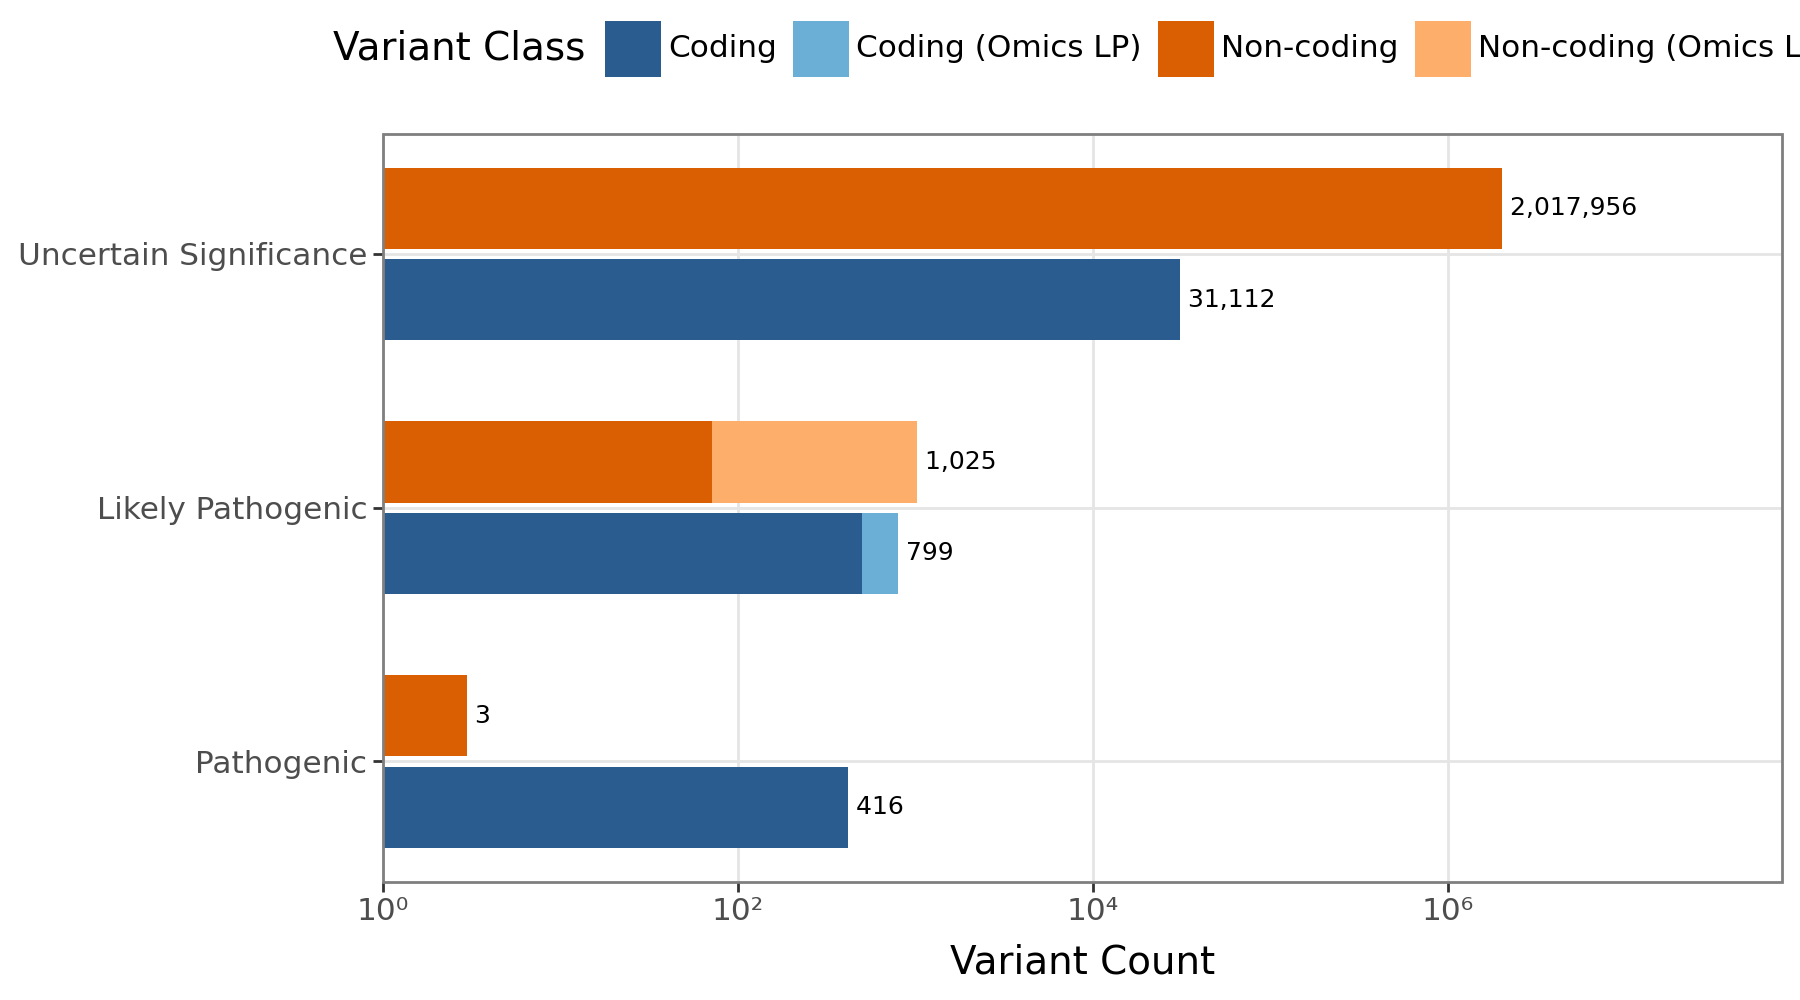

In [59]:

# 1. Start with data, deduplicate, and identify Outliers
df_data = splicing_outliers_merged.copy()
df_data = df_data.drop_duplicates(
    subset=["PID", "SYMBOL", "#CHROM", "POS", "REF", "ALT"]
)

df_data["germline_Consequence"] = df_data["germline_Consequence"].fillna("")

is_outlier = (
    (df_data["germline_max_spliceai_score"] >= 0.1)
    | (df_data["germline_Consequence"].str.contains("spl"))
    | (df_data["germline_AbSplice2_max"] >= 0.1)
    | (df_data["germline_pangolin_score"] >= 0.1)
) & (df_data["padjust_bh_dna_first_tsg_predisp"] <= 0.1)

# 2. Reclassify VUS Outliers -> "Likely Pathogenic (Omics LP)"
df_data["ACMG_reclassified"] = df_data["germline_ACMG_Classification"].astype(
    str
)

vus_outliers_mask = (
    df_data["germline_ACMG_Classification"] == "Uncertain Significance"
) & is_outlier

df_data.loc[vus_outliers_mask, "ACMG_reclassified"] = (
    "Likely Pathogenic (Omics LP)"
)

# 3. Aggregate counts
df_counts = (
    df_data.groupby(
        ["variant_class", "ACMG_reclassified"], observed=False
    )
    .size()
    .reset_index(name="count")
)
df_counts = df_counts[df_counts["count"] > 0].copy()

# 4. Define category mapping & plot axes
df_counts["ACMG_plot_axis"] = df_counts["ACMG_reclassified"].replace(
    {"Likely Pathogenic (Omics LP)": "Likely Pathogenic"}
)

df_counts["fill_group"] = df_counts["variant_class"].astype(str)
df_counts.loc[
    df_counts["ACMG_reclassified"] == "Likely Pathogenic (Omics LP)",
    "fill_group",
] = (df_counts["variant_class"].astype(str) + " (Omics LP)")

# Map categorical Y-axis values to integers (1, 2, 3)
acmg_map = {
    "Pathogenic": 1,
    "Likely Pathogenic": 2,
    "Uncertain Significance": 3,
}
df_counts["x_numeric"] = df_counts["ACMG_plot_axis"].map(acmg_map)

# Order fill levels (Base first, then Omics LP)
fill_order = [
    "Coding",
    "Coding (Omics LP)",
    "Non-coding",
    "Non-coding (Omics LP)",
]
df_counts["fill_group"] = pd.Categorical(
    df_counts["fill_group"], categories=fill_order, ordered=True
)

# Sort to calculate cumulative bounds correctly
df_counts = df_counts.sort_values(
    ["variant_class", "x_numeric", "fill_group"]
)

# Calculate cumulative start (ymin) and end (ymax) for stacked segments
df_counts["ymax"] = df_counts.groupby(["variant_class", "x_numeric"])[
    "count"
].cumsum()
df_counts["ymin"] = df_counts["ymax"] - df_counts["count"]

# Make ymin = 1 for log scale rendering if it starts at 0
df_counts["ymin"] = df_counts["ymin"].replace(0, 1)

# Calculate manual X positions (Dodging Coding vs Non-coding)
bar_width = 0.32
dodge_offset = 0.18

# Coding sits at (x - dodge_offset), Non-coding at (x + dodge_offset)
df_counts["x_center"] = np.where(
    df_counts["variant_class"] == "Coding",
    df_counts["x_numeric"] - dodge_offset,
    df_counts["x_numeric"] + dodge_offset,
)
df_counts["xmin"] = df_counts["x_center"] - (bar_width / 2)
df_counts["xmax"] = df_counts["x_center"] + (bar_width / 2)

# Calculate total bar heights for end labels
df_labels = (
    df_counts.groupby(["variant_class", "x_numeric", "x_center"])[
        "count"
    ]
    .sum()
    .reset_index(name="total_count")
)
df_labels["label"] = df_labels["total_count"].apply(lambda x: f"{x:,}")

# 5. Color Palette Mapping
color_palette = {
    "Coding": "#2b5c8f",  # Dark Blue (Base 502)
    "Coding (Omics LP)": "#6baed6",  # Light Blue (Stacked VUS outliers 297)
    "Non-coding": "#d95f02",  # Dark Orange (Base 72)
    "Non-coding (Omics LP)": "#fdae6b",  # Light Orange (Stacked VUS outliers 953)
}

superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

# 6. Build Plot using geom_rect
p = (
    pn.ggplot()
    + pn.geom_rect(
        df_counts,
        pn.aes(
            xmin="xmin",
            xmax="xmax",
            ymin="ymin",
            ymax="ymax",
            fill="fill_group",
        ),
    )
    + pn.coord_flip()
    # Add end-of-bar text labels
    + pn.geom_text(
        df_labels,
        pn.aes(x="x_center", y="total_count", label="label"),
        ha="left",
        va="center",
        size=9,
        format_string=" {}",
    )
    + pn.scale_x_continuous(
        breaks=[1, 2, 3],
        labels=["Pathogenic", "Likely Pathogenic", "Uncertain Significance"],
    )
    + pn.scale_y_log10(
        expand=(0, 0, 0.25, 0),
        labels=lambda ticks: [
            f"10{str(int(np.log10(t))).translate(superscript_map)}"
            if t > 0
            else "0"
            for t in ticks
        ],
    )
    + pn.scale_fill_manual(values=color_palette, name="Variant Class")
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(9, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="Variant Count")
)

p

In [129]:
dresden_germline[(dresden_germline["germline_max_spliceai_score"] >= 0.1) 
    | (dresden_germline["germline_Consequence"].str.contains("spl")) 
    | (dresden_germline["germline_AbSplice2_max"] >= 0.1 ) 
    | (dresden_germline["germline_pangolin_score"] >= 0.1 ) 
    ].shape

(18411, 207)

(445, 322)

In [130]:
splicing_outliers_merged.shape
splicing_vars = splicing_outliers_merged[((splicing_outliers_merged["germline_max_spliceai_score"] >= 0.1) 
    | (splicing_outliers_merged["germline_Consequence"].str.contains("spl")) 
    | (splicing_outliers_merged["germline_AbSplice2_max"] >= 0.1 ) 
    | (splicing_outliers_merged["germline_pangolin_score"] >= 0.1 ) )
    & (splicing_outliers_merged["Outlier status"] == True)
    ]



splicing_vars["germline_ACMG_Classification"].value_counts(dropna=False)
# # splicing_vars["germline_ACMG_Classification"].shape
splicing_vars[splicing_vars["hgncSymbol"].isin(AD_inheritence["gene_name"])]["germline_ACMG_Classification"].value_counts()

# splicing_vars[splicing_vars["hgncSymbol"].isin(AD_inheritence["gene_name"])].shape

Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


In [132]:
as_tsg_predisp_samples = splicing_vars[(splicing_vars["germline_ACMG_Classification"] == "Uncertain Significance")]["PID"].unique()
as_AD_samples = splicing_vars[(splicing_vars["hgncSymbol"].isin(AD_inheritence["gene_name"])) & (splicing_vars["germline_ACMG_Classification"] == "Uncertain Significance")]["PID"].unique()
as_tsg_predisp_samples

<ArrowStringArray>
[ 'HBTTLZ',  'LJ5YBQ',  'BGKUKA',  '1J5FQ6',  'ZMDTAW',  'NVZWK5',  '5R9UHP',
  'BPGAZA',  'B4TMLR',  'VJLEN9',
 ...
 '8XMJ4MY',  'LDFMN4',  'L7L8KS',  'BDNR5D',  'LCC5GK',  'DFTVN1',  '3ZMYX1',
  'BFEMLP',  'NYSDZE',  '87YEH6']
Length: 328, dtype: str

In [131]:
splicing_vars_tsg = splicing_vars[(splicing_vars["Outlier status"] == True) & 
    (splicing_vars["germline_ACMG_Classification"] == "Uncertain Significance") ]
splicing_vars_tsg['variant_class'] = splicing_vars['germline_Consequence'].str.contains(
    coding_pattern, 
    regex=True, 
    na=False
).map({True: 'Coding', False: 'Non-coding'})
splicing_vars_tsg["Omic"] = "Gene splicing outlier"
splicing_vars_tsg["variant_class"].value_counts(dropna=False)


Loading ITables v2.5.2 from the init_notebook_mode cell... (need help?)


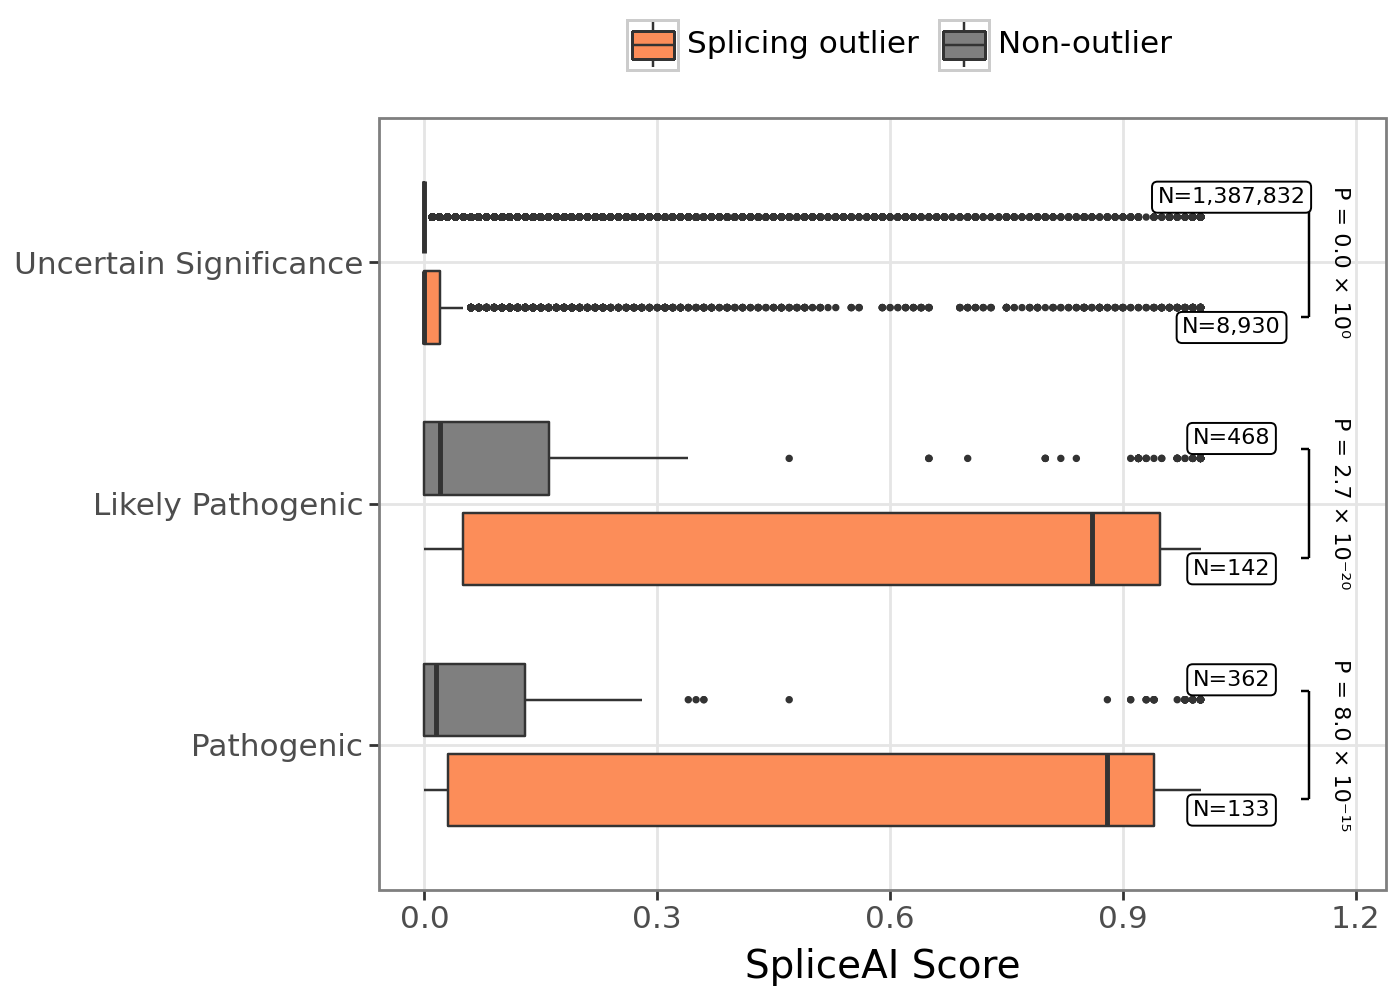

In [45]:

# 1. Preprocessing & Clean Categorization
df_plot = splicing_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_max_spliceai_score"]) >= 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Splicing outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Splicing outlier", "Non-outlier"],
    ordered=True,
)

acmg_order_3 = ["Pathogenic", "Likely Pathogenic",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 1.04

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.01  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_max_spliceai_score"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Splicing outlier"
    ]["germline_max_spliceai_score"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="greater").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.14

    stats_list.append(
        {
            "ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.04,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="ACMG_Classification",
            y="germline_max_spliceai_score",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Splicing outlier": "#fc8d59",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="SpliceAI Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    #+ pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

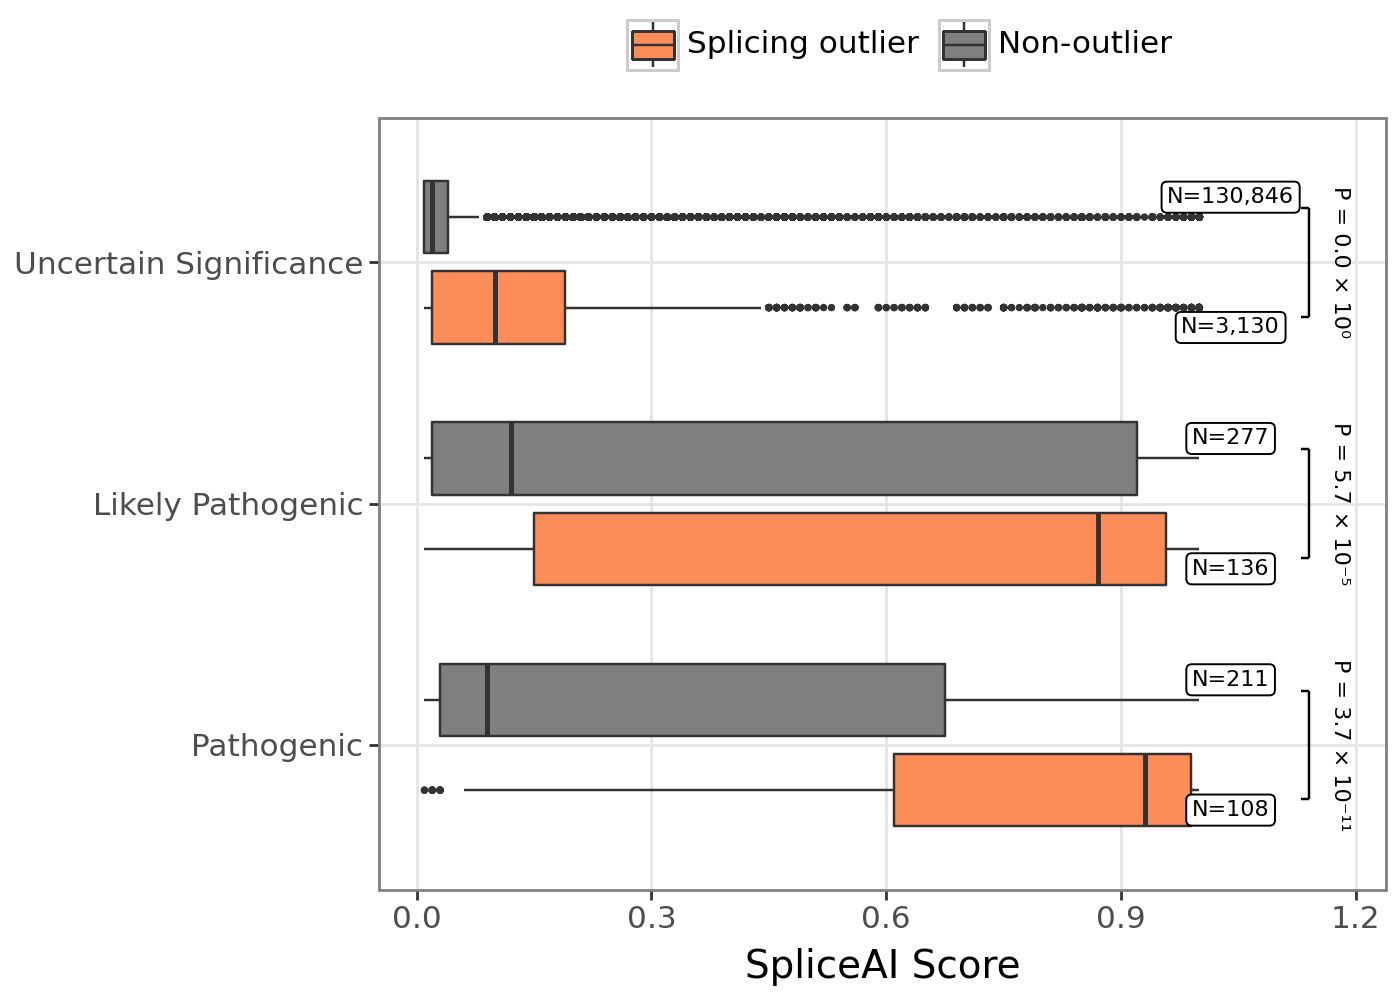

In [46]:


# 1. Preprocessing & Clean Categorization
df_plot = splicing_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_max_spliceai_score"]) > 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Splicing outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Splicing outlier", "Non-outlier"],
    ordered=True,
)

acmg_order_3 = ["Pathogenic", "Likely Pathogenic",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 1.04

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.01  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_max_spliceai_score"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Splicing outlier"
    ]["germline_max_spliceai_score"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="greater").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.14

    stats_list.append(
        {
            "ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.04,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="ACMG_Classification",
            y="germline_max_spliceai_score",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Splicing outlier": "#fc8d59",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="SpliceAI Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    #+ pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

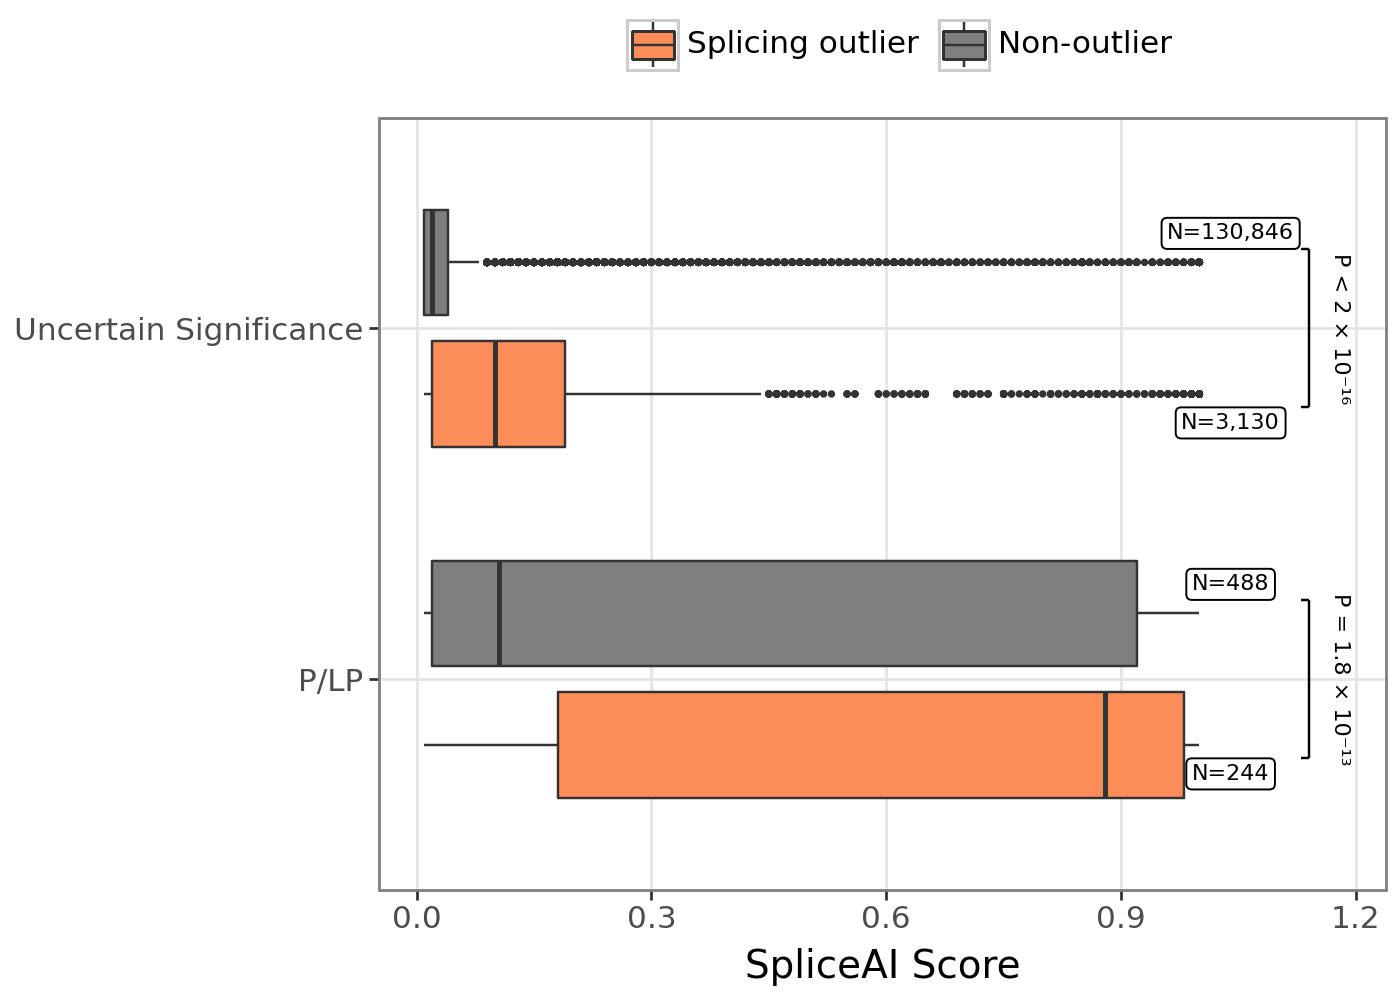

In [50]:


# 1. Preprocessing & Clean Categorization
df_plot = splicing_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_max_spliceai_score"]) > 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Splicing outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Splicing outlier", "Non-outlier"],
    ordered=True,
)

df_plot.loc[df_plot["germline_ACMG_Classification"] == "Pathogenic", "germline_ACMG_Classification"] = "Likely Pathogenic"
df_plot.loc[df_plot["germline_ACMG_Classification"] == "Likely Pathogenic", "germline_ACMG_Classification"] = "P/LP"


acmg_order_3 = ["P/LP",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    elif p == 0:
        exponent_val = int(-16)
        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)
        return f"P < 2 × 10{sup_str}"
    elif p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 1.04

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.01  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_max_spliceai_score"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Splicing outlier"
    ]["germline_max_spliceai_score"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="greater").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.14

    stats_list.append(
        {
            "ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.04,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="ACMG_Classification",
            y="germline_max_spliceai_score",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Splicing outlier": "#fc8d59",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="SpliceAI Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    #+ pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

In [ ]:

# 1. Preprocessing & Clean Categorization
df_plot = splicing_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_max_spliceai_score"]) > 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Splicing outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Splicing outlier", "Non-outlier"],
    ordered=True,
)

acmg_order_3 = ["Pathogenic", "Likely Pathogenic",  "Uncertain Significance",]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 1.04

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.01  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_max_spliceai_score"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Splicing outlier"
    ]["germline_max_spliceai_score"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="greater").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.14

    stats_list.append(
        {
            "ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.04,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="ACMG_Classification",
            y="germline_max_spliceai_score",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Splicing outlier": "#fc8d59",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="SpliceAI Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    #+ pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

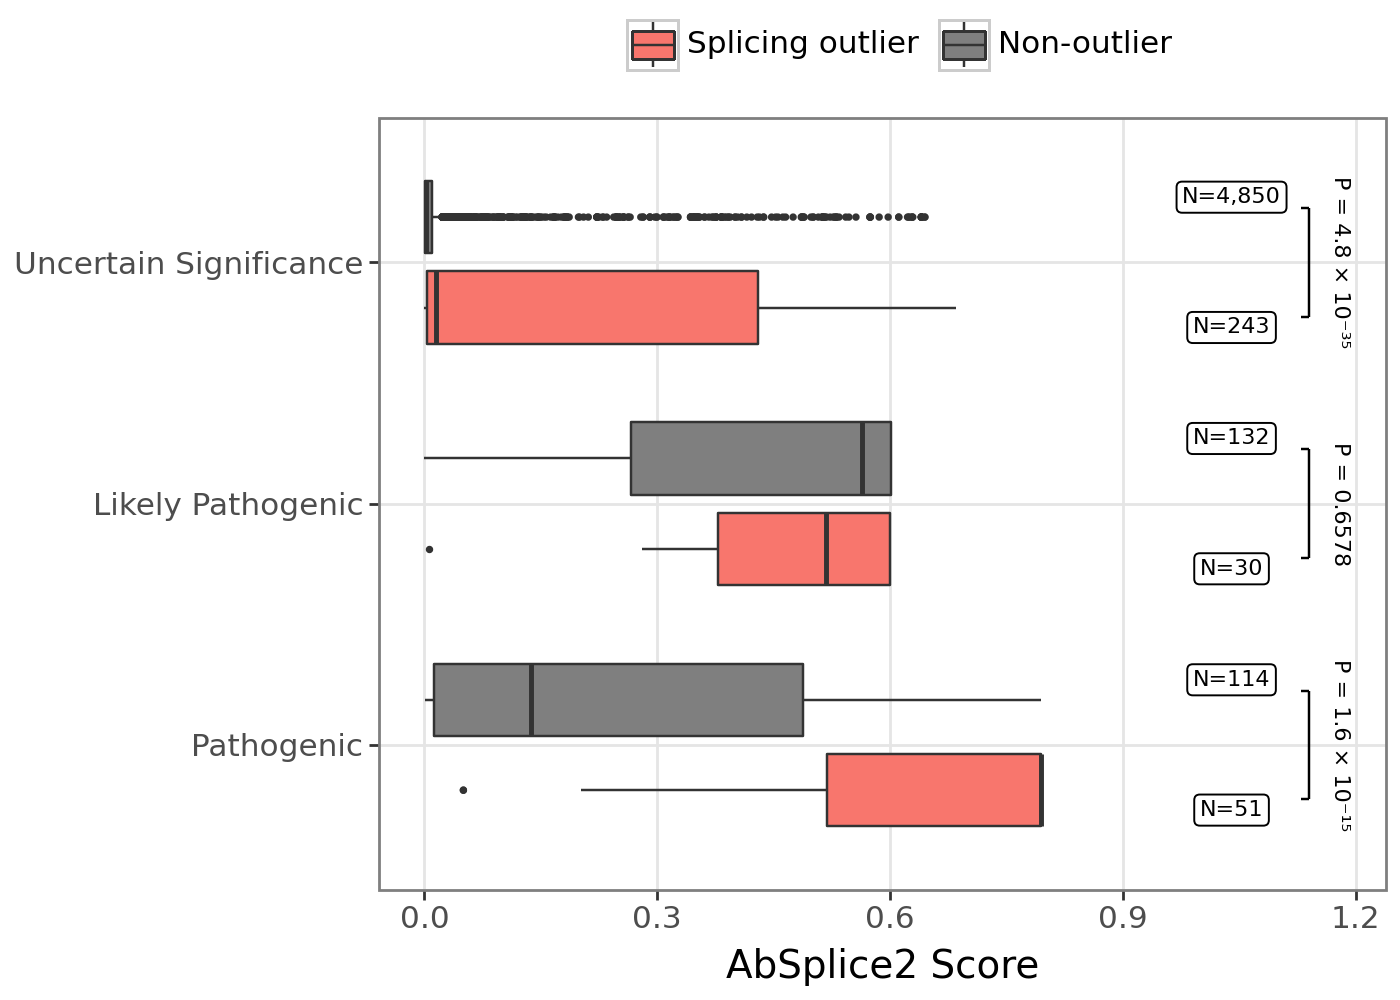

In [118]:


# 1. Preprocessing & Clean Categorization
df_plot = splicing_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_AbSplice2_max"]) > 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Splicing outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Splicing outlier", "Non-outlier"],
    ordered=True,
)

acmg_order_3 = ["Pathogenic", "Likely Pathogenic",  "Uncertain Significance"]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 1.04

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.01  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_AbSplice2_max"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Splicing outlier"
    ]["germline_AbSplice2_max"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="greater").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.14

    stats_list.append(
        {
            "ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.04,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="ACMG_Classification",
            y="germline_AbSplice2_max",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Splicing outlier": "#f8766d",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="AbSplice2 Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    #+ pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p

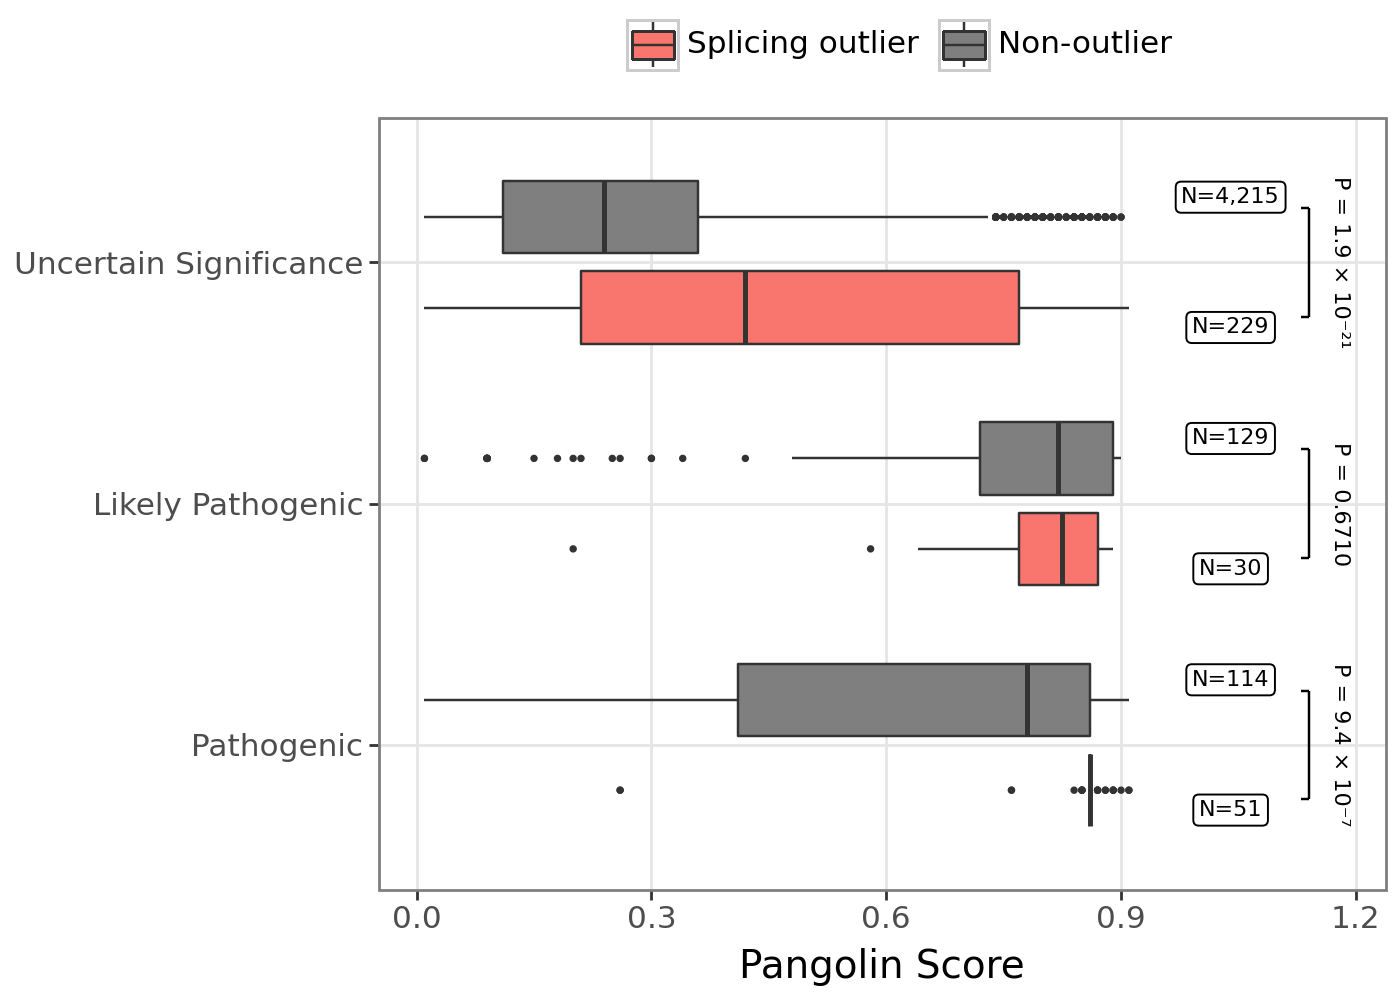

In [119]:

# 1. Preprocessing & Clean Categorization
df_plot = splicing_outliers_merged.copy()
df_plot = df_plot[abs(df_plot["germline_pangolin_score"]) > 0]

df_plot["Outlier_Label"] = np.where(
    df_plot["Outlier status"], "Splicing outlier", "Non-outlier"
)

df_plot["Outlier_Label"] = pd.Categorical(
    df_plot["Outlier_Label"],
    categories=["Splicing outlier", "Non-outlier"],
    ordered=True,
)

acmg_order_3 = ["Pathogenic", "Likely Pathogenic",  "Uncertain Significance"]

df_plot = df_plot[df_plot["germline_ACMG_Classification"].isin(acmg_order_3)].copy()
df_plot["ACMG_Classification"] = pd.Categorical(
    df_plot["germline_ACMG_Classification"], categories=acmg_order_3, ordered=True
)

acmg_to_x = {cat: float(i + 1) for i, cat in enumerate(acmg_order_3)}


def format_p(p):
    if np.isnan(p):
        return "N/A"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        exponent_val = int(exponent)

        # Unicode superscript mapping
        superscript_map = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        sup_str = str(exponent_val).translate(superscript_map)

        return f"P = {mantissa} × 10{sup_str}"
    return f"P = {p:.4f}"


# 2. Setup N labels
n_df = (
    df_plot.groupby(["ACMG_Classification", "Outlier_Label"], observed=False)
    .size()
    .reset_index(name="count")
)
n_df["label"] = n_df["count"].apply(lambda n: f"N={n:,}")

n_df["x_num"] = n_df["ACMG_Classification"].map(acmg_to_x).astype(float)
n_df["offset"] = np.where(n_df["Outlier_Label"] == "Non-outlier", 0.27, -0.27)
n_df["x_pos"] = n_df["x_num"] + n_df["offset"]
n_df["y_pos"] = 1.04

# 3. Compute Stats & Bracket Coordinates (main horizontal bar + end ticks)
stats_list = []
tick_length = 0.01  # Length of the little end ticks pointing left toward the boxes

for acmg_cat in acmg_order_3:
    sub_df = df_plot[df_plot["ACMG_Classification"] == acmg_cat]

    vals_non = sub_df[sub_df["Outlier_Label"] == "Non-outlier"][
        "germline_pangolin_score"
    ]
    vals_out = sub_df[
        sub_df["Outlier_Label"] == "Splicing outlier"
    ]["germline_pangolin_score"]

    p_val = (
        mannwhitneyu(vals_out, vals_non, alternative="greater").pvalue
        if len(vals_non) > 0 and len(vals_out) > 0
        else np.nan
    )

    x_center = acmg_to_x[acmg_cat]
    x_bottom = x_center - 0.225
    x_top = x_center + 0.225
    bracket_y = 1.14

    stats_list.append(
        {
            "ACMG_Classification": acmg_cat,
            # Main vertical line segment (in coord_flip space, y is horizontal position)
            "x_start": x_bottom,
            "x_end": x_top,
            "bracket_y": bracket_y,
            "text_y": bracket_y + 0.04,
            "x_text": x_center,
            "p_label": format_p(p_val),
            # End tick 1 (bottom box end)
            "tick1_x": x_bottom,
            "tick1_y_start": bracket_y,
            "tick1_y_end": bracket_y - tick_length,
            # End tick 2 (top box end)
            "tick2_x": x_top,
            "tick2_y_start": bracket_y,
            "tick2_y_end": bracket_y - tick_length,
        }
    )

stats_df = pd.DataFrame(stats_list)

# 4. Plotting
p = (
    pn.ggplot(
        df_plot,
        pn.aes(
            x="ACMG_Classification",
            y="germline_pangolin_score",
            fill="Outlier_Label",
        ),
    )
    + pn.geom_boxplot(
        outlier_size=0.5,
        width=0.6,
        position=pn.position_dodge(width=0.75),
    )
    + pn.coord_flip()
    + pn.scale_fill_manual(
        values={
            "Splicing outlier": "#f8766d",
            "Non-outlier": "#7f7f7f",
        },
        name=" ",
    )
    + pn.theme_bw(base_size=14)
    + pn.theme(
        figure_size=(7, 5),
        axis_title_y=pn.element_blank(),
        panel_grid_minor=pn.element_blank(),
        legend_position="top",
    )
    + pn.labs(y="Pangolin Score")
    # --- Statistical Bracket Main Line ---
    + pn.geom_segment(
        pn.aes(x="x_start", xend="x_end", y="bracket_y", yend="bracket_y"),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- Bracket End Ticks (Bottom & Top) ---
    + pn.geom_segment(
        pn.aes(
            x="tick1_x",
            xend="tick1_x",
            y="tick1_y_start",
            yend="tick1_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    + pn.geom_segment(
        pn.aes(
            x="tick2_x",
            xend="tick2_x",
            y="tick2_y_start",
            yend="tick2_y_end",
        ),
        data=stats_df,
        color="black",
        inherit_aes=False,
    )
    # --- P-value Text ---
    + pn.geom_text(
        pn.aes(x="x_text", y="text_y", label="p_label"),
        data=stats_df,
        size=8,
        angle=270,
        inherit_aes=False,
    )
    # --- N Count Labels ---
    + pn.geom_label(
        pn.aes(x="x_pos", y="y_pos", label="label"),
        data=n_df,
        fill="white",
        size=8,
        inherit_aes=False,
    )
    #+ pn.scale_y_continuous(limits=(-6, 2.5), expand=(0.02, 0, 0.02, 0))
)

p